# A topologia do EEG muda em uma crise epiléptica?

**Projeto 5 — Análise Topológica de Dados (SME0231/SME5987)**
Reconstrução de Takens → complexo de Vietoris–Rips → homologia persistente em $H_1$, aplicados ao EEG do banco público CHB-MIT.

Este notebook refaz o projeto do começo ao fim, com o código à vista e comentado passo a passo. Ele é autossuficiente: instala as bibliotecas, baixa os dados do PhysioNet e gera todas as figuras e tabelas.

**A pergunta.** Uma crise epiléptica costuma aparecer no EEG como atividade rítmica. Um sinal rítmico, visto no espaço de Takens, desenha um laço, e laços são exatamente o que $H_1$ mede. Então: *a persistência de $H_1$ muda de forma sistemática entre janelas **interictais** (longe da crise), **pré-ictais** (pouco antes) e **ictais** (durante a crise)?*

**A resposta, adiantada.** Com estes dados, não de forma útil. O corpo do notebook (Seções 1 a 10) estuda a fundo um paciente com duas crises; a Seção 11 repete o essencial em três pacientes e 14 crises, com treino e teste em pacientes diferentes, e chega à mesma conclusão. A persistência máxima de $H_1$ quase não separa janelas ictais de interictais, enquanto um descritor simples de amplitude separa muito bem. O caminho até essa conclusão é o conteúdo do notebook, e inclui uma armadilha instrutiva: um "efeito de gravação" que faz vários descritores parecerem bons quando não são.

### Como usar

1. Menu **Ambiente de execução → Executar tudo**. Não precisa de GPU.
2. As saídas já vêm salvas: dá para ler tudo sem executar nada.
3. A Seção 0.2 tem cinco interruptores para trocar velocidade por fidelidade ao projeto original.

**Quanto demora.** Em um computador limitado a 2 núcleos, como o Colab, a execução completa levou cerca de 4 minutos, sem contar o download dos dados (297 MB do PhysioNet, que pode levar de segundos a vários minutos conforme o servidor). Os núcleos do Colab costumam ser mais lentos, então conte com algo entre 5 e 10 minutos. As partes mais demoradas são a varredura da Seção 9 e as animações da Seção 10, que podem ser desligadas. A Seção 11 baixa mais 63 gravações (cerca de 2,5 GB) e acrescenta vários minutos; ela também tem um interruptor.

### Roteiro

| Seção | Conteúdo | No repositório do projeto |
|---|---|---|
| 0 | Preparação: bibliotecas, parâmetros, estilo | `requirements.txt`, `tda_eeg/config.py`, `estilo.py` |
| 1 | As ideias em sinais sintéticos: Takens, Vietoris–Rips, $H_1$, descritores | `tda_eeg/takens.py`, `topologia.py`, `scripts/01` |
| 2 | Os dados: CHB-MIT, pré-processamento, janelas e rótulos | `tda_eeg/dados.py` |
| 3 | Como escolher $\tau$ e $d$ | `scripts/02` |
| 4 | O pipeline em todas as janelas | `tda_eeg/extracao.py`, `baseline.py`, `scripts/03` |
| 5 | $H_1$ ao longo do tempo × anotações de crise | `scripts/04` |
| 6 | Detecção de crises com aprendizado de máquina | `scripts/05`, `tda_eeg/avaliacao.py` |
| 7 | Previsão (exploratório) | `scripts/06` |
| 8 | Mapper (exploratório) | `scripts/07` |
| 9 | Sensibilidade ao canal e a $(d, \tau)$ | `scripts/08` |
| 10 | Animações | `scripts/09` |
| 11 | Outros pacientes e a definição supervisionada do enunciado | `scripts/10`, `11` e `12` |
| 12 | Conclusões e limitações | `README.md` |

Ao longo do texto, três marcadores se repetem: **Intuição** (a ideia antes da fórmula), **O que observar** (como ler a figura ou a tabela logo acima) e **Experimente** (uma alteração pequena para testar por conta própria).

## 0. Preparação

### 0.1 Bibliotecas

O Colab já traz NumPy, SciPy, pandas, Matplotlib e scikit-learn. Faltam quatro pacotes:

| Pacote | Para quê |
|---|---|
| `gudhi` | complexo de Vietoris–Rips, persistência e distância de bottleneck |
| `ripser` | a mesma persistência do Rips, muito mais rápido (usado nas varreduras grandes) |
| `mne` | leitura dos arquivos EDF de EEG, filtro e reamostragem |
| `kmapper` | algoritmo Mapper |

A célula abaixo instala só o que estiver faltando.

In [1]:
import importlib
import importlib.util
import subprocess
import sys

PACOTES = {"gudhi": "gudhi", "ripser": "ripser", "mne": "mne", "kmapper": "kmapper"}   # módulo -> nome no pip
faltando = [pip for modulo, pip in PACOTES.items() if importlib.util.find_spec(modulo) is None]
if faltando:
    print("Instalando:", ", ".join(faltando))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltando])
    importlib.invalidate_caches()
print("Bibliotecas prontas.")

Bibliotecas prontas.


### 0.2 Interruptores

Cinco escolhas que mudam o tempo de execução, não o método.

- **`MOTOR_EXTRACAO`**: o projeto original calcula a persistência com o GUDHI, como no código-modelo do enunciado. O Ripser calcula a mesma coisa mais de dez vezes mais rápido (a equivalência e os tempos são conferidos na Seção 4.3). O Colab tem só 2 núcleos, então o padrão aqui é `"ripser"`; com `"gudhi"` a extração da Seção 4 fica cerca de vinte vezes mais demorada (de meio minuto para algo como dez minutos em 2 núcleos).
- **`RODAR_FLORESTA`**: repete a detecção da Seção 6 com floresta aleatória, além da regressão logística.
- **`RODAR_SENSIBILIDADE`**: a varredura de 20 pares $(d,\tau)$ e 21 canais da Seção 9. É a parte mais demorada.
- **`GERAR_ANIMACOES`**: os dois GIFs da Seção 10.
- **`RODAR_MULTIPACIENTE`**: a Seção 11, que baixa as gravações de chb02 e chb03 e o restante do chb01 (cerca de 2,5 GB) e repete o pipeline nelas. Desligue se quiser só a análise do chb01.

In [2]:
MOTOR_EXTRACAO = "ripser"  # @param ["ripser", "gudhi"]
RODAR_FLORESTA = False  # @param {type:"boolean"}
RODAR_SENSIBILIDADE = True  # @param {type:"boolean"}
GERAR_ANIMACOES = True  # @param {type:"boolean"}
RODAR_MULTIPACIENTE = True  # @param {type:"boolean"}

In [3]:
import os
import re
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, field
from itertools import combinations
from pathlib import Path
from urllib.parse import quote

import gudhi
import kmapper as km
import matplotlib as mpl
import matplotlib.pyplot as plt
import mne
import networkx as nx
import numpy as np
import pandas as pd
import requests
import sklearn
from IPython.display import Image, display
from joblib import Parallel, delayed
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.collections import EllipseCollection, LineCollection, PolyCollection
from matplotlib.patches import Patch, Rectangle
from ripser import ripser
from scipy.signal import butter, periodogram, sosfiltfilt
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist, squareform
from sklearn.base import clone
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix,
                             roc_auc_score, roc_curve)
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

mne.set_log_level("ERROR")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | gudhi {gudhi.__version__} | "
      f"mne {mne.__version__} | scikit-learn {sklearn.__version__}")

Python 3.11.9 | numpy 2.4.4 | gudhi 3.13.0 | mne 1.13.2 | scikit-learn 1.7.2


### 0.3 Parâmetros

Todos os parâmetros ficam em um só lugar e foram fixados **antes** de olhar para qualquer métrica de desempenho. Canal, banda, taxa de amostragem, janela, $d$ e $\tau$ são os do código-modelo do enunciado.

| Parâmetro | Valor | Significado |
|---|---|---|
| `CANAL` | FP1-F7 | derivação bipolar frontal esquerda |
| `BANDA` | 1–30 Hz | passa-faixa: tira a deriva lenta e o ruído muscular e de rede |
| `FS` | 64 Hz | taxa depois da reamostragem (o original é 256 Hz) |
| `JANELA_S`, `PASSO_S` | 8 s, 4 s | janelas de 8 s que avançam de 4 em 4 s (50 % de sobreposição) |
| `DIM`, `ATRASO` | 3, 4 | dimensão de imersão $d$ e atraso $\tau$ em amostras (4/64 Hz = 62,5 ms) |
| `PASSO_NUVEM` | 4 | usa 1 a cada 4 pontos da nuvem (126 pontos por janela) |
| `HORIZONTE_PRE_S` | 600 s | o que conta como "pré-ictal": os 10 min antes da crise |
| `EXCLUSAO_POS_S` | 600 s | os 10 min depois da crise ficam fora de todas as comparações |

**Experimente.** Depois de ler o notebook, troque `CANAL`, `DIM` ou `ATRASO` aqui e use *Executar tudo* de novo. Trocar só nesta célula e reexecutar uma seção do meio não basta, porque várias funções guardam esses valores como padrão no momento em que são definidas.

In [4]:
# --- Dados -------------------------------------------------------------------
# onde ficam os EDF; se você já os tem, aponte para a sua pasta (ou defina a variável CHBMIT_DIR)
DIR_DADOS = Path(os.environ.get("CHBMIT_DIR", "dados_chbmit"))
DIR_SAIDA = Path("resultados_colab")     # GIFs e HTML do Mapper
URL_RAIZ = "https://physionet.org/files/chbmit/1.0.0"       # cada paciente tem uma pasta: chb01, chb02, ...
GRAVACOES = ["chb01_01", "chb01_02", "chb01_03", "chb01_04", "chb01_05", "chb01_06", "chb01_09"]

# --- Pré-processamento ---------------------------------------------------------
CANAL = "FP1-F7"
BANDA = (1.0, 30.0)       # Hz
FS = 64                   # Hz, após reamostragem

# --- Janelamento -----------------------------------------------------------------
JANELA_S = 8.0
PASSO_S = 4.0

# --- Imersão de Takens -------------------------------------------------------------
DIM = 3                   # dimensão de imersão d
ATRASO = 4                # atraso tau, em amostras
PASSO_NUVEM = 4           # subamostragem da nuvem

# --- Topologia -----------------------------------------------------------------------
PAISAGEM_K = 3                        # quantas funções de paisagem (lambda_1..lambda_3)
PAISAGEM_GRADE = (0.0, 3.0, 121)      # (mín, máx, nº de pontos) da grade onde elas são amostradas

# --- Rótulos das janelas ----------------------------------------------------------------
FRACAO_ICTAL = 0.5        # ictal = pelo menos metade da janela dentro da crise
HORIZONTE_PRE_S = 600.0
EXCLUSAO_POS_S = 600.0
CLASSES = ["interictal", "pre-ictal", "ictal"]

# --- Reprodutibilidade ---------------------------------------------------------------------
SEMENTE = 20261110

DIR_DADOS.mkdir(parents=True, exist_ok=True)
DIR_SAIDA.mkdir(parents=True, exist_ok=True)

### 0.4 Estilo das figuras

Uma convenção vale para o notebook inteiro: **azul = interictal**, **verde = pré-ictal**, **laranja = ictal**. A faixa salmão ao fundo de um gráfico marca o intervalo anotado da crise.

In [5]:
SUPERFICIE, TINTA, TINTA_2, MUDO, GRADE, EIXO = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
AZUL, LARANJA, AGUA, AMARELO, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"
FAIXA_CRISE = "#fbe3d8"

COR_CLASSE = {"interictal": AZUL, "pre-ictal": AGUA, "ictal": LARANJA, "pos-ictal": MUDO, "transicao": MUDO}
ROTULO_CLASSE = {"interictal": "interictal", "pre-ictal": "pré-ictal", "ictal": "ictal",
                 "pos-ictal": "pós-ictal", "transicao": "transição"}

# rampas de cor: sequencial (um matiz) e divergente (azul <-> vermelho, meio neutro)
SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = mpl.colors.LinearSegmentedColormap.from_list(
    "div_azul_vermelho", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a9a", "#b72d2d"])

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.dpi": 90, "font.size": 10, "text.color": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.labelcolor": TINTA_2, "axes.edgecolor": EIXO, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "grid.linewidth": 0.6,
    "xtick.color": MUDO, "ytick.color": MUDO, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.titlesize": 13, "figure.titleweight": "bold",
})


def faixa_crise(ax, ini, fim, rotulo=None):
    """Sombreia o intervalo da crise; o rótulo evita depender só da cor."""
    ax.axvspan(ini, fim, color=FAIXA_CRISE, lw=0, zorder=0)
    if rotulo:
        ax.text((ini + fim) / 2, 1.0, rotulo, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=8.5, color=TINTA_2)

## 1. As ideias, em sinais sintéticos

Antes de tocar no EEG, vale montar o pipeline inteiro em sinais cuja resposta conhecemos. São três passos:

1. **Takens**: transforma uma série temporal em uma nuvem de pontos.
2. **Vietoris–Rips + $H_1$**: mede os laços dessa nuvem, em todas as escalas.
3. **Descritores**: resume o diagrama de persistência em poucos números.

### 1.1 Imersão de Takens: da série temporal à nuvem de pontos

**Intuição.** Um EEG é uma única coordenada, $x(t)$, de um sistema com muitas variáveis que não observamos. O teorema de Takens diz que, sob condições genéricas, dá para reconstruir a geometria do estado desse sistema usando apenas cópias atrasadas da própria série:

$$v(t) = \big(x(t),\; x(t+\tau),\; x(t+2\tau),\; \dots,\; x(t+(d-1)\tau)\big) \in \mathbb{R}^d .$$

Cada instante $t$ vira um ponto de $\mathbb{R}^d$; a janela inteira vira uma nuvem. O que interessa aqui é uma consequência simples: **se o sinal é periódico, a nuvem percorre uma curva fechada**. Periodicidade no tempo vira um laço no espaço.

Dois parâmetros controlam a construção: a dimensão de imersão $d$ e o atraso $\tau$ (em amostras). A função abaixo é a do projeto. Ela padroniza o sinal (média 0, desvio 1), para que a escala da nuvem não dependa da amplitude do EEG, e devolve um ponto a cada `passo` amostras, para manter a nuvem pequena.

In [6]:
def padronizar(x):
    x = np.asarray(x, dtype=float)
    return (x - x.mean()) / (x.std() + 1e-12)


def imersao_takens(x, dim=3, atraso=4, passo=4, padroniza=True):
    """v(t) = (x(t), x(t+tau), ..., x(t+(d-1)tau)), subamostrada de `passo` em `passo`."""
    x = padronizar(x) if padroniza else np.asarray(x, dtype=float)
    n = len(x) - (dim - 1) * atraso            # quantos vetores completos cabem no sinal
    if n <= 0:
        raise ValueError("Sinal curto demais para dim/atraso escolhidos.")
    # coluna i = o sinal deslocado de i*tau amostras
    emb = np.column_stack([x[i * atraso: i * atraso + n] for i in range(dim)])
    return emb[::passo]

Um exemplo com uma senoide de 3 Hz. Os pontos A e B marcam dois instantes: a coordenada horizontal de cada um na nuvem é o valor do sinal naquele instante, e a vertical é o valor $\tau$ amostras depois.

sinal: (512,)  ->  nuvem com d=2: (507, 2)  |  nuvem com d=3: (502, 3)
primeiro ponto (d=3): [0.    1.407 0.276] = (x[0], x[5], x[10]) do sinal padronizado


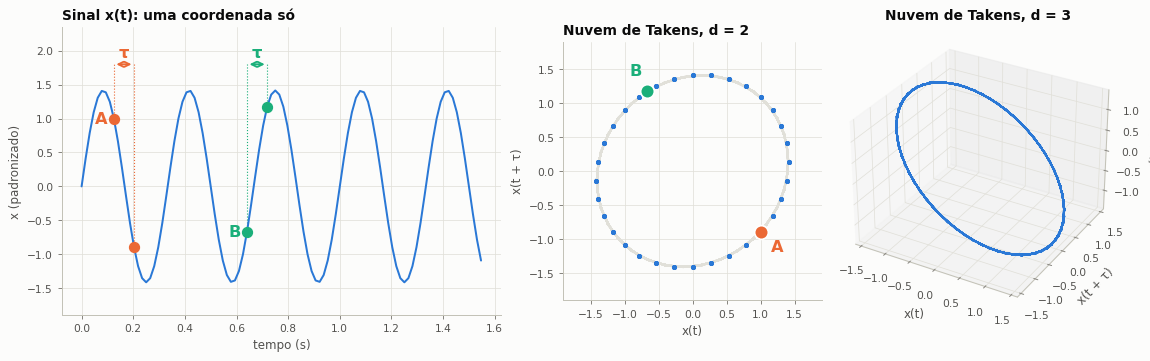

In [7]:
T = np.arange(int(JANELA_S * FS)) / FS            # 8 s a 64 Hz = 512 amostras
seno = np.sin(2 * np.pi * 3.0 * T)                 # senoide de 3 Hz: período de 64/3 = 21,3 amostras
tau = 5                                            # perto de 1/4 do período

X2 = imersao_takens(seno, dim=2, atraso=tau, passo=1)
X3 = imersao_takens(seno, dim=3, atraso=tau, passo=1)
print(f"sinal: {seno.shape}  ->  nuvem com d=2: {X2.shape}  |  nuvem com d=3: {X3.shape}")
print("primeiro ponto (d=3):", np.round(X3[0], 3), "= (x[0], x[5], x[10]) do sinal padronizado")

xs = padronizar(seno)
fig = plt.figure(figsize=(12.5, 3.9), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[1.7, 1, 1.15])
a, b = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
c = fig.add_subplot(gs[2], projection="3d")

a.plot(T[:100], xs[:100], color=AZUL)
b.plot(X2[:, 0], X2[:, 1], color=GRADE, lw=1.2, zorder=1)
b.scatter(X2[::2, 0], X2[::2, 1], s=14, color=AZUL, linewidths=0, zorder=2)
for i0, cor, nome in [(8, LARANJA, "A"), (41, AGUA, "B")]:
    i1 = i0 + tau
    a.plot(T[[i0, i1]], xs[[i0, i1]], "o", color=cor, ms=8, zorder=5)
    a.annotate("", xy=(T[i1], 1.8), xytext=(T[i0], 1.8), arrowprops=dict(arrowstyle="<->", color=cor, lw=1.5))
    a.text((T[i0] + T[i1]) / 2, 1.86, "τ", color=cor, ha="center", va="bottom", fontsize=13, fontweight="bold")
    for i in (i0, i1):
        a.plot([T[i], T[i]], [xs[i], 1.8], color=cor, lw=0.9, ls=":", zorder=1)
    a.text(T[i0] - 0.025, xs[i0], nome, color=cor, ha="right", va="center", fontsize=13, fontweight="bold")
    b.plot(X2[i0, 0], X2[i0, 1], "o", color=cor, ms=11, mec="white", mew=1.4, zorder=5)
    b.text(1.25 * X2[i0, 0], 1.25 * X2[i0, 1], nome, color=cor, fontsize=13, fontweight="bold",
           ha="center", va="center")
a.set_ylim(-1.9, 2.35)
a.set_title("Sinal x(t): uma coordenada só")
a.set_xlabel("tempo (s)")
a.set_ylabel("x (padronizado)")
b.set_aspect("equal")
b.set_xlim(-1.9, 1.9)
b.set_ylim(-1.9, 1.9)
b.set_title("Nuvem de Takens, d = 2")
b.set_xlabel("x(t)")
b.set_ylabel("x(t + τ)")
c.plot(X3[:, 0], X3[:, 1], X3[:, 2], color=AZUL, lw=1.2)
c.set_title("Nuvem de Takens, d = 3")
c.set_xlabel("x(t)")
c.set_ylabel("x(t + τ)")
c.set_zlabel("x(t + 2τ)")
plt.show()

**O que observar.** A senoide sobe e desce para sempre, mas a nuvem não "anda": ela fecha um laço e repete a mesma volta a cada período. Em $d=3$ o laço é uma elipse inclinada no espaço. A topologia (um laço) é a mesma nas duas dimensões.

**Por que $\tau$ importa.** O atraso define o quanto as coordenadas são diferentes entre si. Com $\tau$ muito pequeno, $x(t+\tau)\approx x(t)$ e a nuvem se esmaga sobre a diagonal. Com $\tau$ perto de meio período, $x(t+\tau)\approx -x(t)$ e ela se esmaga sobre a outra diagonal. Perto de um quarto de período o laço fica bem aberto. A Seção 3 mostra como escolher $\tau$ a partir dos dados.

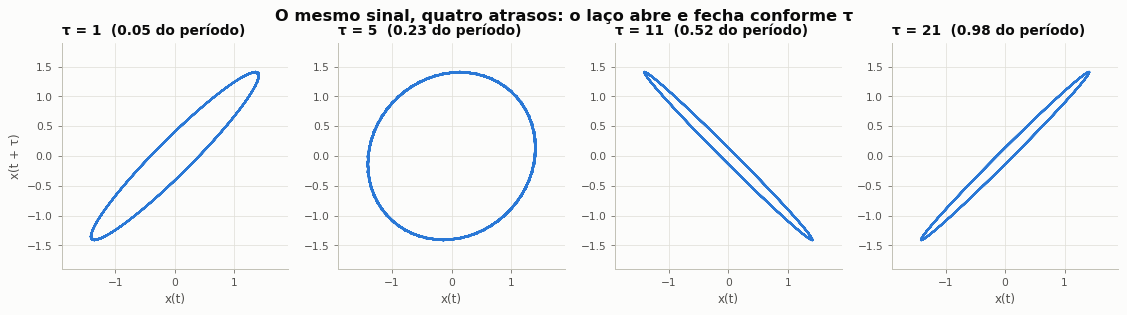

In [8]:
periodo = FS / 3.0
fig, eixos = plt.subplots(1, 4, figsize=(12.5, 3.3), constrained_layout=True)
for ax, tau_k in zip(eixos, [1, 5, 11, 21]):
    Xk = imersao_takens(seno, dim=2, atraso=tau_k, passo=1)
    ax.plot(Xk[:, 0], Xk[:, 1], color=AZUL, lw=1.4)
    ax.set_aspect("equal")
    ax.set_xlim(-1.9, 1.9)
    ax.set_ylim(-1.9, 1.9)
    ax.set_title(f"τ = {tau_k}  ({tau_k / periodo:.2f} do período)")
    ax.set_xlabel("x(t)")
eixos[0].set_ylabel("x(t + τ)")
fig.suptitle("O mesmo sinal, quatro atrasos: o laço abre e fecha conforme τ")
plt.show()

### 1.2 Vietoris–Rips e $H_1$: medindo o laço

Olhando a figura sabemos que há um laço. Para um computador, a nuvem é só uma lista de pontos. A homologia persistente dá um jeito de detectar o laço sem escolher uma escala de antemão.

**Complexo de Vietoris–Rips.** Fixe uma escala $\varepsilon \ge 0$. Ligue por uma aresta todo par de pontos a distância $\le \varepsilon$, e preencha com um triângulo todo trio de pontos ligados dois a dois:

$$\sigma = [v_0,\dots,v_k] \in \mathrm{VR}_\varepsilon(X) \iff \max_{i,j}\, \lVert v_i - v_j\rVert \le \varepsilon .$$

**Filtração e persistência.** Aumentando $\varepsilon$ de zero até a maior distância da nuvem, o complexo só cresce. Um ciclo de $H_1$ é um laço de arestas que **não** é borda de triângulos. Ele *nasce* na escala em que o laço se fecha e *morre* na escala em que os triângulos terminam de preenchê-lo. A diferença, *morte − nascimento*, é a **persistência** do ciclo. O conjunto dos pares (nascimento, morte) é o **diagrama de persistência**; desenhados como segmentos, formam o **código de barras**.

**Intuição.** Ciclos de ruído são pequenos: nascem e morrem quase na mesma escala (barras curtas, pontos colados à diagonal). Um laço de verdade, grande e bem amostrado, nasce cedo e só morre em uma escala comparável ao seu diâmetro (barra longa, ponto longe da diagonal).

A função `h1_rips` abaixo é a do projeto. Dois detalhes:

- O complexo é construído até a dimensão 2: os triângulos são necessários para que os ciclos de $H_1$ possam morrer.
- Sem `max_aresta`, a filtração vai até a maior distância observada e toda classe morre. Com truncamento, as classes ainda vivas no corte têm a morte fixada no corte e são contadas como *censuradas* (a persistência delas vira um limite inferior). O projeto não trunca, então há zero classes censuradas.

In [9]:
def h1_rips(X, max_aresta=None, motor="gudhi"):
    """Persistência em H1 do Vietoris-Rips da nuvem X.

    Devolve (intervalos de H1 como matriz n x 2, escala de corte, nº de classes censuradas).
    motor="gudhi" segue o código-modelo do enunciado; motor="ripser" calcula a mesma coisa mais rápido.
    """
    X = np.asarray(X, dtype=float)
    corte_cheio = float(pdist(X).max())                    # maior distância entre dois pontos
    corte = corte_cheio if max_aresta is None else float(max_aresta)

    if motor == "ripser":
        h1 = np.asarray(ripser(X, maxdim=1, thresh=corte)["dgms"][1], dtype=float).reshape(-1, 2)
    else:
        rips = gudhi.RipsComplex(points=X, max_edge_length=corte)
        st = rips.create_simplex_tree(max_dimension=2)     # vértices, arestas e triângulos
        st.compute_persistence()
        h1 = np.asarray(st.persistence_intervals_in_dimension(1), dtype=float).reshape(-1, 2)

    censuradas = ~np.isfinite(h1[:, 1])                    # classes que não morreram até o corte
    h1[censuradas, 1] = corte
    return h1, corte, int(censuradas.sum())


def persistencias(h1):
    return (h1[:, 1] - h1[:, 0]) if len(h1) else np.empty(0)

**A filtração, quadro a quadro.** Para enxergar o complexo crescer, usamos uma nuvem pequena no plano: uma senoide de 3 Hz com ruído (relação sinal-ruído de 10 dB), imersa com $d=2$ e poucos pontos. Em cada painel, os discos têm diâmetro $\varepsilon$ (dois pontos são ligados quando seus discos se tocam), e embaixo aparece o código de barras de $H_1$ desenhado até a escala atual. Tudo o que aparece é calculado de verdade pela função acima.

43 pontos, 903 arestas e 12341 triângulos possíveis
3 ciclos em H1; o principal nasce em 0.64, morre em 1.74 (persistência 1.10)


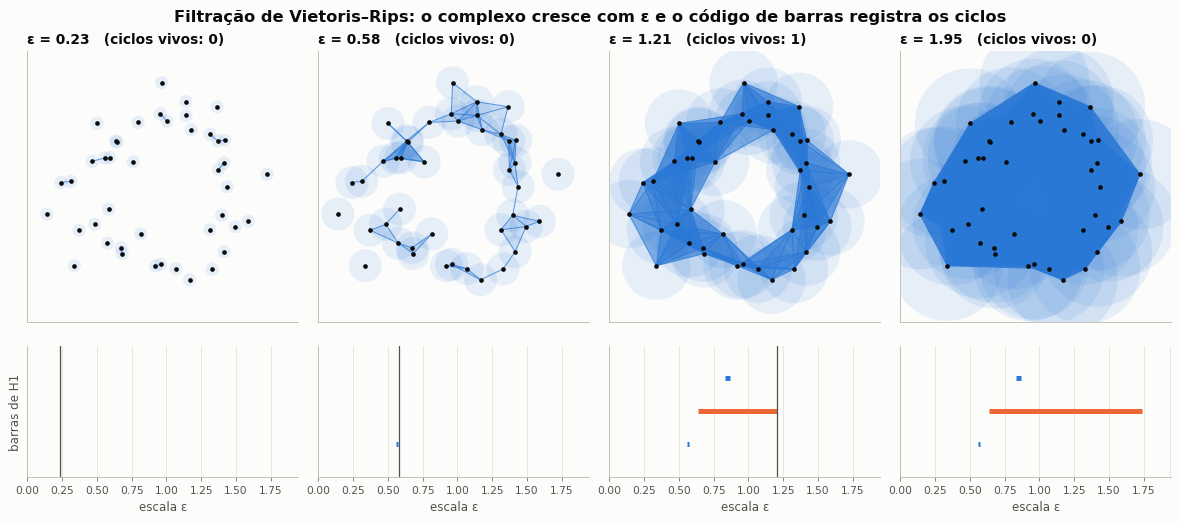

In [10]:
def ruido_banda(rng, n):
    """Ruído branco filtrado em 1-30 Hz, como o EEG pré-processado."""
    sos = butter(4, BANDA, btype="band", fs=FS, output="sos")
    return sosfiltfilt(sos, rng.standard_normal(n + 4 * FS))[2 * FS: 2 * FS + n]


def cena_sintetica():
    """Senoide de 3 Hz + ruído (SNR 10 dB), imersa em d=2 com poucos pontos."""
    rng = np.random.default_rng(SEMENTE)
    x = padronizar(np.sin(2 * np.pi * 3.0 * T)) + padronizar(ruido_banda(rng, len(T))) * 10 ** (-10 / 20)
    return padronizar(x), imersao_takens(x, dim=2, atraso=5, passo=12)


def preparar_complexo(X):
    """Arestas e triângulos do Rips, cada um com a escala em que entra na filtração."""
    D = squareform(pdist(X))
    iu = np.triu_indices(len(X), 1)
    tri = np.array(list(combinations(range(len(X)), 3)))
    # um triângulo entra quando a sua MAIOR aresta entra
    val_tri = np.max([D[tri[:, 0], tri[:, 1]], D[tri[:, 0], tri[:, 2]], D[tri[:, 1], tri[:, 2]]], axis=0)
    return {"D": D, "arestas": np.column_stack(iu), "val_aresta": D[iu], "tri": tri, "val_tri": val_tri}


def desenhar_complexo(ax, X, comp, eps):
    """Discos de diâmetro eps, arestas e triângulos presentes na escala eps."""
    n = len(X)
    bolas = EllipseCollection(np.full(n, eps), np.full(n, eps), np.zeros(n), units="xy", offsets=X,
                              offset_transform=ax.transData, facecolor=AZUL, alpha=0.10,
                              edgecolor="none", zorder=1)
    tris = PolyCollection(X[comp["tri"][comp["val_tri"] <= eps]], facecolor=AZUL, alpha=0.16,
                          edgecolor="none", zorder=2)
    segs = LineCollection(X[comp["arestas"][comp["val_aresta"] <= eps]], colors=AZUL, linewidths=0.8,
                          alpha=0.75, zorder=3)
    for col in (bolas, tris, segs):
        ax.add_collection(col)
    return [bolas, tris, segs]


def desenhar_barras(ax, h1, eps, principal):
    """Código de barras de H1 desenhado até a escala eps (ciclo principal em laranja)."""
    vivos = h1[:, 0] <= eps
    barras = LineCollection(
        [[(b, i), (min(d, eps), i)] for i, (b, d) in enumerate(h1) if vivos[i]],
        colors=[LARANJA if i == principal else AZUL for i in range(len(h1)) if vivos[i]],
        linewidths=4, capstyle="butt")
    ax.add_collection(barras)
    return barras


x_cena, X_cena = cena_sintetica()
comp = preparar_complexo(X_cena)
h1_cena, _, _ = h1_rips(X_cena)
h1_cena = h1_cena[persistencias(h1_cena) > 1e-9]
h1_cena = h1_cena[np.argsort(h1_cena[:, 0])]                    # barras em ordem de nascimento
principal = int(np.argmax(persistencias(h1_cena)))
eps_max = min(h1_cena[principal, 1] * 1.12, comp["D"].max())
print(f"{len(X_cena)} pontos, {len(comp['arestas'])} arestas e {len(comp['tri'])} triângulos possíveis")
print(f"{len(h1_cena)} ciclos em H1; o principal nasce em {h1_cena[principal, 0]:.2f}, morre em "
      f"{h1_cena[principal, 1]:.2f} (persistência {persistencias(h1_cena)[principal]:.2f})")

fig, eixos = plt.subplots(2, 4, figsize=(13, 5.7), constrained_layout=True,
                          gridspec_kw={"height_ratios": [2.3, 1]})
lim = np.abs(X_cena).max() + 0.35
for j, fracao in enumerate([0.12, 0.30, 0.62, 1.0]):
    eps = fracao * eps_max
    a, b = eixos[:, j]
    desenhar_complexo(a, X_cena, comp, eps)
    a.scatter(X_cena[:, 0], X_cena[:, 1], s=14, color=TINTA, zorder=5, linewidths=0)
    a.set_xlim(-lim, lim)
    a.set_ylim(-lim, lim)
    a.set_aspect("equal")
    a.grid(False)
    a.set_xticks([])
    a.set_yticks([])
    beta1 = int(np.sum((h1_cena[:, 0] <= eps) & (h1_cena[:, 1] > eps)))
    a.set_title(f"ε = {eps:.2f}   (ciclos vivos: {beta1})")
    desenhar_barras(b, h1_cena, eps, principal)
    b.axvline(eps, color=TINTA_2, lw=1)
    b.set_xlim(0, eps_max)
    b.set_ylim(-1, len(h1_cena))
    b.set_yticks([])
    b.grid(axis="y", visible=False)
    b.set_xlabel("escala ε")
eixos[1, 0].set_ylabel("barras de H1")
fig.suptitle("Filtração de Vietoris–Rips: o complexo cresce com ε e o código de barras registra os ciclos")
plt.show()

**O que observar.**

- **Primeiro painel:** quase nada está ligado; ainda não há ciclos.
- **Segundo:** os pontos vizinhos se ligam e aparecem ciclos pequenos, que morrem logo em seguida (barras azuis curtas). São ruído de amostragem.
- **Terceiro:** o anel se fecha e nasce o ciclo grande (barra laranja). Os triângulos já preenchem a faixa do anel, mas não o buraco do meio.
- **Quarto:** só quando $\varepsilon$ chega perto do diâmetro do anel os triângulos atravessam o buraco e a barra laranja termina.

A barra longa é a assinatura topológica da periodicidade. A Seção 10 gera a versão animada desta figura.

Agora o caso que será usado no EEG: $d=3$, $\tau=4$, 126 pontos por janela. À esquerda uma senoide, à direita ruído filtrado na mesma banda do EEG.

Senoide 3 Hz   : 126 pontos, 5 ciclos; maiores persistências: [2.254 0.    0.   ]
Ruído 1–30 Hz  : 126 pontos, 49 ciclos; maiores persistências: [0.373 0.37  0.352]


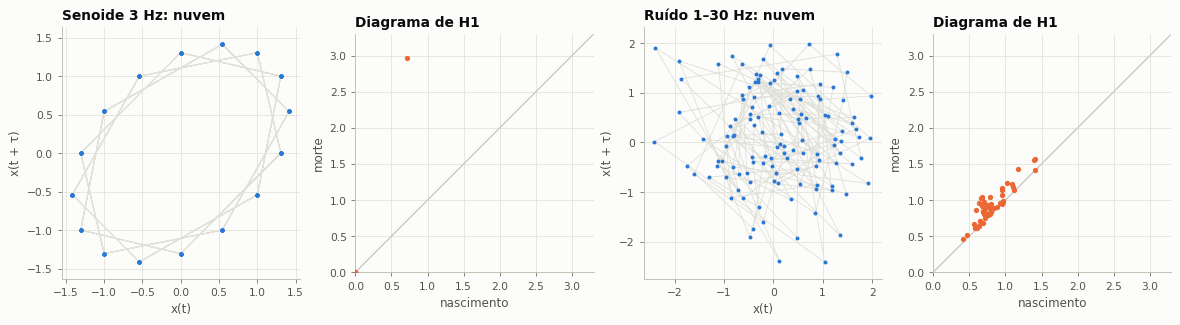

In [11]:
def desenhar_diagrama(ax, h1, cor=LARANJA, lim=None, s=18):
    """Diagrama de persistência: um ponto (nascimento, morte) por ciclo."""
    lim = lim or (max(1.0, h1[:, 1].max() * 1.08) if len(h1) else 1.0)
    ax.plot([0, lim], [0, lim], color=EIXO, lw=0.9)
    if len(h1):
        ax.scatter(h1[:, 0], h1[:, 1], s=s, color=cor, linewidths=0, zorder=3)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("nascimento")
    ax.set_ylabel("morte")


rng_demo = np.random.default_rng(0)
ruido_demo = padronizar(ruido_banda(rng_demo, len(T)))

fig, eixos = plt.subplots(1, 4, figsize=(13, 3.5), constrained_layout=True)
for k, (nome, x) in enumerate({"Senoide 3 Hz": seno, "Ruído 1–30 Hz": ruido_demo}.items()):
    X = imersao_takens(x, DIM, ATRASO, PASSO_NUVEM)
    h1, _, _ = h1_rips(X)
    maiores = np.sort(persistencias(h1))[::-1][:3]
    print(f"{nome:15s}: {len(X)} pontos, {len(h1)} ciclos; maiores persistências: {np.round(maiores, 3)}")
    a, b = eixos[2 * k], eixos[2 * k + 1]
    a.plot(X[:, 0], X[:, 1], color=GRADE, lw=0.7, zorder=1)
    a.scatter(X[:, 0], X[:, 1], s=10, color=AZUL, linewidths=0, zorder=2)
    a.set_aspect("equal", adjustable="datalim")
    a.set_title(f"{nome}: nuvem")
    a.set_xlabel("x(t)")
    a.set_ylabel("x(t + τ)")
    desenhar_diagrama(b, h1, lim=3.3)
    b.set_title("Diagrama de H1")
plt.show()

**O que observar.** A senoide tem um único ponto longe da diagonal (um ciclo, persistência perto de 2,25). O ruído tem dezenas de pontos, todos perto da diagonal (nenhum passa muito de 0,4). É essa diferença que esperamos encontrar entre o EEG ictal, se ele for rítmico, e o EEG interictal.

Dois detalhes da figura. As linhas cinza ligam pontos consecutivos no tempo; como a nuvem guarda só 1 ponto a cada 4 amostras, na senoide elas formam uma estrela em vez de um círculo. E a senoide de 3 Hz se repete exatamente a cada 64 amostras, de modo que os 126 pontos caem em apenas 16 posições distintas. Os pontos repetidos geram ciclos de persistência zero (o ponto na origem do diagrama), que não afetam os descritores de persistência.

### 1.3 Do diagrama aos números: descritores

Um diagrama é um conjunto de pontos, e a maioria dos métodos estatísticos precisa de um vetor de tamanho fixo. Chamando de $\ell_i = \text{morte}_i - \text{nascimento}_i$ a persistência do ciclo $i$, os descritores do projeto são:

| Descritor | Definição | Leitura |
|---|---|---|
| persistência máxima | $\max_i \ell_i$ | o tamanho do laço mais robusto |
| persistência total | $\sum_i \ell_i$ | quanta estrutura de laço há, somando tudo |
| número de classes | quantidade de pontos no diagrama | cresce com a irregularidade da nuvem |
| entropia de persistência | $E = -\sum_i p_i \ln p_i$, com $p_i = \ell_i / \sum_j \ell_j$ | baixa: um ciclo domina; alta: muitos ciclos parecidos |
| dominância | $\max_i \ell_i / \sum_i \ell_i$ | fração da persistência total no ciclo principal |
| paisagens $\lambda_1,\lambda_2,\lambda_3$ | $\lambda_k(t)$ = $k$-ésimo maior valor de $\max\{0, \min(t - b_i,\; d_i - t)\}$ | cada ciclo vira uma "tenda"; $\lambda_k$ é a $k$-ésima camada. Usamos as normas $L^1$ e $L^2$ |
| bottleneck | $d_B(D_t, D_{t-1})$ entre janelas consecutivas | o quanto o diagrama mudou de uma janela para a seguinte |

As paisagens são amostradas em uma grade fixa (0 a 3, 121 pontos), a mesma para todas as janelas. Como as nuvens vêm de sinais padronizados, isso as torna comparáveis e permite tirar médias por classe.

A **distância de bottleneck** entre dois diagramas é o custo do melhor emparelhamento entre seus pontos (pontos sem par vão para a diagonal), medido pelo maior deslocamento. Ela é *estável*: uma perturbação pequena na nuvem muda pouco o diagrama.

In [12]:
def entropia_persistencia(h1):
    """E = -sum p_i log p_i, com p_i = persistência_i / persistência total."""
    p = persistencias(h1)
    p = p[p > 0]
    if len(p) == 0:
        return 0.0
    p = p / p.sum()
    return float(-np.sum(p * np.log(p)))


def paisagens(h1, k=PAISAGEM_K, grade=PAISAGEM_GRADE):
    """Paisagens de persistência lambda_1..lambda_k amostradas em uma grade fixa."""
    t = np.linspace(*grade[:2], int(grade[2]))
    saida = np.zeros((k, len(t)))
    if len(h1):
        # uma "tenda" por ciclo: sobe a partir do nascimento, desce até a morte
        tendas = np.clip(np.minimum(t[None, :] - h1[:, [0]], h1[:, [1]] - t[None, :]), 0, None)
        tendas = -np.sort(-tendas, axis=0)[:k]             # em cada t, os k maiores valores
        saida[: tendas.shape[0]] = tendas
    return saida


def descritores_h1(h1, corte=np.nan, n_censuradas=0):
    """Vetor de características de um diagrama de H1."""
    p = np.sort(persistencias(h1))[::-1]
    d = {
        "h1_n": len(p),
        "h1_pers_max": float(p[0]) if len(p) else 0.0,
        "h1_pers_total": float(p.sum()),
        "h1_pers_media": float(p.mean()) if len(p) else 0.0,
        "h1_entropia": entropia_persistencia(h1),
        "h1_dominancia": float(p[0] / p.sum()) if len(p) and p.sum() > 0 else 0.0,
        "h1_pers_2a": float(p[1]) if len(p) > 1 else 0.0,   # segunda maior persistência
    }
    if len(h1):
        i = int(np.argmax(persistencias(h1)))
        d["h1_nasc_max"], d["h1_morte_max"] = float(h1[i, 0]), float(h1[i, 1])   # onde vive o ciclo principal
    else:
        d["h1_nasc_max"] = d["h1_morte_max"] = 0.0

    lam = paisagens(h1)
    dt = (PAISAGEM_GRADE[1] - PAISAGEM_GRADE[0]) / (PAISAGEM_GRADE[2] - 1)
    for j in range(lam.shape[0]):
        d[f"h1_pais{j + 1}_l1"] = float(lam[j].sum() * dt)                  # norma L1
        d[f"h1_pais{j + 1}_l2"] = float(np.sqrt((lam[j] ** 2).sum() * dt))  # norma L2
    d["corte"] = float(corte)
    d["h1_censuradas"] = int(n_censuradas)
    return d


COLUNAS_TOPO = [
    "h1_n", "h1_pers_max", "h1_pers_total", "h1_pers_media", "h1_entropia",
    "h1_dominancia", "h1_pers_2a", "h1_nasc_max", "h1_morte_max",
    "h1_pais1_l1", "h1_pais1_l2", "h1_pais2_l1", "h1_pais2_l2", "h1_pais3_l1", "h1_pais3_l2",
]


def bottleneck(h1_a, h1_b):
    """Distância de bottleneck entre dois diagramas de H1 (0 se ambos vazios)."""
    if len(h1_a) == 0 and len(h1_b) == 0:
        return 0.0
    return float(gudhi.bottleneck_distance(h1_a, h1_b))

,h1_n,h1_pers_max,h1_pers_total,h1_entropia,h1_dominancia,h1_pais1_l1,h1_pais2_l1
Senoide 3 Hz,5.0,2.254,2.254,0.000,1.000,1.270,0.000
Senoide + ruído fraco (20 dB),9.0,2.236,2.396,0.373,0.933,1.251,0.000
Ruído 1–30 Hz,49.0,0.373,6.026,3.516,0.062,0.087,0.058


d_B(Senoide 3 Hz, Senoide + ruído fraco (20 dB)) = 0.252
d_B(Senoide 3 Hz, Ruído 1–30 Hz) = 1.127


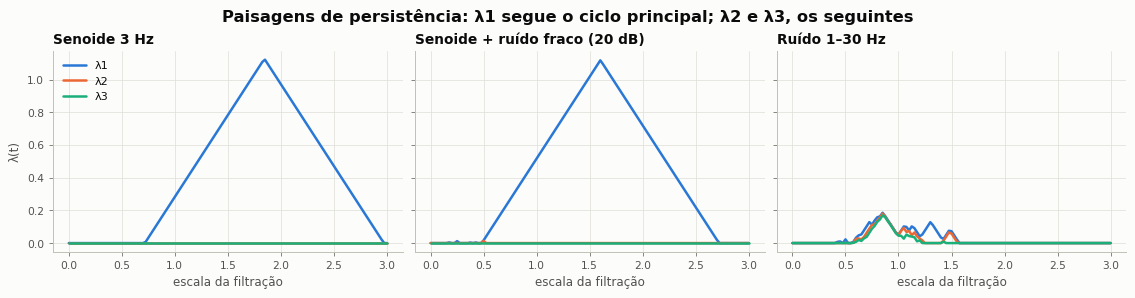

In [13]:
demos = {
    "Senoide 3 Hz": seno,
    "Senoide + ruído fraco (20 dB)": padronizar(seno) + 0.1 * ruido_demo,
    "Ruído 1–30 Hz": ruido_demo,
}
diag_demo = {nome: h1_rips(imersao_takens(x, DIM, ATRASO, PASSO_NUVEM))[0] for nome, x in demos.items()}
tabela = pd.DataFrame({nome: descritores_h1(h) for nome, h in diag_demo.items()}).T
display(tabela[["h1_n", "h1_pers_max", "h1_pers_total", "h1_entropia", "h1_dominancia",
                "h1_pais1_l1", "h1_pais2_l1"]].round(3))

nomes = list(diag_demo)
print(f"d_B({nomes[0]}, {nomes[1]}) = {bottleneck(diag_demo[nomes[0]], diag_demo[nomes[1]]):.3f}")
print(f"d_B({nomes[0]}, {nomes[2]}) = {bottleneck(diag_demo[nomes[0]], diag_demo[nomes[2]]):.3f}")

t_grade = np.linspace(*PAISAGEM_GRADE[:2], int(PAISAGEM_GRADE[2]))
fig, eixos = plt.subplots(1, 3, figsize=(12.5, 3.2), sharey=True, constrained_layout=True)
for ax, (nome, h) in zip(eixos, diag_demo.items()):
    lam = paisagens(h)
    for j, cor in enumerate([AZUL, LARANJA, AGUA]):
        ax.plot(t_grade, lam[j], color=cor, lw=2, label=f"λ{j + 1}")
    ax.set_title(nome)
    ax.set_xlabel("escala da filtração")
eixos[0].set_ylabel("λ(t)")
eixos[0].legend(loc="upper left")
fig.suptitle("Paisagens de persistência: λ1 segue o ciclo principal; λ2 e λ3, os seguintes")
plt.show()

**O que observar.**

- **Senoide:** uma tenda só. $\lambda_1$ é alta e $\lambda_2$ é zero; a dominância é 1 e a entropia é 0.
- **Ruído:** dezenas de ciclos pequenos. Persistência máxima baixa, persistência total alta e entropia alta; $\lambda_1$, $\lambda_2$ e $\lambda_3$ têm alturas parecidas.
- **Bottleneck:** um ruído fraco sobre a senoide muda pouco o diagrama (distância pequena); trocar a senoide por ruído muda muito, porque o ciclo grande não tem com quem emparelhar e vai para a diagonal.

Guarde uma consequência: **a persistência total e a entropia medem mais a "quantidade de ruído" na nuvem do que a presença de um laço.** Isso volta na Seção 5.

### 1.4 Teste de sanidade: sinais com resposta conhecida

Quatro sinais de 8 s, com os mesmos parâmetros que serão usados no EEG ($d=3$, $\tau=4$, 126 pontos):

1. uma senoide de 3 Hz (resposta esperada: um ciclo dominante);
2. a mesma senoide com ruído de mesma potência (0 dB);
3. um padrão periódico não senoidal, que imita as descargas *espícula-onda* a 3 Hz vistas em algumas crises;
4. só ruído na banda de 1–30 Hz (resposta esperada: nenhum ciclo dominante).

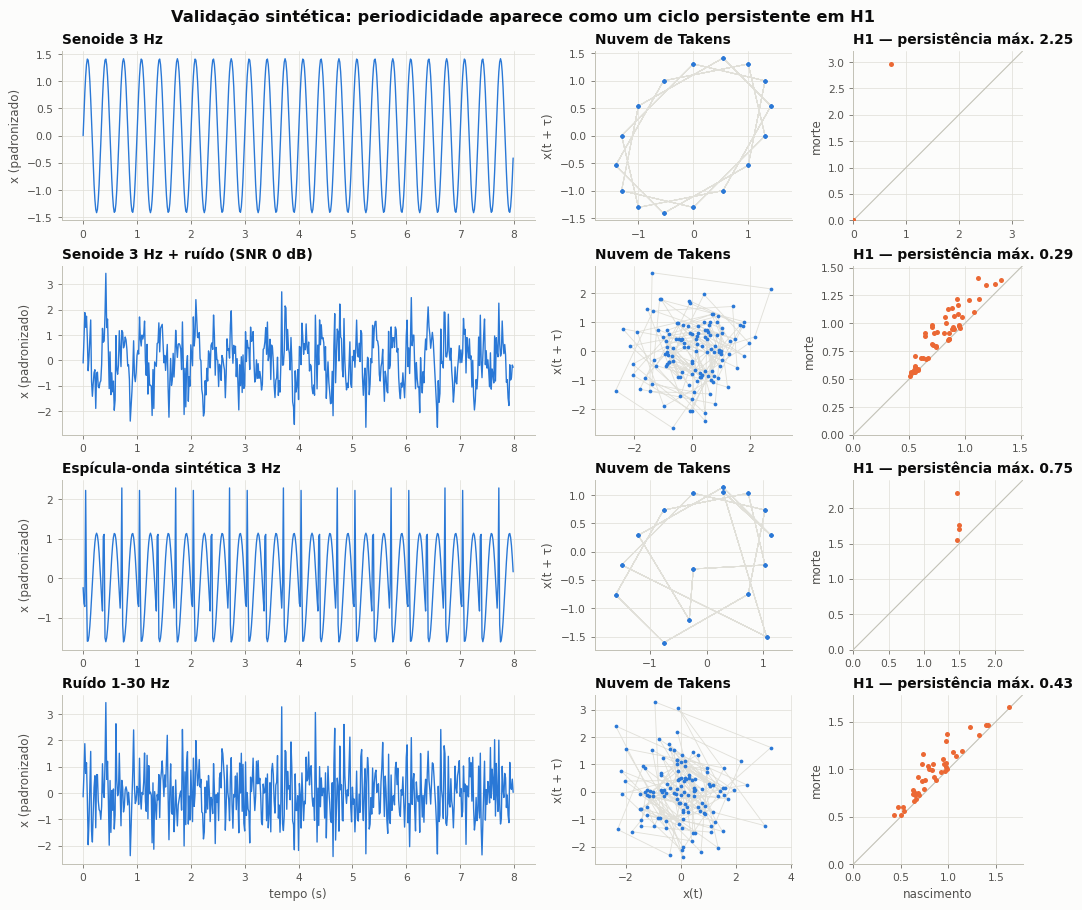

,sinal,h1_n,h1_pers_max,h1_pers_total,h1_entropia,h1_dominancia
0,Senoide 3 Hz,5,2.254,2.254,0.000,1.000
1,Senoide 3 Hz + ruído (SNR 0 dB),52,0.294,5.513,3.572,0.053
2,Espícula-onda sintética 3 Hz,4,0.748,1.300,1.106,0.575
3,Ruído 1-30 Hz,42,0.426,5.033,3.398,0.085


In [14]:
def espicula_onda(t, f=3.0):
    """Padrão periódico não senoidal, lembrando descargas espícula-onda a 3 Hz."""
    fase = (t * f) % 1.0
    return np.exp(-((fase - 0.15) / 0.035) ** 2) * 2.2 - np.sin(2 * np.pi * fase) * 0.8


rng = np.random.default_rng(SEMENTE)
r = padronizar(ruido_banda(rng, len(T)))
S = {
    "Senoide 3 Hz": seno,
    "Senoide 3 Hz + ruído (SNR 0 dB)": padronizar(seno) + r,
    "Espícula-onda sintética 3 Hz": espicula_onda(T),
    "Ruído 1-30 Hz": r,
}

fig, eixos = plt.subplots(len(S), 3, figsize=(11.5, 2.5 * len(S)),
                          gridspec_kw={"width_ratios": [2.4, 1, 1]}, constrained_layout=True)
linhas = []
for i, (nome, x) in enumerate(S.items()):
    X = imersao_takens(x, DIM, ATRASO, PASSO_NUVEM)
    h1, corte, _ = h1_rips(X)
    d = descritores_h1(h1, corte)
    linhas.append({"sinal": nome, **{k: d[k] for k in
                   ("h1_n", "h1_pers_max", "h1_pers_total", "h1_entropia", "h1_dominancia")}})
    a, b, c = eixos[i]
    a.plot(T, padronizar(x), color=AZUL, lw=1.1)
    a.set_title(nome)
    a.set_ylabel("x (padronizado)")
    b.plot(X[:, 0], X[:, 1], color=GRADE, lw=0.7, zorder=1)
    b.scatter(X[:, 0], X[:, 1], s=9, color=AZUL, zorder=2, linewidths=0)
    b.set_aspect("equal", adjustable="datalim")
    b.set_title("Nuvem de Takens")
    b.set_ylabel("x(t + τ)")
    b.set_xlabel("")
    desenhar_diagrama(c, h1, s=16)
    c.set_title(f"H1 — persistência máx. {d['h1_pers_max']:.2f}")
    if i < len(S) - 1:
        c.set_xlabel("")
eixos[-1, 0].set_xlabel("tempo (s)")
eixos[-1, 1].set_xlabel("x(t)")
fig.suptitle("Validação sintética: periodicidade aparece como um ciclo persistente em H1")
plt.show()
display(pd.DataFrame(linhas).round(3))

**O que observar.** O código faz o que a teoria promete nos casos limpos: a senoide tem um ciclo com persistência 2,25 e o ruído fica perto de 0,4. O padrão espícula-onda também gera um ciclo dominante, embora menor (0,75), porque a espícula é rápida e deixa poucos pontos naquele trecho do laço.

O caso mais importante é o segundo. **Com ruído de mesma potência que o sinal (0 dB), a persistência máxima cai para o nível do ruído puro.** O laço ainda existe na dinâmica, mas a nuvem ficou grossa demais para o Rips enxergar o buraco. A próxima célula mede em que nível de ruído isso acontece.

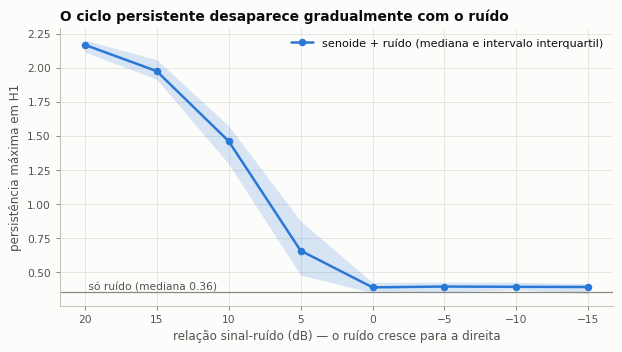

,0,1,2,3,4,5,6,7
snr_db,20.000,15.000,10.000,5.000,0.000,-5.000,-10.000,-15.000
mediana,2.168,1.975,1.461,0.659,0.389,0.395,0.394,0.392
q1,2.115,1.915,1.295,0.480,0.350,0.355,0.372,0.344
q3,2.202,2.060,1.574,0.876,0.425,0.428,0.426,0.417


In [15]:
snrs = np.array([20, 15, 10, 5, 0, -5, -10, -15])       # relação sinal-ruído em dB
seno_p = padronizar(seno)
reps = 30
pm = np.zeros((len(snrs), reps))
pm_ruido = np.zeros(reps)
for k in range(reps):
    ru = padronizar(ruido_banda(rng, len(T)))
    pm_ruido[k] = descritores_h1(h1_rips(imersao_takens(ru, DIM, ATRASO, PASSO_NUVEM))[0])["h1_pers_max"]
    for j, snr in enumerate(snrs):
        x = seno_p + ru * 10 ** (-snr / 20)             # mesma senoide, ruído cada vez mais forte
        pm[j, k] = descritores_h1(h1_rips(imersao_takens(x, DIM, ATRASO, PASSO_NUVEM))[0])["h1_pers_max"]

q1, med, q3 = np.percentile(pm, [25, 50, 75], axis=1)
piso = np.median(pm_ruido)
fig, ax = plt.subplots(figsize=(6.8, 3.8), constrained_layout=True)
ax.fill_between(snrs, q1, q3, color=AZUL, alpha=0.18, lw=0)
ax.plot(snrs, med, color=AZUL, lw=2, marker="o", ms=5, label="senoide + ruído (mediana e intervalo interquartil)")
ax.axhline(piso, color=MUDO, lw=1)
ax.text(snrs.max(), piso, f" só ruído (mediana {piso:.2f})", ha="left", va="bottom", fontsize=8.5, color=TINTA_2)
ax.invert_xaxis()
ax.set_xlabel("relação sinal-ruído (dB) — o ruído cresce para a direita")
ax.set_ylabel("persistência máxima em H1")
ax.set_title("O ciclo persistente desaparece gradualmente com o ruído")
ax.legend(loc="upper right")
plt.show()
display(pd.DataFrame({"snr_db": snrs, "mediana": med, "q1": q1, "q3": q3}).round(3).T)

**O que observar.** A persistência máxima cai de forma contínua e encosta no piso do ruído por volta de 0 dB. O EEG de escalpo costuma estar nesse regime ou abaixo dele: o ritmo de interesse divide a janela com atividade de fundo de potência igual ou maior. Este gráfico já antecipa a dificuldade do método nos dados reais.

**Experimente.** Troque a frequência da senoide de 3 Hz para 10 Hz (ritmo alfa) nas células acima, mantendo $\tau=4$. O laço continua bem aberto?

## 2. Os dados: CHB-MIT

O **CHB-MIT Scalp EEG Database** reúne gravações de EEG de escalpo de pacientes pediátricos com epilepsia, feitas no Children's Hospital Boston, com o início e o fim de cada crise anotados por especialistas. É público e fica no PhysioNet (Shoeb, 2009; Goldberger et al., 2000).

Usamos o paciente **chb01**: sete gravações de uma hora, 23 canais bipolares a 256 Hz, com **duas crises** anotadas (uma em `chb01_03`, outra em `chb01_04`).

### 2.1 Download

São 7 arquivos EDF de 42 MB (297 MB no total) mais um arquivo de texto com o resumo das crises. Arquivos que já estiverem na pasta não são baixados de novo. O servidor do PhysioNet às vezes é lento, então os arquivos são baixados quatro de cada vez e cada um tem até três tentativas.

In [16]:
def baixar(nome, destino=DIR_DADOS, tentativas=3):
    """Baixa um arquivo do CHB-MIT (PhysioNet) se ele ainda não estiver na pasta."""
    caminho = Path(destino) / nome
    if caminho.exists():
        return caminho, False
    parcial = caminho.with_name(caminho.name + ".part")       # só vira o arquivo final se chegar inteiro
    for tentativa in range(1, tentativas + 1):
        try:
            # a pasta do paciente vem do nome (chb02_16+.edf -> chb02); o "+" precisa ser escapado na URL
            url = f"{URL_RAIZ}/{nome[:5]}/{quote(nome)}"
            with requests.get(url, stream=True, timeout=180) as r:
                r.raise_for_status()
                with parcial.open("wb") as f:
                    for bloco in r.iter_content(chunk_size=1 << 20):
                        f.write(bloco)
                comprimido = "Content-Encoding" in r.headers
                esperado = int(r.headers.get("Content-Length", 0))
            if esperado and not comprimido and parcial.stat().st_size != esperado:
                raise IOError(f"download incompleto de {nome}")
            parcial.replace(caminho)
            return caminho, True
        except (requests.RequestException, IOError):
            if tentativa == tentativas:
                raise


arquivos = ["chb01-summary.txt"] + [f"{g}.edf" for g in GRAVACOES]
t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as pool:
    for nome, (caminho, novo) in zip(arquivos, pool.map(baixar, arquivos)):
        print(f"  {nome:18s} {caminho.stat().st_size / 1e6:6.1f} MB   {'baixado' if novo else 'já estava na pasta'}")
print(f"Pronto em {time.time() - t0:.0f} s.")

  chb01-summary.txt     0.0 MB   já estava na pasta
  chb01_01.edf         42.4 MB   já estava na pasta
  chb01_02.edf         42.4 MB   já estava na pasta
  chb01_03.edf         42.4 MB   já estava na pasta
  chb01_04.edf         42.4 MB   já estava na pasta
  chb01_05.edf         42.4 MB   já estava na pasta
  chb01_06.edf         42.4 MB   já estava na pasta
  chb01_09.edf         42.4 MB   já estava na pasta
Pronto em 0 s.


### 2.2 Gravações e anotações de crise

O arquivo `chb01-summary.txt` lista, para cada EDF, o instante de início e de fim de cada crise, em segundos a partir do começo do arquivo. Um trecho dele:

```
File Name: chb01_03.edf
File Start Time: 13:43:04
File End Time: 14:43:04
Number of Seizures in File: 1
Seizure Start Time: 2996 seconds
Seizure End Time: 3036 seconds
```

A função `ler_resumo` extrai esses pares com expressões regulares. `listar_gravacoes` abre o cabeçalho de cada EDF, ordena as gravações pelo horário e calcula o início de cada uma em uma **linha do tempo única** (segundos a partir da primeira gravação). Isso é necessário porque os 10 minutos anteriores a uma crise poderiam começar no arquivo anterior.

In [17]:
@dataclass
class Gravacao:
    nome: str                      # ex.: "chb01_03"
    caminho: Path
    inicio_abs: float              # início em s, contado a partir da 1ª gravação
    duracao: float                 # duração em s
    crises: list = field(default_factory=list)   # [(ini, fim)] em s dentro do arquivo

    @property
    def crises_abs(self):
        return [(a + self.inicio_abs, b + self.inicio_abs) for a, b in self.crises]


def ler_resumo(caminho):
    """Lê chbXX-summary.txt e devolve {arquivo.edf: [(ini_s, fim_s), ...]}."""
    crises, atual, ini = {}, None, None
    for linha in Path(caminho).read_text(encoding="utf-8").splitlines():
        m = re.match(r"File Name:\s*(\S+)", linha)
        if m:
            atual = m.group(1)
            crises[atual] = []
            continue
        m = re.match(r"Seizure\s*\d*\s*Start Time:\s*(\d+)", linha)
        if m:
            ini = float(m.group(1))
            continue
        m = re.match(r"Seizure\s*\d*\s*End Time:\s*(\d+)", linha)
        if m and atual is not None and ini is not None:
            crises[atual].append((ini, float(m.group(1))))
            ini = None
    return crises


def _abrir(caminho):
    with warnings.catch_warnings():
        # o CHB-MIT repete o rótulo T8-P8; o MNE apenas renumera os duplicados
        warnings.simplefilter("ignore", RuntimeWarning)
        return mne.io.read_raw_edf(caminho, preload=False, verbose=False)


def listar_gravacoes(pasta=DIR_DADOS, nomes=GRAVACOES):
    """Gravações em ordem cronológica, com as crises de cada uma."""
    crises = ler_resumo(Path(pasta) / f"{nomes[0][:5]}-summary.txt")    # resumo do paciente das gravações
    brutas = []
    for nome in nomes:
        caminho = Path(pasta) / f"{nome}.edf"
        raw = _abrir(caminho)
        brutas.append((caminho, raw.info["meas_date"], raw.n_times / raw.info["sfreq"]))
    brutas.sort(key=lambda t: t[1])
    t0 = brutas[0][1]
    return [Gravacao(nome=caminho.stem, caminho=caminho, inicio_abs=(data - t0).total_seconds(),
                     duracao=dur, crises=crises.get(caminho.name, []))
            for caminho, data, dur in brutas]


gravs = listar_gravacoes()
display(pd.DataFrame([{
    "gravação": g.nome,
    "início na linha do tempo (h)": round(g.inicio_abs / 3600, 2),
    "duração (min)": round(g.duracao / 60, 1),
    "crise (s no arquivo)": ", ".join(f"{a:.0f}–{b:.0f} ({b - a:.0f} s)" for a, b in g.crises) or "—",
} for g in gravs]))

,gravação,início na linha do tempo (h),duração (min),crise (s no arquivo)
0,chb01_01,0.00,60.0,—
1,chb01_02,1.00,60.0,—
2,chb01_03,2.00,60.0,2996–3036 (40 s)
3,chb01_04,3.00,60.0,1467–1494 (27 s)
4,chb01_05,4.01,60.0,—
5,chb01_06,5.01,60.0,—
6,chb01_09,8.02,60.0,—


### 2.3 Pré-processamento

Três operações, na ordem:

1. **Escolher um canal.** FP1-F7, o do enunciado. A Seção 9 repete a análise nos outros 20.
2. **Filtrar em 1–30 Hz.** Abaixo de 1 Hz ficam a deriva do eletrodo e o suor; acima de 30 Hz, a atividade muscular e a rede elétrica (60 Hz). Os ritmos clássicos do EEG (delta, teta, alfa, beta) cabem na banda.
3. **Reamostrar para 64 Hz.** Com o sinal limitado a 30 Hz, 64 amostras por segundo bastam (Nyquist: 32 Hz). Uma janela de 8 s fica com 512 amostras em vez de 2 048, e a nuvem de Takens fica quatro vezes menor.

O filtro é aplicado à gravação inteira **antes** de recortar as janelas, de modo que os transientes de borda do filtro ficam fora das janelas analisadas. Os sinais já processados ficam guardados em memória (`_SINAIS`) para não reler o EDF a cada uso.

In [18]:
def carregar_canais(caminho, canais, fs=FS, banda=BANDA):
    """Lê o EDF, filtra em passa-faixa e reamostra. Devolve X[canal, tempo] em microvolts."""
    raw = _abrir(caminho)
    canais = list(canais)
    faltando = [c for c in canais if c not in raw.ch_names]
    if faltando:
        raise ValueError(f"Canais {faltando} não encontrados; exemplos: {raw.ch_names[:5]}")
    raw = raw.pick(canais).load_data()
    raw.filter(banda[0], banda[1], verbose=False)
    raw.resample(fs, verbose=False)
    return raw.get_data() * 1e6, float(raw.info["sfreq"])


_SINAIS = {}    # (arquivo, canal) -> sinal pré-processado


def carregar_canal(caminho, canal=CANAL):
    chave = (Path(caminho).name, canal)
    if chave not in _SINAIS:
        _SINAIS[chave] = carregar_canais(caminho, [canal])[0][0]
    return _SINAIS[chave], float(FS)


def nomes_canais(caminho):
    """Canais bipolares distintos.

    Descarta o T8-P8 repetido, canais vazios e o P7-T7, que é o T7-P7 com sinal trocado
    (a nuvem de Takens de -x é a de x refletida: mesma persistência).
    """
    return [c for c in _abrir(caminho).ch_names if not (c.endswith("-1") or c in ("-", ".", "P7-T7"))]


gravs_por_nome = {g.nome: g for g in gravs}
g3 = gravs_por_nome["chb01_03"]
x3, fs = carregar_canal(g3.caminho)
print(f"{g3.nome}, canal {CANAL}: {len(x3)} amostras a {fs:.0f} Hz ({len(x3) / fs / 60:.0f} min)")

chb01_03, canal FP1-F7: 230400 amostras a 64 Hz (60 min)


**Como é uma crise no sinal.** A primeira crise, em `chb01_03`, vai de 2 996 s a 3 036 s. Em cima, três minutos e meio em torno dela. Embaixo, duas janelas de 8 s na mesma escala vertical: uma cinco minutos antes e outra no meio da crise.

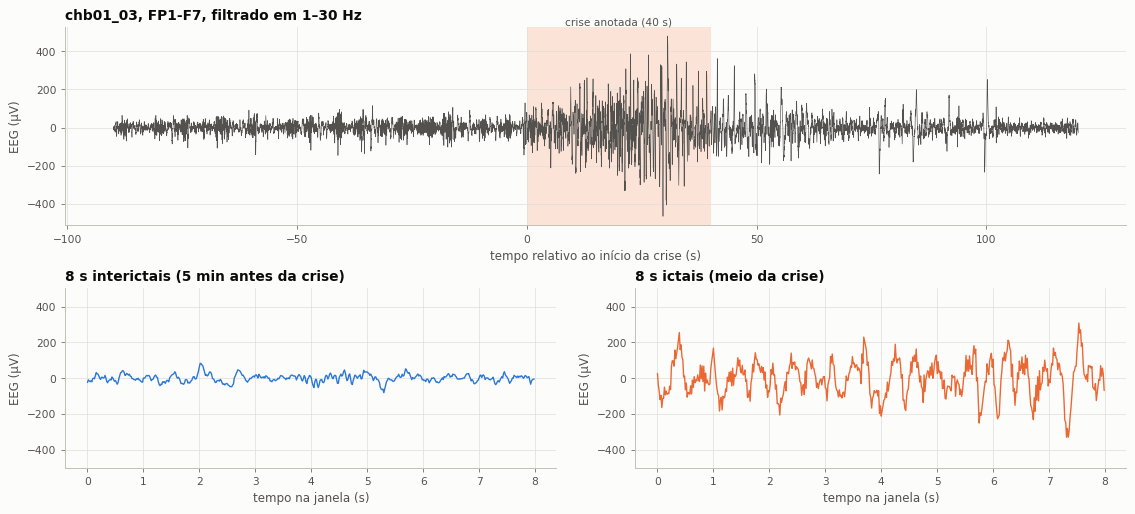

In [19]:
ini, fim = g3.crises[0]
w = int(JANELA_S * fs)
fig = plt.figure(figsize=(12.5, 5.6), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])
ax = fig.add_subplot(gs[0, :])
i0, i1 = int((ini - 90) * fs), int((fim + 80) * fs)
ax.plot(np.arange(i0, i1) / fs - ini, x3[i0:i1], color=TINTA_2, lw=0.5)
faixa_crise(ax, 0, fim - ini, "crise anotada (40 s)")
ax.set_xlabel("tempo relativo ao início da crise (s)")
ax.set_ylabel("EEG (µV)")
ax.set_title(f"{g3.nome}, {CANAL}, filtrado em 1–30 Hz")
ylim = np.abs(x3[i0:i1]).max() * 1.05
for j, (t0s, classe, titulo) in enumerate([(ini - 300, "interictal", "8 s interictais (5 min antes da crise)"),
                                           (ini + 14, "ictal", "8 s ictais (meio da crise)")]):
    axj = fig.add_subplot(gs[1, j])
    seg = x3[int(t0s * fs): int(t0s * fs) + w]
    axj.plot(np.arange(w) / fs, seg, color=COR_CLASSE[classe], lw=1.1)
    axj.set_ylim(-ylim, ylim)
    axj.set_title(titulo)
    axj.set_xlabel("tempo na janela (s)")
    axj.set_ylabel("EEG (µV)")
plt.show()

**O que observar.** Durante a crise a **amplitude** cresce muito e o traçado fica dominado por ondas lentas de alguns hertz. A olho, a janela ictal parece mais rítmica que a interictal. A pergunta do projeto é se essa diferença aparece em $H_1$. Repare também que a imersão de Takens **padroniza** cada janela: a diferença de amplitude, a mais evidente na figura, é descartada de propósito, e só a forma do sinal chega à topologia.

### 2.4 Janelas e rótulos

Cada gravação é cortada em janelas de 8 s que avançam de 4 em 4 s, e cada janela recebe uma classe conforme sua posição em relação às crises:

| Classe | Definição | Uso |
|---|---|---|
| **ictal** | pelo menos 50 % da janela dentro da crise anotada | positiva na detecção |
| **pré-ictal** | termina nos 600 s anteriores ao início da crise | positiva na previsão |
| **interictal** | todo o resto | referência |
| pós-ictal | começa nos 600 s após o fim da crise | **excluída** de todas as comparações |
| transição | sobrepõe a crise em menos de 50 % | **excluída** |

As janelas pós-ictais e de transição ficam de fora porque não pertencem com clareza a nenhuma das classes comparadas. Quando uma janela satisfaz mais de uma definição, vale a de maior precedência: pós-ictal < pré-ictal < transição < ictal.

6293 janelas no total
classe
interictal    5676
pre-ictal      300
pos-ictal      297
ictal           18
transicao        2

Fração ictal: 0.29 % das janelas


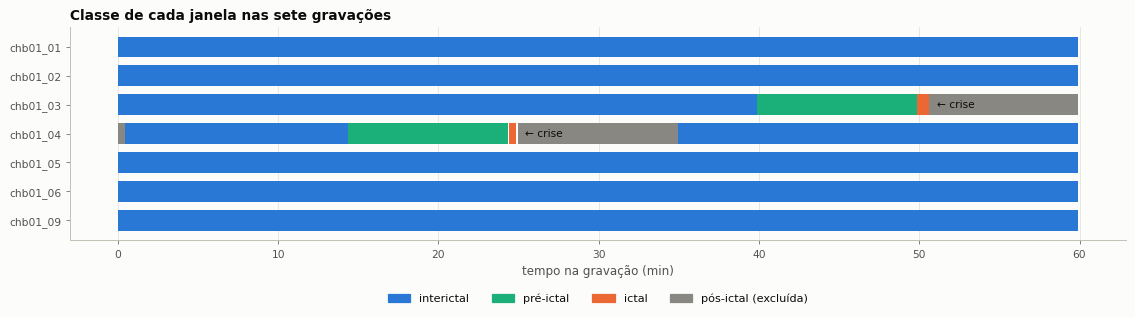

In [20]:
def rotular(df, gravacoes, janela_s=JANELA_S, horizonte_pre=HORIZONTE_PRE_S,
            exclusao_pos=EXCLUSAO_POS_S, fracao_ictal=FRACAO_ICTAL):
    """Atribui a classe de cada janela usando o tempo absoluto (entre arquivos)."""
    df = df.copy()
    a = df["t_abs"].to_numpy()              # início da janela
    b = a + janela_s                        # fim da janela
    centro = a + janela_s / 2
    classe = np.full(len(df), "interictal", dtype=object)
    crises = [c for g in gravacoes for c in g.crises_abs]
    nomes = [f"{g.nome}@{int(ini)}s" for g in gravacoes for ini, _ in g.crises]

    # ordem de precedência: pós-ictal < pré-ictal < transição < ictal
    for ini, fim in crises:
        classe[(a >= fim) & (a < fim + exclusao_pos)] = "pos-ictal"
    for ini, fim in crises:
        classe[(b <= ini) & (b > ini - horizonte_pre)] = "pre-ictal"
    for ini, fim in crises:
        sobre = np.clip(np.minimum(b, fim) - np.maximum(a, ini), 0, None) / janela_s   # fração dentro da crise
        classe[(sobre > 0) & (sobre < fracao_ictal)] = "transicao"
    for ini, fim in crises:
        sobre = np.clip(np.minimum(b, fim) - np.maximum(a, ini), 0, None) / janela_s
        classe[sobre >= fracao_ictal] = "ictal"

    df["classe"] = classe
    if crises:
        inis = np.array([c[0] for c in crises])
        idx = np.argmin(np.abs(centro[:, None] - inis[None, :]), axis=1)
        df["t_rel_crise"] = centro - inis[idx]                   # tempo relativo à crise mais próxima
        df["crise_proxima"] = np.array(nomes, dtype=object)[idx]
    else:
        df["t_rel_crise"] = np.nan
        df["crise_proxima"] = ""
    return df


def tabela_janelas(gravacoes, janela_s=JANELA_S, passo_s=PASSO_S):
    """Uma linha por janela de todas as gravações, com tempos locais e absolutos."""
    linhas = []
    for g in gravacoes:
        for t in np.arange(0.0, g.duracao - janela_s + 1e-9, passo_s):
            linhas.append((g.nome, t, t + janela_s, t + g.inicio_abs))
    df = pd.DataFrame(linhas, columns=["gravacao", "t_ini", "t_fim", "t_abs"])
    return rotular(df, gravacoes, janela_s)


janelas = tabela_janelas(gravs)
contagem = janelas.classe.value_counts()
print(f"{len(janelas)} janelas no total")
print(contagem.to_string())
print(f"\nFração ictal: {100 * contagem['ictal'] / len(janelas):.2f} % das janelas")

fig, ax = plt.subplots(figsize=(12.5, 3.4), constrained_layout=True)
for i, g in enumerate(gravs):
    sub = janelas[janelas.gravacao == g.nome]
    for classe in ["interictal", "pre-ictal", "pos-ictal", "ictal"]:
        t = sub.t_ini[sub.classe == classe].to_numpy()
        ax.broken_barh([(ti / 60, PASSO_S / 60) for ti in t], (i - 0.36, 0.72),
                       facecolors=COR_CLASSE[classe], linewidth=0)
    for a, b in g.crises:
        ax.text(b / 60 + 0.5, i, "← crise", ha="left", va="center", fontsize=8.5, color=TINTA)
ax.set_yticks(range(len(gravs)), [g.nome for g in gravs])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("tempo na gravação (min)")
ax.set_title("Classe de cada janela nas sete gravações")
ax.legend(handles=[Patch(color=COR_CLASSE[c], label=ROTULO_CLASSE[c] + (" (excluída)" if c == "pos-ictal" else ""))
                   for c in ["interictal", "pre-ictal", "ictal", "pos-ictal"]],
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=4)
plt.show()

**O que observar.** São quase sete horas de EEG e pouco mais de um minuto de crise: **18 janelas ictais em 6 293** (0,3 %). Dois efeitos disso atravessam o resto do notebook:

- Qualquer estatística sobre a classe ictal se apoia em 18 janelas vindas de apenas dois eventos. Nada aqui é confirmatório.
- As duas crises estão em gravações vizinhas (`chb01_03` e `chb01_04`), cerca de 35 minutos uma da outra. Se o EEG dessas horas for diferente do das outras por qualquer motivo, as janelas ictais herdam essa diferença. Esse é o "efeito de gravação" da Seção 5.

## 3. Como escolher $\tau$ e $d$

O enunciado sugere $d=3$ e $\tau=4$. O teorema de Takens garante que a reconstrução funciona para $d$ grande o bastante e quase qualquer $\tau$, mas com dados finitos e ruidosos a escolha importa (Seção 1.1). Três critérios clássicos orientam a escolha a partir do próprio sinal:

| Critério | Ideia | Regra |
|---|---|---|
| **Autocorrelação** | $x(t)$ e $x(t+\tau)$ não devem ser redundantes | primeiro $\tau$ em que a autocorrelação cai abaixo de $1/e$ |
| **Informação mútua média** (Fraser e Swinney, 1986) | o mesmo, mas captando também dependência não linear | primeiro **mínimo local** de $I\big(x(t);\,x(t+\tau)\big)$ |
| **Falsos vizinhos** (Kennel, Brown e Abarbanel, 1992) | se $d$ é pequeno demais, pontos distantes do atrator aparecem como vizinhos por projeção | menor $d$ em que a fração de falsos vizinhos fica abaixo de um limiar |

**Intuição dos falsos vizinhos.** Projete uma mola em uma folha de papel: voltas diferentes caem umas sobre as outras, e pontos de voltas distintas parecem vizinhos. Passando de $d$ para $d+1$ dimensões, um vizinho verdadeiro continua perto; um vizinho *falso* salta para longe. Quando aumentar $d$ quase não separa mais ninguém, o atrator já está desdobrado.

**Cuidado metodológico.** A escolha usa somente trechos **interictais da gravação `chb01_01`**, que não tem crise. Ela não usa os rótulos nem o desempenho de classificador algum; se usasse, estaríamos ajustando parâmetros nos mesmos dados em que depois medimos o resultado. As curvas dos trechos ictais aparecem na figura apenas como descrição.

In [21]:
def autocorrelacao(x, max_lag):
    x = padronizar(x)
    n = len(x)
    return np.array([1.0] + [float(np.dot(x[:-k], x[k:]) / (n - k)) for k in range(1, max_lag + 1)])


def atraso_autocorrelacao(acf):
    """Primeiro atraso com autocorrelação < 1/e e primeiro cruzamento por zero (None se não houver)."""
    abaixo = np.flatnonzero(acf < 1 / np.e)
    zero = np.flatnonzero(acf <= 0)
    return (int(abaixo[0]) if len(abaixo) else None, int(zero[0]) if len(zero) else None)


def informacao_mutua(x, max_lag, bins=16):
    """Informação mútua média I(x(t); x(t+k)) em bits, por histograma equiprovável."""
    x = np.asarray(x, dtype=float)
    # caixas com a mesma quantidade de pontos: a estimativa não depende da escala da amplitude
    postos = np.argsort(np.argsort(x))
    q = (postos * bins // len(x)).astype(int)
    ami = []
    for k in range(max_lag + 1):
        a, b = (q, q) if k == 0 else (q[:-k], q[k:])
        pxy = np.bincount(a * bins + b, minlength=bins * bins).reshape(bins, bins).astype(float)
        pxy /= pxy.sum()                                       # distribuição conjunta
        px, py = pxy.sum(1, keepdims=True), pxy.sum(0, keepdims=True)
        nz = pxy > 0
        ami.append(float(np.sum(pxy[nz] * np.log2(pxy[nz] / (px @ py)[nz]))))
    return np.array(ami)


def primeiro_minimo(curva):
    """Índice do primeiro mínimo local (None se a curva for monótona)."""
    for k in range(1, len(curva) - 1):
        if curva[k] < curva[k - 1] and curva[k] <= curva[k + 1]:
            return k
    return None


def falsos_vizinhos(x, atraso, dims=range(1, 9), rtol=15.0, atol=2.0):
    """Fração de falsos vizinhos mais próximos (Kennel, Brown & Abarbanel, 1992).

    Um vizinho em dimensão d é falso se, ao passar para d+1, a distância cresce mais que
    `rtol` vezes, ou se a nova distância excede `atol` desvios-padrão do sinal.
    """
    x = padronizar(x)
    fracoes = []
    for d in dims:
        n = len(x) - d * atraso
        if n <= 10:
            fracoes.append(np.nan)
            continue
        emb = np.column_stack([x[i * atraso: i * atraso + n] for i in range(d)])
        dist, idx = cKDTree(emb).query(emb, k=2)               # k=2: o 1º vizinho é o próprio ponto
        r, viz = dist[:, 1], idx[:, 1]
        extra = np.abs(x[d * atraso: d * atraso + n] - x[viz + d * atraso])   # separação na coordenada nova
        ok = r > 0
        falso = (extra[ok] / r[ok] > rtol) | (np.sqrt(r[ok] ** 2 + extra[ok] ** 2) > atol)
        fracoes.append(float(falso.mean()) if ok.any() else np.nan)
    return np.array(fracoes)


def dimensao_fnn(fracoes, dims, limiar=0.05):
    """Menor dimensão cuja fração de falsos vizinhos fica abaixo de `limiar`."""
    for d, f in zip(dims, fracoes):
        if np.isfinite(f) and f < limiar:
            return int(d)
    return None

Autocorrelação abaixo de 1/e:         τ = 5 amostras (78 ms)
Primeiro mínimo da informação mútua:  τ = 7 amostras (109 ms)
Falsos vizinhos (mediana) por dimensão: d=1: 99 %, d=2: 65 %, d=3: 22 %, d=4: 9 %, d=5: 7 %, d=6: 7 %, d=7: 7 %, d=8: 8 %

Sugestão dos dados: d = 4, τ = 7   |   enunciado: d = 3, τ = 4


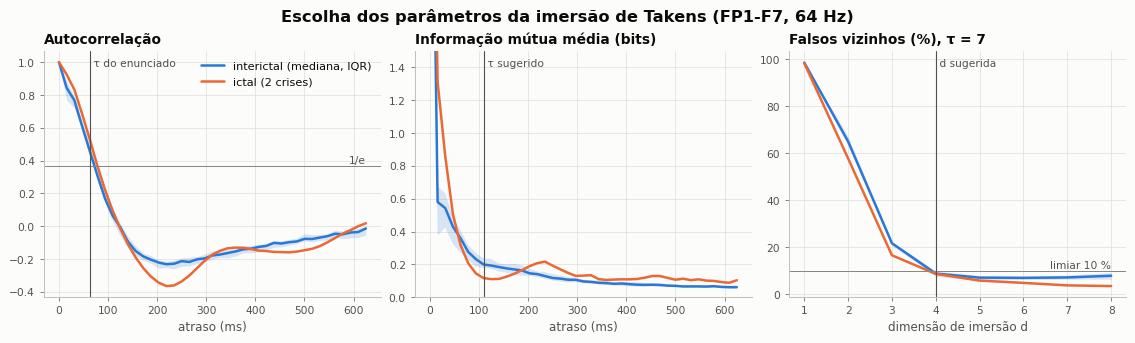

In [22]:
MAX_LAG = 40          # 40 amostras = 625 ms a 64 Hz
DIMS_FNN = list(range(1, 9))
TRECHO_S = 60.0
N_TRECHOS = 30
LIMIAR_FNN = 0.10     # fixado a priori; EEG ruidoso não chega a 0 % de falsos vizinhos


def mediana_valida(v):
    v = [u for u in v if u is not None]
    return int(np.median(v)) if v else None


def curvas(segmentos, atraso_fnn):
    acf = np.array([autocorrelacao(s, MAX_LAG) for s in segmentos])
    ami = np.array([informacao_mutua(s, MAX_LAG) for s in segmentos])
    fnn = np.array([falsos_vizinhos(s, atraso_fnn, DIMS_FNN) for s in segmentos])
    return acf, ami, fnn


# 30 trechos interictais de 60 s, espalhados pela gravação sem crise
x1, fs = carregar_canal(gravs_por_nome["chb01_01"].caminho)
n = int(TRECHO_S * fs)
inter = [x1[i: i + n] for i in np.linspace(0, len(x1) - n, N_TRECHOS).astype(int)]

# os dois trechos ictais, só para descrição
ictais = []
for g in gravs:
    for a, b in g.crises:
        xg, _ = carregar_canal(g.caminho)
        ictais.append(xg[int(a * fs): int(b * fs)])

# 1) atraso: autocorrelação e informação mútua em cada trecho interictal
acf_i = np.array([autocorrelacao(s, MAX_LAG) for s in inter])
ami_i = np.array([informacao_mutua(s, MAX_LAG) for s in inter])
tau_e = [atraso_autocorrelacao(a)[0] for a in acf_i]
tau_ami = [primeiro_minimo(a) for a in ami_i]
ATRASO_DADOS = mediana_valida(tau_ami) or mediana_valida(tau_e)

# 2) dimensão: falsos vizinhos usando o atraso escolhido
acf_i, ami_i, fnn_i = curvas(inter, ATRASO_DADOS)
acf_c, ami_c, fnn_c = curvas(ictais, ATRASO_DADOS)
fnn_med = np.nanmedian(fnn_i, axis=0)
DIM_DADOS = dimensao_fnn(fnn_med, DIMS_FNN, LIMIAR_FNN) or DIMS_FNN[-1]

print(f"Autocorrelação abaixo de 1/e:         τ = {mediana_valida(tau_e)} amostras "
      f"({1000 * mediana_valida(tau_e) / fs:.0f} ms)")
print(f"Primeiro mínimo da informação mútua:  τ = {mediana_valida(tau_ami)} amostras "
      f"({1000 * mediana_valida(tau_ami) / fs:.0f} ms)")
print("Falsos vizinhos (mediana) por dimensão:",
      ", ".join(f"d={d}: {100 * f:.0f} %" for d, f in zip(DIMS_FNN, fnn_med)))
print(f"\nSugestão dos dados: d = {DIM_DADOS}, τ = {ATRASO_DADOS}   |   enunciado: d = {DIM}, τ = {ATRASO}")

lags_ms = 1000 * np.arange(MAX_LAG + 1) / fs
fig, eixos = plt.subplots(1, 3, figsize=(12.5, 3.7), constrained_layout=True)
paineis = [
    (eixos[0], lags_ms, acf_i, acf_c, "Autocorrelação", "atraso (ms)"),
    (eixos[1], lags_ms, ami_i, ami_c, "Informação mútua média (bits)", "atraso (ms)"),
    (eixos[2], np.array(DIMS_FNN), fnn_i * 100, fnn_c * 100,
     f"Falsos vizinhos (%), τ = {ATRASO_DADOS}", "dimensão de imersão d"),
]
for ax, xs_, inter_c, ict_c, titulo, xl in paineis:
    q1_, q3_ = np.nanpercentile(inter_c, [25, 75], axis=0)
    ax.fill_between(xs_, q1_, q3_, color=COR_CLASSE["interictal"], alpha=0.18, lw=0)
    ax.plot(xs_, np.nanmedian(inter_c, 0), color=COR_CLASSE["interictal"], lw=2, label="interictal (mediana, IQR)")
    ax.plot(xs_, np.nanmedian(ict_c, 0), color=COR_CLASSE["ictal"], lw=2, label="ictal (2 crises)")
    ax.set_title(titulo)
    ax.set_xlabel(xl)
eixos[0].axhline(1 / np.e, color=MUDO, lw=0.8)
eixos[0].text(lags_ms[-1], 1 / np.e, "1/e", ha="right", va="bottom", fontsize=8.5, color=TINTA_2)
eixos[2].axhline(100 * LIMIAR_FNN, color=MUDO, lw=0.8)
eixos[2].text(DIMS_FNN[-1], 100 * LIMIAR_FNN, f"limiar {100 * LIMIAR_FNN:.0f} %", ha="right", va="bottom",
              fontsize=8.5, color=TINTA_2)
for ax, v, txt in [(eixos[0], 1000 * ATRASO / fs, "τ do enunciado"),
                   (eixos[1], 1000 * ATRASO_DADOS / fs, "τ sugerido"), (eixos[2], DIM_DADOS, "d sugerida")]:
    ax.axvline(v, color=TINTA_2, lw=0.9)
    ax.text(v, 0.97, f" {txt}", transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=8.5, color=TINTA_2)
eixos[1].set_ylim(0, 1.5)      # o valor em atraso 0 (a entropia do sinal) fica fora da escala
eixos[0].legend(loc="upper right")
fig.suptitle(f"Escolha dos parâmetros da imersão de Takens ({CANAL}, {fs:.0f} Hz)")
plt.show()

**O que observar.**

- **Autocorrelação:** cai abaixo de $1/e$ em 5 amostras (78 ms). O $\tau=4$ do enunciado fica um pouco antes disso: as coordenadas ainda são algo redundantes, mas não muito.
- **Informação mútua:** o primeiro mínimo fica em 7 amostras (109 ms).
- **Falsos vizinhos:** caem de 22 % em $d=3$ para 9 % em $d=4$ e praticamente param de cair. Não chegam a zero porque o EEG tem ruído, e ruído não se desdobra em dimensão nenhuma.

Os critérios apontam para **$d=4$, $\tau=7$**, perto mas não igual ao **$d=3$, $\tau=4$** do enunciado. Em vez de escolher, o projeto leva as duas configurações adiante: a do enunciado é a principal, e a "dos dados" entra como comparação na Seção 6. A Seção 9 varre uma grade inteira de valores.

## 4. O pipeline em todas as janelas

Agora o caminho completo, repetido em cada uma das 6 293 janelas:

**EEG filtrado → janela de 8 s → padronização → nuvem de Takens (126 pontos em $\mathbb{R}^3$) → Vietoris–Rips → diagrama de $H_1$ → 15 descritores**

### 4.1 Um baseline clássico, para ter com o que comparar

Um descritor topológico só é interessante se trouxer algo que descritores simples não trazem. Por isso cada janela recebe também 12 descritores clássicos de EEG, em dois grupos:

| Grupo | Descritores | Observação |
|---|---|---|
| **Amplitude** (3) | log da variância, log do comprimento de linha, log da potência total | usam a escala do sinal em µV |
| **Forma** (9) | potências relativas delta, teta, alfa e beta; entropia espectral; frequência de pico; mobilidade e complexidade de Hjorth; cruzamentos por zero | não mudam se o sinal for multiplicado por uma constante |

A separação em dois grupos é uma questão de justiça na comparação. A imersão de Takens padroniza cada janela, logo os descritores topológicos **não enxergam a amplitude**. O grupo "só forma" está sob a mesma restrição.

In [23]:
BANDAS = {"delta": (1, 4), "teta": (4, 8), "alfa": (8, 13), "beta": (13, 30)}
COLUNAS_AMPLITUDE = ["log_variancia", "log_comp_linha", "log_potencia"]
COLUNAS_FORMA = ["rel_delta", "rel_teta", "rel_alfa", "rel_beta", "entropia_espectral",
                 "freq_pico", "hjorth_mobilidade", "hjorth_complexidade", "cruz_zero"]
COLUNAS_BASE = COLUNAS_AMPLITUDE + COLUNAS_FORMA


def descritores_classicos(seg, fs):
    seg = np.asarray(seg, dtype=float)
    x = seg - seg.mean()
    dx = np.diff(x)                    # primeira derivada
    ddx = np.diff(dx)                  # segunda derivada
    var, var_d, var_dd = x.var() + 1e-12, dx.var() + 1e-12, ddx.var() + 1e-12

    f, p = periodogram(x, fs=fs, window="hann")        # espectro de potência da janela
    faixa = (f >= 1) & (f <= 30)
    f, p = f[faixa], p[faixa] + 1e-20
    total = p.sum()
    pn = p / total

    d = {
        "log_variancia": float(np.log(var)),
        "log_comp_linha": float(np.log(np.abs(dx).sum() + 1e-12)),
        "log_potencia": float(np.log(total)),
        "entropia_espectral": float(-(pn * np.log(pn)).sum() / np.log(len(pn))),
        "freq_pico": float(f[np.argmax(p)]),
        "hjorth_mobilidade": float(np.sqrt(var_d / var)),
        "hjorth_complexidade": float(np.sqrt(var_dd / var_d) / np.sqrt(var_d / var)),
        "cruz_zero": float(np.mean(np.signbit(x[:-1]) != np.signbit(x[1:])) * fs),
    }
    for nome, (lo, hi) in BANDAS.items():
        d[f"rel_{nome}"] = float(p[(f >= lo) & (f < hi)].sum() / total)
    return d

### 4.2 A extração

`analisar_janela` é o pipeline de uma janela. `extrair` aplica essa função a todas as janelas de todas as gravações, em paralelo, e calcula a distância de bottleneck entre cada janela e a anterior da mesma gravação. O resultado é uma tabela com uma linha por janela e a lista dos diagramas, na mesma ordem.

In [24]:
def analisar_janela(seg, fs, dim, atraso, passo_nuvem, com_baseline, motor):
    """Descritores topológicos (e clássicos) de uma janela; devolve também o diagrama."""
    X = imersao_takens(seg, dim=dim, atraso=atraso, passo=passo_nuvem)     # 1. Takens
    h1, corte, cens = h1_rips(X, None, motor)                               # 2. Rips + H1
    d = descritores_h1(h1, corte, cens)                                     # 3. descritores
    d["n_pontos"] = len(X)
    if com_baseline:
        d.update(descritores_classicos(seg, fs))
    return d, h1


def extrair(gravacoes, canal=CANAL, dim=DIM, atraso=ATRASO, passo_nuvem=PASSO_NUVEM,
            janela_s=JANELA_S, passo_s=PASSO_S, com_baseline=True, com_bottleneck=True,
            recorte=None, so_classes=None, motor=None, verbose=True):
    """Tabela de janelas x descritores e lista de diagramas de H1 (mesma ordem).

    recorte = {gravacao: (t_min, t_max)} restringe a análise a um trecho.
    so_classes = lista de classes a manter (as demais janelas não são processadas).
    """
    motor = motor or MOTOR_EXTRACAO
    janelas = tabela_janelas(gravacoes, janela_s, passo_s)
    if recorte is not None:
        manter = np.zeros(len(janelas), dtype=bool)
        for nome, (a, b) in recorte.items():
            manter |= ((janelas.gravacao == nome) & (janelas.t_ini >= a) & (janelas.t_fim <= b)).to_numpy()
        janelas = janelas[manter].reset_index(drop=True)
    if so_classes is not None:
        janelas = janelas[janelas.classe.isin(so_classes)].reset_index(drop=True)

    partes, diagramas = [], []
    with Parallel(n_jobs=-1, batch_size=16) as par:            # um processo por núcleo disponível
        for g in gravacoes:
            sub = janelas[janelas.gravacao == g.nome]
            if sub.empty:
                continue
            x, fs = carregar_canal(g.caminho, canal)
            w = int(round(janela_s * fs))
            segs = [x[int(round(t * fs)): int(round(t * fs)) + w] for t in sub.t_ini]
            res = par(delayed(analisar_janela)(s, fs, dim, atraso, passo_nuvem, com_baseline, motor)
                      for s in segs)
            feats = pd.DataFrame([r[0] for r in res], index=sub.index)
            diags = [r[1] for r in res]
            if com_bottleneck:
                # d_B(D_t, D_{t-1}) entre janelas consecutivas da mesma gravação
                db = par(delayed(bottleneck)(diags[i - 1], diags[i]) for i in range(1, len(diags)))
                feats["bottleneck"] = [np.nan] + list(db)
            partes.append(pd.concat([sub, feats], axis=1))
            diagramas.extend(diags)
            if verbose:
                print(f"  {g.nome} [{canal}] {len(sub)} janelas")
    df = pd.concat(partes).reset_index(drop=True)
    df.insert(1, "canal", canal)
    return df, diagramas

### 4.3 GUDHI e Ripser dão a mesma resposta?

Antes de usar o Ripser na extração, conferimos em 30 janelas de EEG sorteadas se ele devolve as mesmas persistências que o GUDHI, e medimos o tempo de cada um.

In [25]:
def conferir_motores(gravacoes, n=30):
    rng = np.random.default_rng(SEMENTE)
    x, fs = carregar_canal(gravacoes[0].caminho)
    w = int(JANELA_S * fs)
    pior, tempo = 0.0, {"gudhi": 0.0, "ripser": 0.0}
    for i in rng.integers(0, len(x) - w, n):
        X = imersao_takens(x[i: i + w], DIM, ATRASO, PASSO_NUVEM)
        pers = {}
        for motor in tempo:
            t0 = time.perf_counter()
            h1 = h1_rips(X, motor=motor)[0]
            tempo[motor] += time.perf_counter() - t0
            p = np.sort(persistencias(h1))[::-1]
            pers[motor] = p[p > 1e-6]                 # ignora classes de persistência praticamente nula
        if len(pers["gudhi"]) != len(pers["ripser"]):
            return {"equivalente": False}
        if len(pers["gudhi"]):
            pior = max(pior, float(np.abs(pers["gudhi"] - pers["ripser"]).max()))
    return {"equivalente": pior < 1e-5, "maior_diferenca": pior,
            "ms_por_janela": {m: round(1000 * t / n, 1) for m, t in tempo.items()}}


conf = conferir_motores(gravs)
print(conf)
assert conf["equivalente"], "GUDHI e Ripser divergiram; use MOTOR_EXTRACAO = 'gudhi'."

{'equivalente': True, 'maior_diferenca': 2.7241823108425933e-07, 'ms_por_janela': {'gudhi': 106.9, 'ripser': 4.2}}


**O que observar.** A maior diferença entre as persistências fica na sétima casa decimal (o Ripser trabalha com números de precisão simples), e o Ripser é uma ordem de grandeza mais rápido. A única discrepância possível está em classes de persistência praticamente nula, que um motor pode listar e o outro não; isso pode alterar o **número de classes** de uma janela em uma unidade, e por consequência a terceira casa decimal de algum resultado mais adiante em relação ao projeto original.

### 4.4 Três extrações

1. **Principal:** todas as janelas, parâmetros do enunciado ($d=3$, $\tau=4$, passo de 4 s).
2. **Zoom:** só os minutos em torno de cada crise, com passo de **1 s**, para as figuras de detalhe e a animação.
3. **Alternativa:** todas as janelas, com $(d,\tau)$ sugeridos pelos dados na Seção 3.

In [26]:
t0 = time.time()
print(f"[1] Configuração do enunciado (d={DIM}, τ={ATRASO}), motor: {MOTOR_EXTRACAO}")
df, diagramas = extrair(gravs)
print(f"    {len(df)} janelas, {int(df.n_pontos.iloc[0])} pontos por nuvem, "
      f"{int(df.h1_censuradas.sum())} classes censuradas | {time.time() - t0:.0f} s")

print("[2] Recorte em torno das crises, passo de 1 s")
MARGEM_ANTES, MARGEM_DEPOIS = 300.0, 180.0
recorte = {g.nome: (max(0.0, g.crises[0][0] - MARGEM_ANTES), min(g.duracao, g.crises[0][1] + MARGEM_DEPOIS))
           for g in gravs if g.crises}
zoom, diagramas_zoom = extrair(gravs, passo_s=1.0, recorte=recorte)

print(f"[3] Configuração sugerida pelos dados (d={DIM_DADOS}, τ={ATRASO_DADOS})")
df_alt, _ = extrair(gravs, dim=DIM_DADOS, atraso=ATRASO_DADOS, com_bottleneck=False, verbose=False)
print(f"Tempo total: {time.time() - t0:.0f} s")

[1] Configuração do enunciado (d=3, τ=4), motor: ripser


  chb01_01 [FP1-F7] 899 janelas


  chb01_02 [FP1-F7] 899 janelas


  chb01_03 [FP1-F7] 899 janelas


  chb01_04 [FP1-F7] 899 janelas


  chb01_05 [FP1-F7] 899 janelas


  chb01_06 [FP1-F7] 899 janelas


  chb01_09 [FP1-F7] 899 janelas
    6293 janelas, 126 pontos por nuvem, 0 classes censuradas | 16 s
[2] Recorte em torno das crises, passo de 1 s


  chb01_03 [FP1-F7] 513 janelas


  chb01_04 [FP1-F7] 500 janelas
[3] Configuração sugerida pelos dados (d=4, τ=7)


Tempo total: 29 s


In [27]:
print(df.classe.value_counts().to_string())
perto_da_crise = (df.gravacao == "chb01_03") & df.t_ini.between(2980, 3008)
display(df.loc[perto_da_crise, ["gravacao", "t_ini", "classe", "h1_n", "h1_pers_max", "h1_pers_total",
                                "h1_entropia", "h1_pais2_l1", "bottleneck", "log_variancia"]].round(3))

classe
interictal    5676
pre-ictal      300
pos-ictal      297
ictal           18
transicao        2


,gravacao,t_ini,classe,h1_n,h1_pers_max,h1_pers_total,h1_entropia,h1_pais2_l1,bottleneck,log_variancia
2543,chb01_03,2980.0,pre-ictal,44,0.270,4.171,3.501,0.031,0.167,6.587
2544,chb01_03,2984.0,pre-ictal,43,0.204,3.730,3.539,0.027,0.133,6.386
2545,chb01_03,2988.0,pre-ictal,40,0.229,3.125,3.382,0.019,0.090,6.951
2546,chb01_03,2992.0,ictal,36,0.296,3.399,3.211,0.036,0.146,7.493
2547,chb01_03,2996.0,ictal,51,0.330,4.768,3.560,0.047,0.146,8.034
2548,chb01_03,3000.0,ictal,43,0.268,3.736,3.349,0.028,0.139,8.717
2549,chb01_03,3004.0,ictal,38,0.430,4.531,3.245,0.079,0.207,8.995
2550,chb01_03,3008.0,ictal,34,0.432,3.000,3.128,0.029,0.190,8.986


Cada linha é uma janela: a identificação (`gravacao`, `t_ini`), a classe, os descritores de $H_1$ e os descritores clássicos. O trecho mostrado é a entrada na primeira crise (início anotado em 2 996 s). A tabela `df` é a matéria-prima de todas as seções seguintes.

## 5. $H_1$ ao longo do tempo × anotações de crise

Esta é a seção central. A pergunta é simples: os descritores de $H_1$ mudam quando a crise começa?

### 5.1 Em torno de cada crise

Primeiro, olhar. Para cada crise: o EEG e, abaixo dele, três descritores de $H_1$ calculados em janelas que avançam de 1 em 1 s, mais a distância de bottleneck entre janelas consecutivas. A **faixa cinza horizontal** é o intervalo interquartil do descritor nas janelas interictais de todas as gravações: é a região do "normal". A **faixa salmão vertical** é a crise.

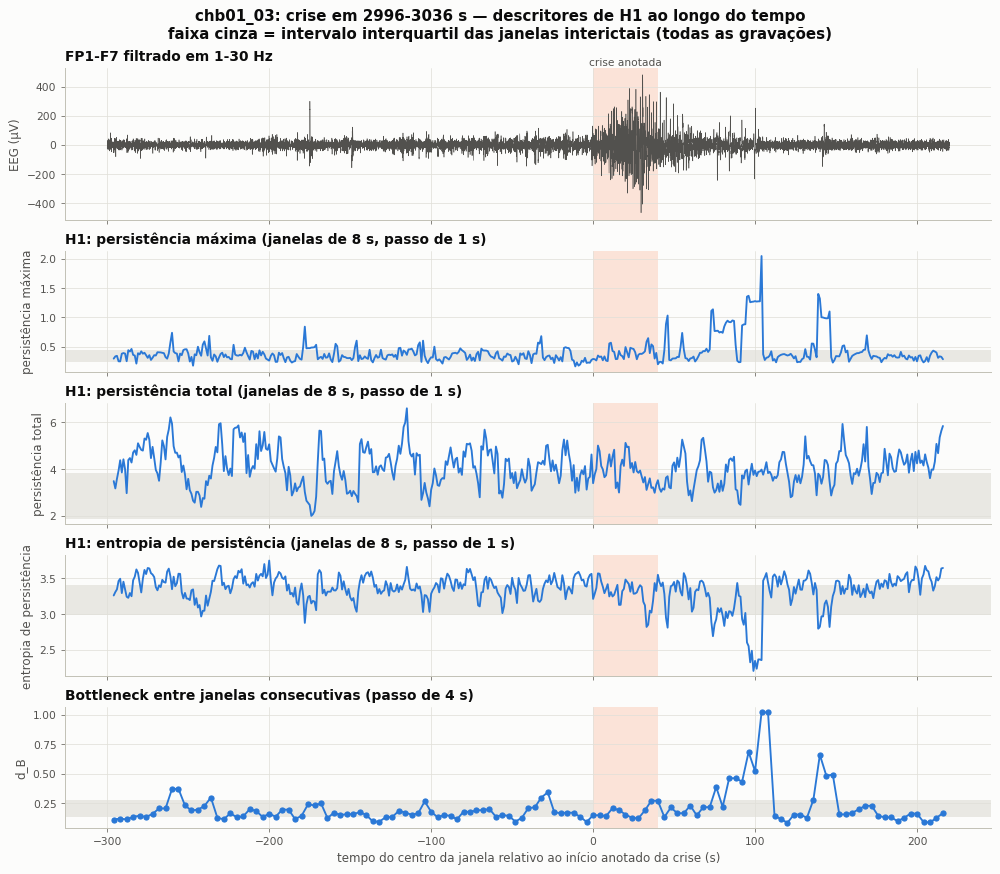

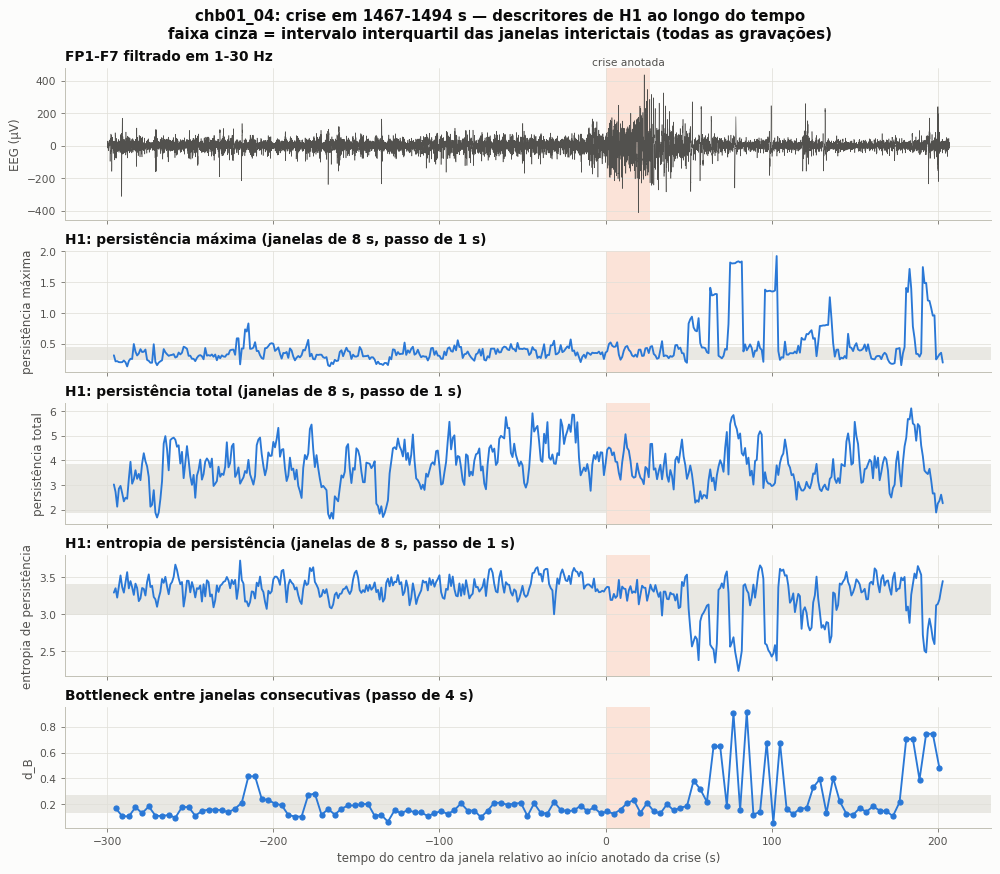

In [28]:
DESCR = {
    "h1_pers_max": "persistência máxima",
    "h1_pers_total": "persistência total",
    "h1_entropia": "entropia de persistência",
    "h1_n": "nº de classes em H1",
    "h1_pais2_l1": "norma L1 da paisagem λ2",
    "bottleneck": "bottleneck d_B(D_t, D_t-1)",
}
PRINCIPAIS = ["h1_pers_max", "h1_pers_total", "h1_entropia", "bottleneck"]
COLUNAS = COLUNAS_TOPO + ["bottleneck"] + COLUNAS_BASE

inter_ref = df[df.classe == "interictal"]
REF = {c: tuple(inter_ref[c].quantile([0.25, 0.75])) for c in PRINCIPAIS}     # faixa "normal" de cada descritor


def fig_detalhe(g):
    """EEG e descritores em torno de uma crise (tempo relativo ao início anotado)."""
    ini, fim = g.crises[0]
    x, fs = carregar_canal(g.caminho)
    z = zoom[zoom.gravacao == g.nome]
    a, b = z.t_ini.min(), z.t_fim.max()
    tz = (z.t_ini + JANELA_S / 2 - ini).to_numpy()
    p = df[(df.gravacao == g.nome) & (df.t_ini >= a) & (df.t_fim <= b)]
    tp = (p.t_ini + JANELA_S / 2 - ini).to_numpy()

    fig, eixos = plt.subplots(5, 1, figsize=(11, 9.6), sharex=True, constrained_layout=True,
                              gridspec_kw={"height_ratios": [1.25, 1, 1, 1, 1]})
    i0, i1 = int(a * fs), int(b * fs)
    eixos[0].plot(np.arange(i0, i1) / fs - ini, x[i0:i1], color=TINTA_2, lw=0.45)
    eixos[0].set_ylabel("EEG (µV)")
    eixos[0].set_title(f"{CANAL} filtrado em 1-30 Hz")
    for ax, c in zip(eixos[1:4], PRINCIPAIS[:3]):
        ax.axhspan(*REF[c], color=GRADE, alpha=0.7, lw=0, zorder=0)
        ax.plot(tz, z[c], color=AZUL, lw=1.5)
        ax.set_ylabel(DESCR[c])
        ax.set_title(f"H1: {DESCR[c]} (janelas de 8 s, passo de 1 s)")
    ax = eixos[4]
    ax.axhspan(*REF["bottleneck"], color=GRADE, alpha=0.7, lw=0, zorder=0)
    ax.plot(tp, p["bottleneck"], color=AZUL, lw=1.5, marker="o", ms=4)
    ax.set_ylabel("d_B")
    ax.set_title("Bottleneck entre janelas consecutivas (passo de 4 s)")
    ax.set_xlabel("tempo do centro da janela relativo ao início anotado da crise (s)")
    for k, ax in enumerate(eixos):
        faixa_crise(ax, 0, fim - ini, "crise anotada" if k == 0 else None)
    fig.suptitle(f"{g.nome}: crise em {ini:.0f}-{fim:.0f} s — descritores de H1 ao longo do tempo\n"
                 "faixa cinza = intervalo interquartil das janelas interictais (todas as gravações)",
                 fontsize=12)
    plt.show()


for g in gravs:
    if g.crises:
        fig_detalhe(g)

**O que observar.** No EEG a crise é inconfundível. Nos descritores de $H_1$, não: dentro da faixa salmão as curvas não fazem nada que já não fizessem antes dela. A persistência máxima oscila do mesmo jeito, e a persistência total já estava acima da faixa cinza minutos **antes** de a crise começar. Há picos isolados de persistência máxima um ou dois minutos depois do fim da crise; a Seção 5.7 mostra de onde eles vêm.

### 5.2 Janelas típicas de cada classe

Para ver o que a topologia "enxerga", uma janela representativa de cada classe: aquela cuja persistência máxima está mais perto da mediana da classe (na gravação `chb01_03`).

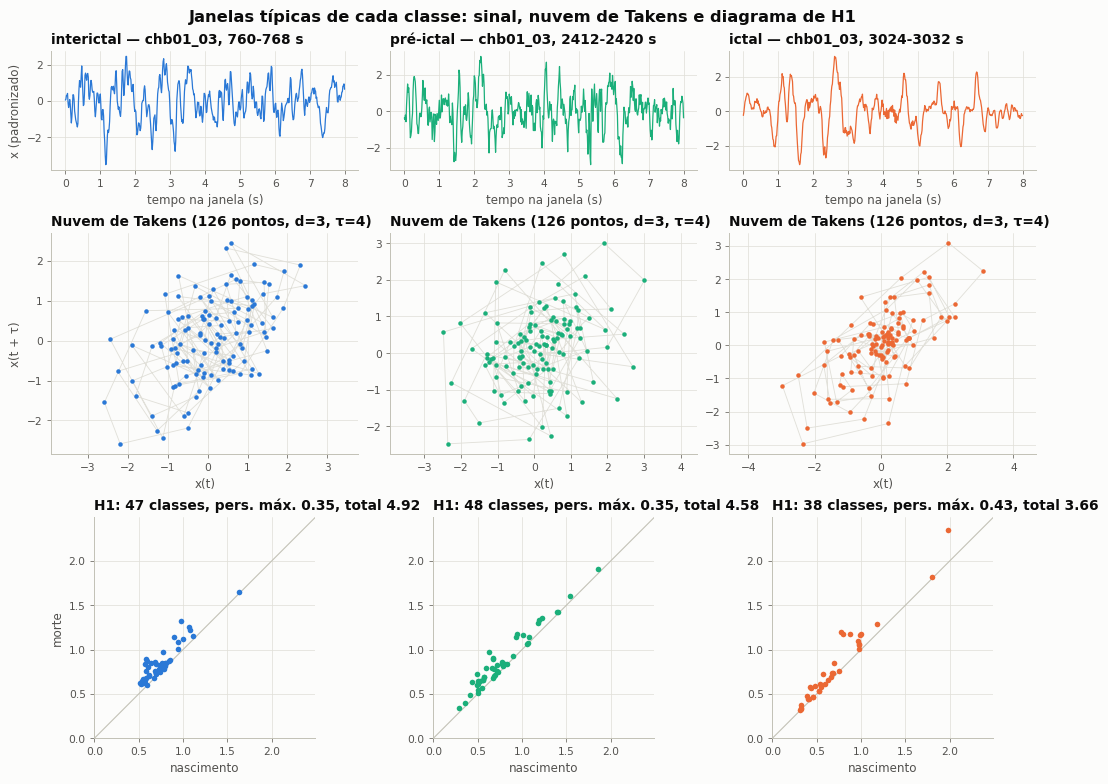

In [29]:
def fig_exemplos(g):
    """Janela típica (persistência máxima mais próxima da mediana da classe) de cada classe."""
    x, fs = carregar_canal(g.caminho)
    w = int(JANELA_S * fs)
    fig, eixos = plt.subplots(3, 3, figsize=(11.5, 8.6), constrained_layout=True,
                              gridspec_kw={"height_ratios": [0.7, 1.3, 1.3]})
    escolhidas, lim_d = [], 0.0
    for classe in CLASSES:
        sub = df[(df.gravacao == g.nome) & (df.classe == classe)]
        i = (sub.h1_pers_max - sub.h1_pers_max.median()).abs().idxmin()
        escolhidas.append((classe, i))
        lim_d = max(lim_d, diagramas[i][:, 1].max())
    lim_d *= 1.06
    for j, (classe, i) in enumerate(escolhidas):
        cor = COR_CLASSE[classe]
        t0 = df.loc[i, "t_ini"]
        seg = x[int(t0 * fs): int(t0 * fs) + w]
        X = imersao_takens(seg, DIM, ATRASO, PASSO_NUVEM)
        h1 = diagramas[i]
        a, b, c = eixos[:, j]
        a.plot(np.arange(w) / fs, padronizar(seg), color=cor, lw=1)
        a.set_title(f"{ROTULO_CLASSE[classe]} — {g.nome}, {t0:.0f}-{t0 + JANELA_S:.0f} s")
        a.set_xlabel("tempo na janela (s)")
        b.plot(X[:, 0], X[:, 1], color=GRADE, lw=0.7, zorder=1)
        b.scatter(X[:, 0], X[:, 1], s=13, color=cor, linewidths=0, zorder=2)
        b.set_aspect("equal", adjustable="datalim")
        b.set_title(f"Nuvem de Takens ({len(X)} pontos, d={DIM}, τ={ATRASO})")
        b.set_xlabel("x(t)")
        desenhar_diagrama(c, h1, cor=cor, lim=lim_d, s=20)
        c.set_ylabel("")
        c.set_title(f"H1: {len(h1)} classes, pers. máx. {df.loc[i, 'h1_pers_max']:.2f}, "
                    f"total {df.loc[i, 'h1_pers_total']:.2f}")
    eixos[0, 0].set_ylabel("x (padronizado)")
    eixos[1, 0].set_ylabel("x(t + τ)")
    eixos[2, 0].set_ylabel("morte")
    fig.suptitle("Janelas típicas de cada classe: sinal, nuvem de Takens e diagrama de H1")
    plt.show()


fig_exemplos(gravs_por_nome["chb01_03"])

**O que observar.** Compare com a Seção 1.4. Nenhuma das três nuvens se parece com o laço limpo da senoide: todas são um novelo sem buraco central, e os três diagramas têm só pontos perto da diagonal. A nuvem ictal é mais alongada na direção da diagonal: as ondas lentas da crise fazem $x(t+\tau)$ ficar parecido com $x(t)$, o caso "$\tau$ pequeno demais" da Seção 1.1. Além disso, o ritmo da crise não é regular o bastante, nem domina a janela o bastante, para abrir um buraco que o Rips consiga ver. Estamos no regime de 0 dB ou pior da Seção 1.4.

### 5.3 Separação entre classes: AUROC

Para quantificar, usamos a **AUROC** de cada descritor, sozinho, na tarefa de separar duas classes.

**Intuição.** Sorteie uma janela ictal e uma interictal. A AUROC é a probabilidade de o descritor ser maior na ictal. **0,5** significa nenhuma separação (cara ou coroa); **1,0**, separação perfeita; valores abaixo de 0,5 indicam que o descritor tende a ser *menor* na crise (0,1 separa tão bem quanto 0,9). A AUROC não depende de limiar nem da escala do descritor, e não se deixa enganar pelo desbalanceamento de 18 contra 5 676.

Cada AUROC é calculada duas vezes, com duas referências:

- **todas as gravações:** as 18 janelas ictais contra as 5 676 interictais das sete gravações;
- **mesmas gravações:** as 18 janelas ictais contra as interictais apenas de `chb01_03` e `chb01_04`, as duas horas em que as crises aconteceram.

Se um descritor realmente reage à crise, as duas contas devem dar parecido.

In [30]:
def auc(pos, neg):
    """AUROC de um descritor: P(valor em 'pos' > valor em 'neg')."""
    pos, neg = pos[np.isfinite(pos)], neg[np.isfinite(neg)]
    if len(pos) == 0 or len(neg) == 0:
        return np.nan
    return roc_auc_score(np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos, neg])


def tabela_classes(df):
    com_crise = df.gravacao.isin(df.loc[df.classe == "ictal", "gravacao"].unique()).to_numpy()
    cl = df.classe.to_numpy()
    linhas = []
    for c in COLUNAS:
        v = df[c].to_numpy(float)
        inter, inter_m = v[cl == "interictal"], v[(cl == "interictal") & com_crise]
        linhas.append({
            "descritor": c,
            "grupo": "topologico" if c.startswith("h1_") or c == "bottleneck" else "classico",
            "mediana_interictal": np.nanmedian(inter),
            "mediana_pre_ictal": np.nanmedian(v[cl == "pre-ictal"]),
            "mediana_ictal": np.nanmedian(v[cl == "ictal"]),
            "auc_ictal_vs_inter": auc(v[cl == "ictal"], inter),
            "auc_ictal_vs_inter_mesma_grav": auc(v[cl == "ictal"], inter_m),
            "auc_pre_vs_inter": auc(v[cl == "pre-ictal"], inter),
            "auc_pre_vs_inter_mesma_grav": auc(v[cl == "pre-ictal"], inter_m),
            "auc_pos_vs_inter_mesma_grav": auc(v[cl == "pos-ictal"], inter_m),
        })
    return pd.DataFrame(linhas)


tab = tabela_classes(df)
display(tab.drop(columns=["auc_pos_vs_inter_mesma_grav"]).round(3))

,descritor,grupo,mediana_interictal,mediana_pre_ictal,mediana_ictal,auc_ictal_vs_inter,auc_ictal_vs_inter_mesma_grav,auc_pre_vs_inter,auc_pre_vs_inter_mesma_grav
0,h1_n,topologico,39.000,43.000,38.500,0.522,0.378,0.674,0.533
1,h1_pers_max,topologico,0.331,0.333,0.416,0.596,0.597,0.519,0.479
2,h1_pers_total,topologico,2.662,4.063,3.698,0.754,0.486,0.783,0.565
3,h1_pers_media,topologico,0.069,0.095,0.094,0.791,0.576,0.770,0.560
4,h1_entropia,topologico,3.243,3.398,3.271,0.585,0.367,0.719,0.549
5,h1_dominancia,topologico,0.108,0.083,0.096,0.389,0.578,0.279,0.422
6,h1_pers_2a,topologico,0.233,0.283,0.297,0.719,0.619,0.664,0.533
7,h1_nasc_max,topologico,1.039,0.837,0.803,0.386,0.477,0.411,0.501
8,h1_morte_max,topologico,1.387,1.177,1.213,0.415,0.502,0.418,0.493
9,h1_pais1_l1,topologico,0.051,0.077,0.090,0.742,0.610,0.697,0.537


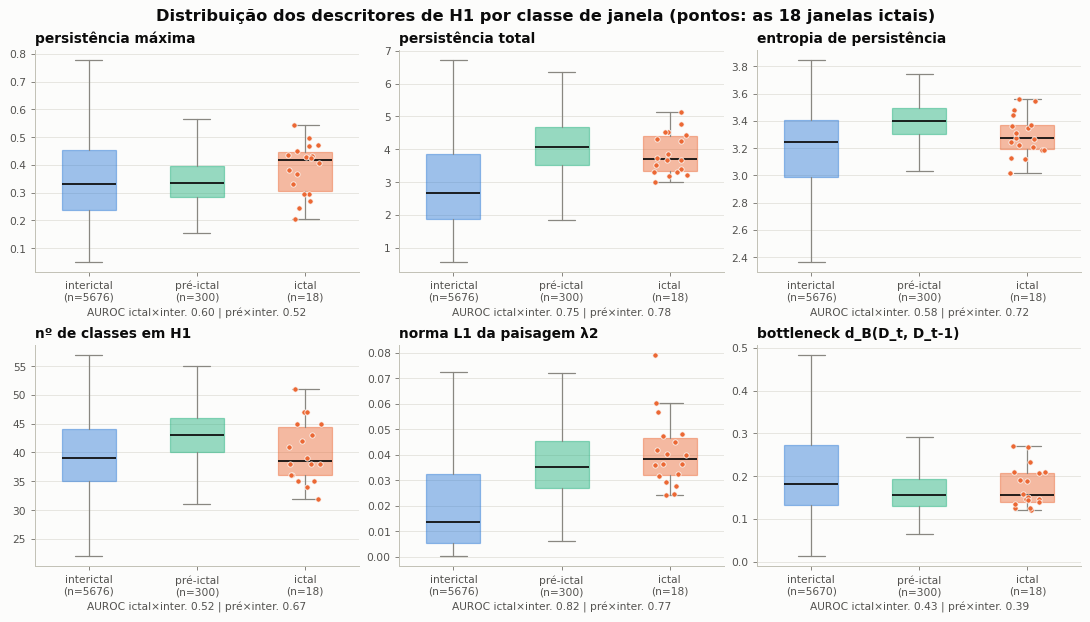

In [31]:
rng_fig = np.random.default_rng(SEMENTE)
fig, eixos = plt.subplots(2, 3, figsize=(12, 6.8), constrained_layout=True)
for ax, (c, nome) in zip(eixos.ravel(), DESCR.items()):
    dados_c = [df.loc[df.classe == k, c].dropna().to_numpy() for k in CLASSES]
    bp = ax.boxplot(dados_c, widths=0.5, showfliers=False, patch_artist=True,
                    medianprops={"color": TINTA, "lw": 1.4},
                    whiskerprops={"color": MUDO}, capprops={"color": MUDO})
    for caixa, k in zip(bp["boxes"], CLASSES):
        caixa.set(facecolor=COR_CLASSE[k], alpha=0.45, edgecolor=COR_CLASSE[k])
    ict = dados_c[2]
    ax.scatter(3 + rng_fig.uniform(-0.16, 0.16, len(ict)), ict, s=18, zorder=3,
               color=COR_CLASSE["ictal"], edgecolor=SUPERFICIE, linewidths=0.6)
    ax.set_xticks([1, 2, 3], [f"{ROTULO_CLASSE[k]}\n(n={len(d)})" for k, d in zip(CLASSES, dados_c)])
    ax.grid(axis="x", visible=False)
    r_ = tab.set_index("descritor").loc[c]
    ax.set_title(nome)
    ax.set_xlabel(f"AUROC ictal×inter. {r_.auc_ictal_vs_inter:.2f} | pré×inter. {r_.auc_pre_vs_inter:.2f}",
                  fontsize=8.5)
fig.suptitle("Distribuição dos descritores de H1 por classe de janela (pontos: as 18 janelas ictais)")
plt.show()

**O que observar.**

- **Persistência máxima**, o descritor que a hipótese do projeto apontava: AUROC de 0,60. As caixas das três classes se sobrepõem quase por inteiro.
- **Persistência total e paisagem $\lambda_2$** parecem bem melhores (0,75 e 0,82 contra todas as gravações).
- **Log-variância**, o baseline de amplitude: 0,84 contra todas as gravações e 0,97 contra as mesmas gravações.

O segundo item parece uma boa notícia para a topologia. A próxima seção mostra que não é.

### 5.4 A armadilha: o efeito de gravação

Compare, na tabela, as colunas `auc_ictal_vs_inter` e `auc_ictal_vs_inter_mesma_grav`. O gráfico abaixo põe as duas lado a lado para os descritores principais.

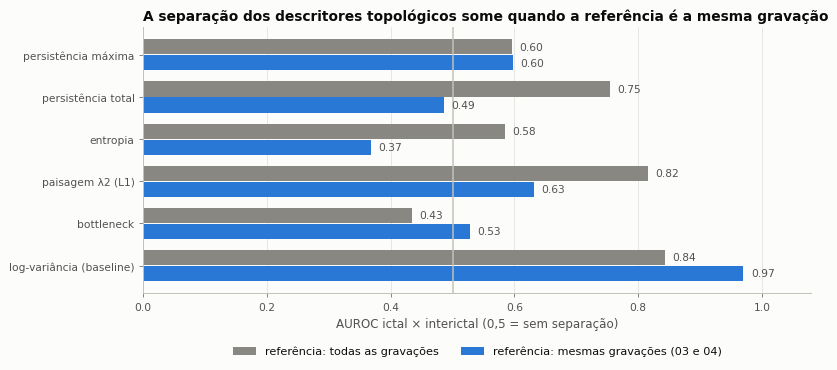

In [32]:
sel = ["h1_pers_max", "h1_pers_total", "h1_entropia", "h1_pais2_l1", "bottleneck", "log_variancia"]
rot = ["persistência máxima", "persistência total", "entropia", "paisagem λ2 (L1)", "bottleneck",
       "log-variância (baseline)"]
t_ = tab.set_index("descritor").loc[sel]
y = np.arange(len(sel))[::-1]
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.axvline(0.5, color=EIXO, lw=1.2)
ax.barh(y + 0.19, t_.auc_ictal_vs_inter, height=0.36, color=MUDO, label="referência: todas as gravações")
ax.barh(y - 0.19, t_.auc_ictal_vs_inter_mesma_grav, height=0.36, color=AZUL,
        label="referência: mesmas gravações (03 e 04)")
for yi, (a, b) in zip(y, zip(t_.auc_ictal_vs_inter, t_.auc_ictal_vs_inter_mesma_grav)):
    ax.text(a + 0.012, yi + 0.19, f"{a:.2f}", va="center", fontsize=8.5, color=TINTA_2)
    ax.text(b + 0.012, yi - 0.19, f"{b:.2f}", va="center", fontsize=8.5, color=TINTA_2)
ax.set_yticks(y, rot)
ax.set_xlim(0, 1.08)
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUROC ictal × interictal (0,5 = sem separação)")
ax.set_title("A separação dos descritores topológicos some quando a referência é a mesma gravação")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=2)
plt.show()

**O que observar.** A persistência total cai de 0,75 para 0,49, a entropia de 0,58 para 0,37 e a paisagem $\lambda_2$ de 0,82 para 0,63. A persistência máxima fica igual (0,60) e a log-variância **sobe** (0,84 para 0,97).

O que aconteceu: esses descritores não separam "crise" de "não crise". Separam **as horas das gravações 03 e 04 das outras horas**. Como as duas crises estão nessas gravações, qualquer coisa que distinga essas horas parece distinguir a crise. É uma variável de confusão clássica: a referência "todas as gravações" mistura o efeito da crise com o efeito do período do dia.

A linha do tempo completa mostra o fenômeno diretamente.

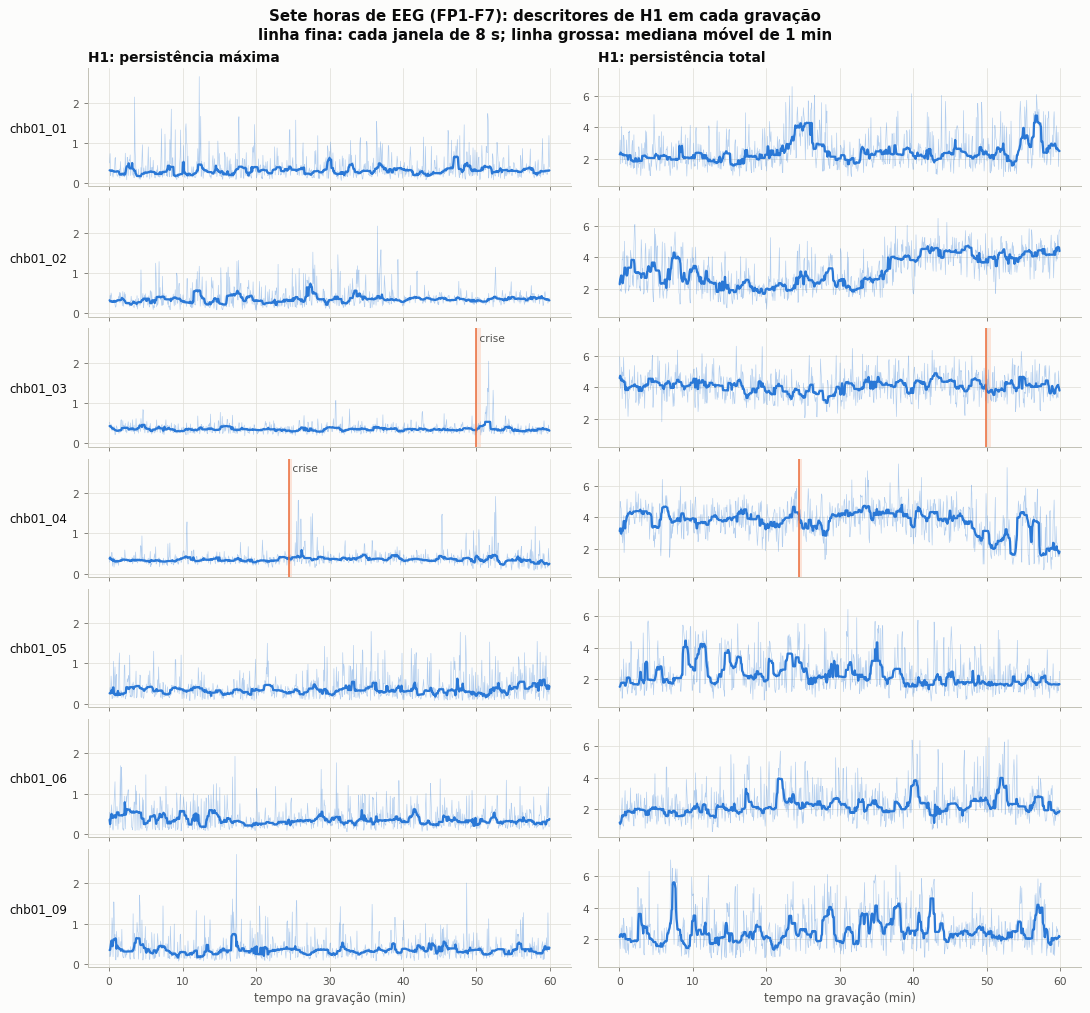

In [33]:
def fig_linha_do_tempo(cols=("h1_pers_max", "h1_pers_total")):
    fig, eixos = plt.subplots(len(gravs), 2, figsize=(12, 1.45 * len(gravs) + 1), sharex=True,
                              sharey="col", constrained_layout=True)
    for i, g in enumerate(gravs):
        sub = df[df.gravacao == g.nome]
        t = (sub.t_ini + JANELA_S / 2) / 60
        for j, c in enumerate(cols):
            ax = eixos[i, j]
            ax.plot(t, sub[c], color=AZUL, lw=0.5, alpha=0.35)
            ax.plot(t, sub[c].rolling(15, center=True, min_periods=5).median(), color=AZUL, lw=1.8)
            for ini, fim in g.crises:
                faixa_crise(ax, ini / 60, fim / 60)
                ax.axvline(ini / 60, color=LARANJA, lw=1.2)
                if j == 0:
                    ax.text(ini / 60, 0.96, " crise", transform=ax.get_xaxis_transform(),
                            ha="left", va="top", fontsize=8.5, color=TINTA_2)
            if j == 0:
                ax.set_ylabel(g.nome, rotation=0, ha="right", va="center", color=TINTA)
            if i == 0:
                ax.set_title(f"H1: {DESCR[c]}")
    for ax in eixos[-1]:
        ax.set_xlabel("tempo na gravação (min)")
    fig.suptitle(f"Sete horas de EEG ({CANAL}): descritores de H1 em cada gravação\n"
                 "linha fina: cada janela de 8 s; linha grossa: mediana móvel de 1 min", fontsize=12)
    plt.show()


fig_linha_do_tempo()

**O que observar.** Na coluna da direita (persistência total), o nível sobe por volta do minuto 35 de `chb01_02`, fica alto durante toda a gravação 03 e volta ao nível anterior perto do minuto 48 de `chb01_04`. É **um estado lento, de cerca de duas horas, que contém as duas crises**. As crises (linhas laranja) acontecem dentro dele, mas o descritor não faz nada de especial no instante em que elas começam.

Não temos como dizer o que é esse estado. Uma mudança de sono para vigília, ou o contrário, é uma hipótese plausível, mas o banco não traz hipnograma. O que dá para afirmar é que os descritores "de massa" de $H_1$ (persistência total, entropia, paisagens) acompanham esse estado, e não a crise. Lembre da Seção 1.3: são os descritores que respondem à quantidade de ciclos pequenos, isto é, à irregularidade do sinal.

**Lição de método.** Com poucos eventos, sempre compare com uma referência local (a mesma gravação, o mesmo dia, o mesmo paciente). Uma AUROC alta contra uma referência distante pode ser só um efeito de lote.

### 5.5 O trecho ictal é incomum? Teste por blocos

As janelas vizinhas se sobrepõem em 50 % e o EEG é autocorrelacionado: as 18 janelas ictais não são 18 observações independentes, são dois eventos. Um teste que trate janelas como independentes daria valores-p pequenos demais.

A alternativa usada no projeto: para cada crise, calcular a **média do descritor nas $k$ janelas ictais** e compará-la com a média em **todos os blocos de $k$ janelas interictais consecutivas**. O percentil diz onde o trecho ictal cai entre trechos interictais de mesma duração; o valor-p empírico é bilateral.

In [34]:
def blocos_interictais(df, col, k):
    """Média do descritor em todos os blocos de k janelas interictais consecutivas."""
    medias = []
    for _, sub in df.groupby("gravacao", sort=False):
        v = sub[col].to_numpy(float)
        ok = (sub.classe == "interictal").to_numpy() & np.isfinite(v)
        soma = np.convolve(np.where(ok, v, 0.0), np.ones(k), "valid")      # soma móvel de k janelas
        cont = np.convolve(ok.astype(float), np.ones(k), "valid")           # quantas das k são interictais
        medias.append(soma[cont == k] / k)                                  # só blocos inteiramente interictais
    return np.concatenate(medias)


def teste_blocos(df, colunas):
    linhas = []
    for grav, sub in df[df.classe == "ictal"].groupby("gravacao"):
        k = len(sub)
        for c in colunas:
            nulo = blocos_interictais(df, c, k)
            t = float(np.nanmean(sub[c]))
            m = np.median(nulo)
            p = (1 + np.sum(np.abs(nulo - m) >= abs(t - m))) / (1 + len(nulo))
            linhas.append({"crise": grav, "n_janelas_ictais": k, "descritor": c, "media_ictal": t,
                           "mediana_blocos_interictais": m, "percentil": float(np.mean(nulo <= t) * 100),
                           "p_empirico": float(p), "n_blocos": len(nulo)})
    return pd.DataFrame(linhas)


blocos = teste_blocos(df, PRINCIPAIS + ["h1_pais2_l1", "log_variancia"])
display(blocos.round(4))

,crise,n_janelas_ictais,descritor,media_ictal,mediana_blocos_interictais,percentil,p_empirico,n_blocos
0,chb01_03,11,h1_pers_max,0.3880,0.3725,58.0057,0.8231,5596
1,chb01_03,11,h1_pers_total,3.9128,2.6564,81.7370,0.1830,5596
2,chb01_03,11,h1_entropia,3.3151,3.1705,70.4789,0.5626,5596
3,chb01_03,11,bottleneck,0.1777,0.2128,28.8730,0.6178,5590
4,chb01_03,11,h1_pais2_l1,0.0421,0.0178,96.2116,0.0381,5596
5,chb01_03,11,log_variancia,9.0985,7.8396,98.6419,0.1912,5596
6,chb01_04,7,h1_pers_max,0.3827,0.3684,56.4321,0.8655,5628
7,chb01_04,7,h1_pers_total,3.8203,2.6599,78.4826,0.2244,5628
8,chb01_04,7,h1_entropia,3.2590,3.1824,60.7498,0.7822,5628
9,chb01_04,7,bottleneck,0.1739,0.2055,31.4123,0.6856,5622


**O que observar.**

- **Persistência máxima:** a média no trecho ictal cai perto dos percentis 58 e 56. Um trecho interictal sorteado ao acaso é igualmente "extremo" (p ≈ 0,8).
- **Paisagem $\lambda_2$:** o descritor topológico mais sensível, percentis 96 e 91 (p ≈ 0,04 e 0,09). Antes de comemorar: foram testados 16 descritores topológicos sem correção para comparações múltiplas, e a referência aqui são todas as gravações, sujeita ao efeito da Seção 5.4.
- **Log-variância:** percentis 99 e 96. O valor-p bilateral não é pequeno (≈ 0,2) porque a variância interictal tem cauda longa: artefatos de movimento também produzem blocos de variância muito alta.

### 5.6 Paisagens médias e bottleneck nas transições

Dois complementos. Primeiro, as paisagens médias por classe: a curva cinza é a média das janelas interictais **só das gravações com crise**, a referência local.

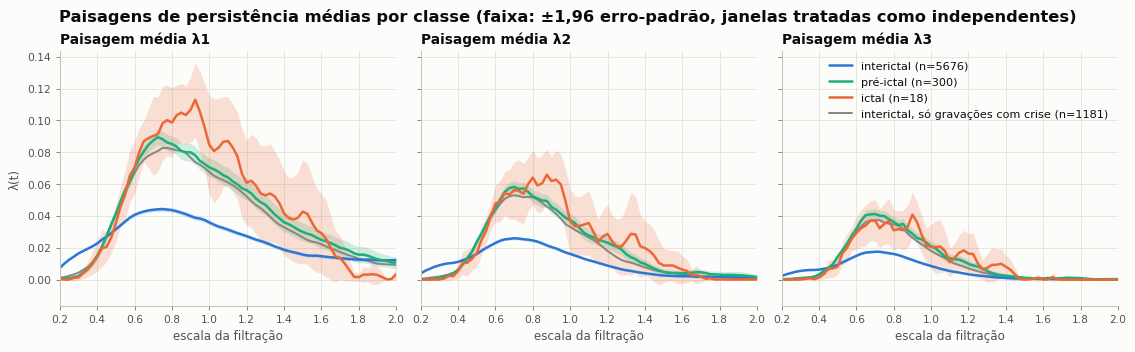

In [35]:
lam_todas = np.stack([paisagens(d) for d in diagramas])            # (janela, k, grade)
com_crise = df.gravacao.isin(df.loc[df.classe == "ictal", "gravacao"].unique())
fig, eixos = plt.subplots(1, PAISAGEM_K, figsize=(12.5, 3.8), sharey=True, constrained_layout=True)
for j, ax in enumerate(eixos):
    for classe in CLASSES:
        m = (df.classe == classe).to_numpy()
        media = lam_todas[m, j].mean(0)
        ep = lam_todas[m, j].std(0, ddof=1) / np.sqrt(m.sum())
        ax.fill_between(t_grade, media - 1.96 * ep, media + 1.96 * ep, color=COR_CLASSE[classe], alpha=0.2, lw=0)
        ax.plot(t_grade, media, color=COR_CLASSE[classe], lw=2, label=f"{ROTULO_CLASSE[classe]} (n={m.sum()})")
    m = ((df.classe == "interictal") & com_crise).to_numpy()
    ax.plot(t_grade, lam_todas[m, j].mean(0), color=MUDO, lw=1.6, zorder=1,
            label=f"interictal, só gravações com crise (n={m.sum()})")
    ax.set_title(f"Paisagem média λ{j + 1}")
    ax.set_xlabel("escala da filtração")
    ax.set_xlim(0.2, 2.0)
eixos[0].set_ylabel("λ(t)")
eixos[-1].legend(loc="upper right")
fig.suptitle("Paisagens de persistência médias por classe (faixa: ±1,96 erro-padrão, "
             "janelas tratadas como independentes)")
plt.show()

**O que observar.** As curvas ictal e pré-ictal ficam acima da interictal azul (todas as gravações), mas praticamente em cima da curva cinza (interictal das mesmas gravações). É o efeito de gravação de novo, agora visto na paisagem inteira e não em um número. A faixa de erro é otimista, porque trata janelas sobrepostas como independentes.

Segundo, o bottleneck. Se a crise fosse uma mudança brusca de regime topológico, $d_B(D_t, D_{t-1})$ deveria dar um salto no início e no fim dela. A tabela mostra o maior $d_B$ perto de cada transição e em que percentil ele fica entre as janelas interictais.

In [36]:
ref_db = df.loc[df.classe == "interictal", "bottleneck"].dropna().to_numpy()
linhas = []
for g in gravs:
    sub = df[df.gravacao == g.nome]
    centro = sub.t_ini + JANELA_S / 2
    for ini, fim in g.crises:
        for nome, t in (("início", ini), ("fim", fim)):
            v = sub.loc[(centro - t).abs() <= JANELA_S, "bottleneck"].max()
            linhas.append({"gravação": g.nome, "evento": nome, "t (s)": t, "maior d_B": float(v),
                           "percentil entre interictais": float(np.mean(ref_db <= v) * 100)})
display(pd.DataFrame(linhas).round(3))

,gravação,evento,t (s),maior d_B,percentil entre interictais
0,chb01_03,início,2996.0,0.146,32.046
1,chb01_03,fim,3036.0,0.271,74.480
2,chb01_04,início,1467.0,0.176,47.143
3,chb01_04,fim,1494.0,0.210,60.282


**O que observar.** No início das crises, o maior salto fica nos percentis 32 e 47: abaixo da mediana interictal. No fim, 74 e 60. O bottleneck não marca as transições.

### 5.7 De onde vêm os picos de persistência máxima?

Na Seção 5.1 havia picos isolados de persistência máxima, alguns bem altos. Se eles indicassem ritmo, seriam laços grandes nascendo em escala pequena, como na senoide. A célula abaixo olha para as janelas com persistência máxima acima do percentil 95 interictal e pergunta **em que escala nasce o ciclo mais persistente**.

Janelas com persistência máxima acima do percentil 95 interictal (0.92): 297
  nascimento do ciclo principal, mediana: 3.17 (nas demais janelas: 0.94)
  fração que nasce em escala maior que 2: 93 %


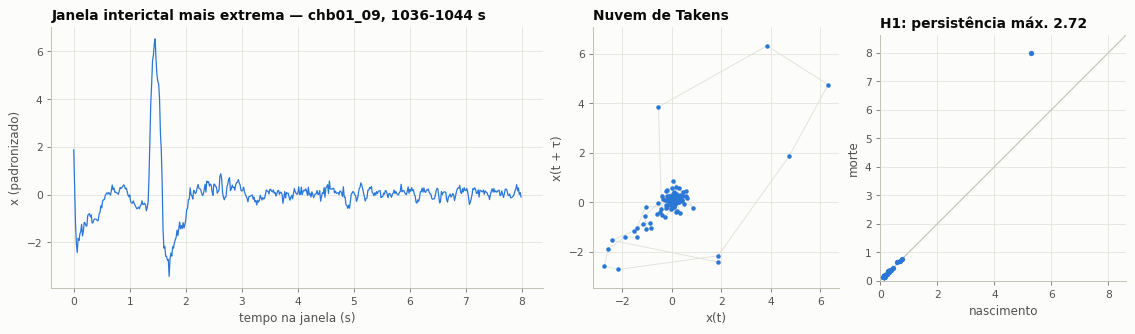

In [37]:
p95 = df.loc[df.classe == "interictal", "h1_pers_max"].quantile(0.95)
altas = df.h1_pers_max > p95
print(f"Janelas com persistência máxima acima do percentil 95 interictal ({p95:.2f}): {altas.sum()}")
print(f"  nascimento do ciclo principal, mediana: {df.loc[altas, 'h1_nasc_max'].median():.2f} "
      f"(nas demais janelas: {df.loc[~altas, 'h1_nasc_max'].median():.2f})")
print(f"  fração que nasce em escala maior que 2: {100 * (df.loc[altas, 'h1_nasc_max'] > 2).mean():.0f} %")

i = df.loc[df.classe == "interictal", "h1_pers_max"].idxmax()       # a janela interictal mais extrema
g = gravs_por_nome[df.loc[i, "gravacao"]]
x, fs = carregar_canal(g.caminho)
w = int(JANELA_S * fs)
t0s = df.loc[i, "t_ini"]
seg = x[int(t0s * fs): int(t0s * fs) + w]
X = imersao_takens(seg, DIM, ATRASO, PASSO_NUVEM)
fig, (a, b, c) = plt.subplots(1, 3, figsize=(12.5, 3.6), constrained_layout=True,
                              gridspec_kw={"width_ratios": [2, 1, 1]})
a.plot(np.arange(w) / fs, padronizar(seg), color=AZUL, lw=1)
a.set_title(f"Janela interictal mais extrema — {g.nome}, {t0s:.0f}-{t0s + JANELA_S:.0f} s")
a.set_xlabel("tempo na janela (s)")
a.set_ylabel("x (padronizado)")
b.plot(X[:, 0], X[:, 1], color=GRADE, lw=0.7, zorder=1)
b.scatter(X[:, 0], X[:, 1], s=13, color=AZUL, linewidths=0, zorder=2)
b.set_aspect("equal", adjustable="datalim")
b.set_title("Nuvem de Takens")
b.set_xlabel("x(t)")
b.set_ylabel("x(t + τ)")
desenhar_diagrama(c, diagramas[i], cor=AZUL)
c.set_title(f"H1: persistência máx. {df.loc[i, 'h1_pers_max']:.2f}")
plt.show()

**O que observar.** Nas janelas de persistência máxima alta, o ciclo principal nasce em escala muito maior que nas demais (mediana acima de 3, contra menos de 1), quase sempre acima de 2. Um laço de ritmo nasceria cedo, quando pontos vizinhos da trajetória se ligam. Um ciclo que só nasce em escala grande é formado por **poucos pontos afastados do grosso da nuvem**: a janela tem um transiente de grande amplitude (uma piscada, um movimento) que, depois da padronização, vira um punhado de pontos distantes. Esses pontos e o novelo central formam um "anel" espúrio.

O exemplo acima mostra exatamente isso: o sinal é quase plano, com um evento isolado, e a nuvem é um novelo denso com uma alça de poucos pontos.

**Conclusão da seção.** A persistência máxima do Rips é sensível a pontos atípicos, e no EEG sem remoção de artefatos os pontos atípicos são mais comuns que os ritmos limpos. Somando com a Seção 5.4: os descritores de $H_1$ respondem a artefatos (persistência máxima) e a um estado lento de horas (persistência total, entropia, paisagens), mas não à crise.

## 6. Detecção de crises com aprendizado de máquina

Um descritor sozinho pode separar mal e uma combinação de 15 separar bem. Para testar isso, treinamos um classificador **ictal × não ictal** com os descritores de cada janela.

**Desenho do experimento.**

- **Positivas:** as 18 janelas ictais. **Negativas:** interictais e pré-ictais. Janelas de transição e pós-ictais ficam fora do treino e das métricas.
- **Validação deixa-uma-gravação-fora.** Janelas vizinhas são quase cópias uma da outra; se fossem sorteadas ao acaso entre treino e teste, o modelo veria no treino a vizinha de cada janela de teste e o resultado seria inflado. Por isso todas as janelas de uma gravação ficam juntas: o modelo é treinado em seis gravações e pontua a sétima, e isso se repete para cada gravação. Para detectar a crise de `chb01_03`, o modelo só conhece a crise de `chb01_04`, e vice-versa.
- **Hiperparâmetros fixos**, sem busca. Nada é ajustado olhando o conjunto de teste.
- **Limite do desenho:** o enunciado recomenda separar treino e teste por paciente. Com um só paciente, a separação por gravação mede generalização para outras horas do mesmo paciente, não para pacientes novos.

**Conjuntos de descritores comparados.**

| Conjunto | Nº | O que enxerga |
|---|---|---|
| Topológico $H_1$, $(d,\tau)$ do enunciado | 15 | só a forma, via topologia |
| Topológico $H_1$, $(d,\tau)$ dos dados | 15 | idem, com os parâmetros da Seção 3 |
| Clássico: só forma | 9 | só a forma, via espectro e Hjorth |
| Clássico: forma + amplitude | 12 | forma e amplitude |
| Topológico + clássico | 27 | tudo |

In [38]:
def modelos():
    m = {"Regressão logística": make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))}
    if RODAR_FLORESTA:
        m["Floresta aleatória"] = RandomForestClassifier(
            n_estimators=500, min_samples_leaf=5, class_weight="balanced_subsample",
            random_state=SEMENTE, n_jobs=-1)
    return m


def pontuar_fora_da_amostra(df, colunas, y, validas, modelo):
    """Escore de cada janela vindo de um modelo que NÃO viu a gravação dela.

    Treina só com as janelas `validas`; pontua todas as janelas da gravação retida.
    """
    X = df[colunas].to_numpy(float)
    grav = df.gravacao.to_numpy()
    escores = np.full(len(df), np.nan)
    for g in np.unique(grav):
        teste = grav == g
        treino = ~teste & validas
        if y[treino].sum() == 0:
            continue
        m = clone(modelo).fit(X[treino], y[treino])
        escores[teste] = m.predict_proba(X[teste])[:, 1]
    return escores


def sequencias(mask):
    """Número de sequências de valores True consecutivos (cada sequência conta como um alarme)."""
    mask = np.asarray(mask, dtype=bool)
    return int(mask[0]) + int(np.sum(mask[1:] & ~mask[:-1])) if len(mask) else 0


def metricas_evento(df, escores, y, validas):
    """Alarmes falsos por hora no limiar que detecta 1 crise ou as 2 crises."""
    neg = validas & (y == 0)
    horas = neg.sum() * PASSO_S / 3600
    # maior escore dentro de cada crise: o limiar mais alto que ainda a detecta
    picos = [escores[(df.gravacao == g).to_numpy() & (y == 1)].max() for g in df.loc[y == 1, "gravacao"].unique()]

    def falsos(limiar):
        return sum(sequencias((escores >= limiar)[m] & neg[m])
                   for m in [(df.gravacao == g).to_numpy() for g in df.gravacao.unique()])

    return {"fa_h_1_crise": falsos(max(picos)) / horas, "fa_h_2_crises": falsos(min(picos)) / horas}

In [39]:
# junta os descritores topológicos da configuração alternativa (sufixo _alt)
alt = df_alt[["gravacao", "t_ini"] + COLUNAS_TOPO].rename(columns={c: c + "_alt" for c in COLUNAS_TOPO})
dfm = df.merge(alt, on=["gravacao", "t_ini"], how="left", validate="one_to_one")

NOME_TOPO = f"Topológico H1 (d={DIM}, τ={ATRASO})"
NOME_TOPO_ALT = f"Topológico H1 (d={DIM_DADOS}, τ={ATRASO_DADOS})"
CONJUNTOS = {
    NOME_TOPO: COLUNAS_TOPO,
    NOME_TOPO_ALT: [c + "_alt" for c in COLUNAS_TOPO],
    "Clássico: só forma": COLUNAS_FORMA,
    "Clássico: forma + amplitude": COLUNAS_BASE,
    "Topológico + clássico": COLUNAS_TOPO + COLUNAS_BASE,
}

validas = dfm.classe.isin(["ictal", "interictal", "pre-ictal"]).to_numpy()
y = (dfm.classe == "ictal").to_numpy().astype(int)
com_crise_nomes = [g.nome for g in gravs if g.crises]

linhas, escores_det = [], {}
for nome_m, modelo in modelos().items():
    for nome_c, cols in CONJUNTOS.items():
        s = pontuar_fora_da_amostra(dfm, cols, y, validas, modelo)
        escores_det[(nome_m, nome_c)] = s
        r_ = {"modelo": nome_m, "descritores": nome_c, "n_descritores": len(cols),
              "auroc": roc_auc_score(y[validas], s[validas]),
              "auprc": average_precision_score(y[validas], s[validas])}
        for g in com_crise_nomes:
            m = validas & (dfm.gravacao == g).to_numpy()
            r_[f"auroc_{g}"] = roc_auc_score(y[m], s[m])
        r_.update(metricas_evento(dfm, s, y, validas))
        linhas.append(r_)
tab_det = pd.DataFrame(linhas)
print(f"Janelas: {validas.sum()} ({y[validas].sum()} ictais, prevalência {y[validas].mean():.4f})")
display(tab_det.round(3))

Janelas: 5994 (18 ictais, prevalência 0.0030)


,modelo,descritores,n_descritores,auroc,auprc,auroc_chb01_03,auroc_chb01_04,fa_h_1_crise,fa_h_2_crises
0,Regressão logística,"Topológico H1 (d=3, τ=4)",15,0.789,0.012,0.584,0.768,4.367,16.717
1,Regressão logística,"Topológico H1 (d=4, τ=7)",15,0.678,0.007,0.467,0.647,9.187,15.211
2,Regressão logística,Clássico: só forma,9,0.877,0.078,0.709,0.927,0.000,3.614
3,Regressão logística,Clássico: forma + amplitude,12,0.988,0.378,0.952,0.998,0.151,0.151
4,Regressão logística,Topológico + clássico,27,0.978,0.412,0.917,0.998,0.000,0.151


**Como ler a tabela.**

- `auroc`: separação janela a janela, juntando os escores das sete gravações retidas.
- `auroc_chb01_03` e `auroc_chb01_04`: a mesma conta **dentro** de cada gravação com crise. É a referência local da Seção 5.4, e é a coluna mais honesta.
- `auprc`: área sob a curva precisão × revocação. Com prevalência de 0,3 %, um classificador ao acaso tem AUPRC ≈ 0,003.
- `fa_h_2_crises`: quantos **alarmes falsos por hora** o detector dispara quando o limiar é baixado até pegar as duas crises. É a métrica que importa na prática.

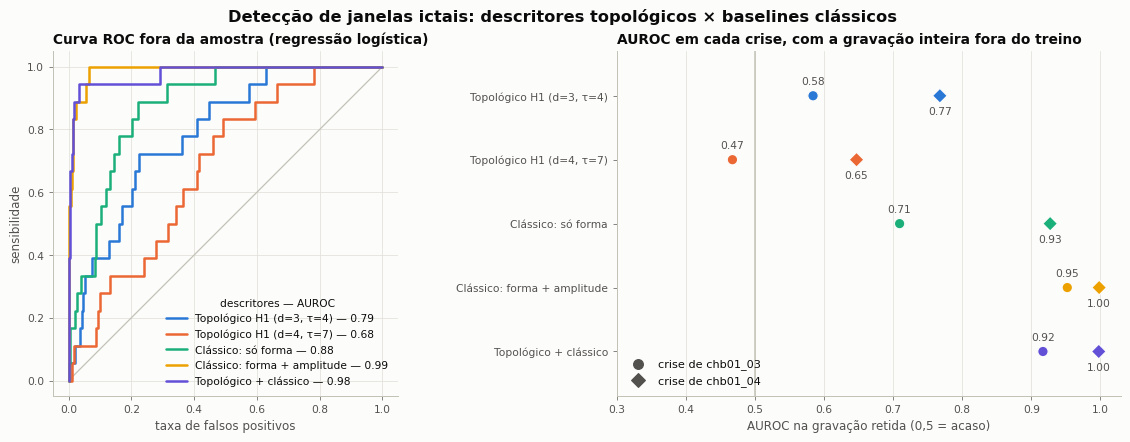

In [40]:
mod = "Regressão logística"
nomes = list(CONJUNTOS)
CORES = [AZUL, LARANJA, AGUA, AMARELO, VIOLETA]

fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True,
                           gridspec_kw={"width_ratios": [1, 1.15]})
a.plot([0, 1], [0, 1], color=EIXO, lw=1)
for nome, cor in zip(nomes, CORES):
    s = escores_det[(mod, nome)]
    fpr, tpr, _ = roc_curve(y[validas], s[validas])
    v = tab_det[(tab_det.modelo == mod) & (tab_det.descritores == nome)].auroc.item()
    a.plot(fpr, tpr, color=cor, lw=2, label=f"{nome} — {v:.2f}")
a.set_xlabel("taxa de falsos positivos")
a.set_ylabel("sensibilidade")
a.set_aspect("equal")
a.set_title(f"Curva ROC fora da amostra ({mod.lower()})")
a.legend(loc="lower right", title="descritores — AUROC", title_fontsize=8.5, fontsize=8.5)

yy = np.arange(len(nomes))[::-1]
b.axvline(0.5, color=EIXO, lw=1.2)
for g, marc in zip(com_crise_nomes, ["o", "D"]):
    v = [tab_det[(tab_det.modelo == mod) & (tab_det.descritores == n)][f"auroc_{g}"].item() for n in nomes]
    b.scatter(v, yy, s=70, marker=marc, c=CORES[: len(nomes)], zorder=3, edgecolor=SUPERFICIE, linewidths=1)
    b.scatter([], [], s=60, marker=marc, color=TINTA_2, label=f"crise de {g}")
    for vi, yi in zip(v, yy):
        b.annotate(f"{vi:.2f}", (vi, yi), textcoords="offset points",
                   xytext=(0, 9 if marc == "o" else -15), ha="center", fontsize=8.5, color=TINTA_2)
b.set_yticks(yy, nomes)
b.set_ylim(-0.7, len(nomes) - 0.3)
b.set_xlim(0.3, 1.03)
b.grid(axis="y", visible=False)
b.set_xlabel("AUROC na gravação retida (0,5 = acaso)")
b.set_title("AUROC em cada crise, com a gravação inteira fora do treino")
b.legend(loc="lower left")
fig.suptitle("Detecção de janelas ictais: descritores topológicos × baselines clássicos")
plt.show()

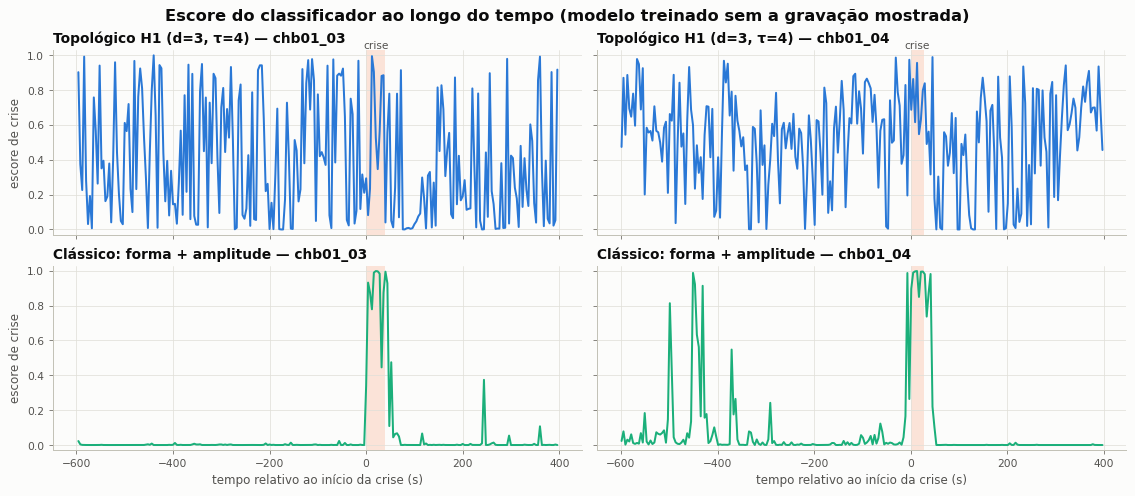

In [41]:
pares = [(NOME_TOPO, AZUL), ("Clássico: forma + amplitude", AGUA)]
gravs_crise = [g for g in gravs if g.crises]
fig, eixos = plt.subplots(2, len(gravs_crise), figsize=(12.5, 5.4), sharex=True, sharey=True,
                          constrained_layout=True)
for j, g in enumerate(gravs_crise):
    ini, fim = g.crises[0]
    m = (dfm.gravacao == g.nome).to_numpy()
    t = (dfm.t_ini[m] + JANELA_S / 2 - ini).to_numpy()
    perto = (t > -600) & (t < 400)
    for i, (nome, cor) in enumerate(pares):
        ax = eixos[i, j]
        faixa_crise(ax, 0, fim - ini, "crise" if i == 0 else None)
        ax.plot(t[perto], escores_det[(mod, nome)][m][perto], color=cor, lw=1.6)
        ax.set_title(f"{nome} — {g.nome}")
        ax.set_ylim(-0.03, 1.03)
for ax in eixos[:, 0]:
    ax.set_ylabel("escore de crise")
for ax in eixos[-1]:
    ax.set_xlabel("tempo relativo ao início da crise (s)")
fig.suptitle("Escore do classificador ao longo do tempo (modelo treinado sem a gravação mostrada)")
plt.show()

**O que observar.**

- **O baseline clássico com amplitude detecta as duas crises quase sem erro:** AUROC 0,99 e 0,15 alarme falso por hora (um alarme falso em quase sete horas). Na figura dos escores, a curva verde fica perto de zero e sobe dentro da faixa da crise (na gravação 04 há também alguns picos isolados minutos antes).
- **Os descritores topológicos ficam em 0,79**, e dentro de cada gravação com crise em 0,58 e 0,77. Para pegar as duas crises o detector topológico dispara cerca de 17 alarmes falsos por hora, mais de cem vezes a taxa do baseline. A curva azul sobe e desce o tempo todo, sem relação visível com a crise.
- **Comparação justa:** mesmo o baseline que ignora a amplitude ("só forma", 0,88 e 3,6 alarmes falsos por hora) supera a topologia. A desvantagem não vem só de ter descartado a amplitude.
- **Combinar não ajuda:** topológico + clássico (0,98) não melhora o clássico sozinho (0,99).
- **Os parâmetros "dos dados" não salvam o método:** com $d=4$, $\tau=7$ o resultado é pior (0,68).

**Experimente.** Ligue `RODAR_FLORESTA` na Seção 0.2 para repetir com um modelo não linear. No projeto original a floresta aleatória não muda a conclusão.

## 7. Previsão (exploratório)

Detectar uma crise em andamento é uma coisa; **antecipá-la** seria muito mais valioso. A pergunta agora é se os 10 minutos anteriores à crise (classe pré-ictal) têm uma assinatura em $H_1$.

Em previsão de crises é fácil se enganar, então as definições foram fixadas antes de olhar os resultados:

| Elemento | Definição |
|---|---|
| Horizonte pré-ictal | os 600 s antes do início anotado da crise |
| Tempo mínimo de intervenção | 0 s |
| Exclusões | janelas ictais, de transição e os 600 s pós-ictais |
| Escore | classificador pré-ictal × interictal, deixa-uma-gravação-fora, suavizado por média móvel **causal** de 60 s (só usa o passado) |
| Alarme | escore suavizado ≥ limiar; depois de um alarme, 600 s de período refratário sem novos alarmes |
| Acerto | alarme disparado dentro do horizonte pré-ictal |
| Alarme falso | alarme disparado em janela interictal; taxa = falsos por hora interictal |
| Referência de acaso | um preditor que dispara ao acaso com a mesma taxa acerta uma crise com probabilidade $1 - e^{-\text{taxa}\times 600\,\text{s}}$ |

Com duas crises, a sensibilidade só pode valer 0, 50 ou 100 %. Esta seção é uma exploração, não uma avaliação.

In [42]:
SOP = HORIZONTE_PRE_S       # horizonte pré-ictal
REFRATARIO = 600.0
SUAVIZACAO = 15             # 15 janelas x 4 s = 60 s
CONJUNTOS_PREV = {
    "Topológico H1": COLUNAS_TOPO,
    "Clássico: forma + amplitude": COLUNAS_BASE,
    "Topológico + clássico": COLUNAS_TOPO + COLUNAS_BASE,
}
CORES_PREV = {"Topológico H1": AZUL, "Clássico: forma + amplitude": AGUA, "Topológico + clássico": VIOLETA}


def suavizar(df, escores, validas):
    """Média móvel causal dentro de cada gravação."""
    s = pd.Series(np.where(validas, escores, np.nan))
    return (s.groupby(df.gravacao.to_numpy(), sort=False)
             .transform(lambda v: v.rolling(SUAVIZACAO, min_periods=1).mean()).to_numpy())


def alarmes(df, suave, validas, limiar):
    """Índices das janelas em que um alarme dispara (com período refratário)."""
    t = (df.t_abs + JANELA_S).to_numpy()
    disparos, ultimo = [], -np.inf
    for i in np.flatnonzero(validas & (suave >= limiar)):
        if t[i] - ultimo >= REFRATARIO:
            disparos.append(i)
            ultimo = t[i]
    return np.array(disparos, dtype=int)


def curva_alarmes(df, suave, validas):
    """Para cada limiar: quantas crises são previstas e quantos alarmes falsos por hora."""
    classe = df.classe.to_numpy()
    crise = df.crise_proxima.to_numpy()
    horas = (classe == "interictal").sum() * PASSO_S / 3600
    linhas = []
    for limiar in np.unique(np.quantile(suave[validas], np.linspace(0, 1, 401))):
        idx = alarmes(df, suave, validas, limiar)
        pre = idx[classe[idx] == "pre-ictal"]
        linhas.append({"limiar": limiar, "crises_previstas": len(set(crise[pre])),
                       "alarmes_falsos": int((classe[idx] == "interictal").sum()),
                       "fa_h": (classe[idx] == "interictal").sum() / horas})
    return pd.DataFrame(linhas), horas


validas_p = df.classe.isin(["interictal", "pre-ictal"]).to_numpy()
y_p = (df.classe == "pre-ictal").to_numpy().astype(int)
n_crises = len(com_crise_nomes)
modelo_p = modelos()["Regressão logística"]

resumo, suaves, curvas_prev = [], {}, {}
for nome, cols in CONJUNTOS_PREV.items():
    s = pontuar_fora_da_amostra(df, cols, y_p, validas_p, modelo_p)
    suaves[nome] = suavizar(df, s, validas_p)
    c, horas = curva_alarmes(df, suaves[nome], validas_p)
    curvas_prev[nome] = c
    r_ = {"descritores": nome, "auroc_janelas": roc_auc_score(y_p[validas_p], s[validas_p])}
    for g in com_crise_nomes:
        m = validas_p & (df.gravacao == g).to_numpy()
        r_[f"auroc_dentro_{g}"] = roc_auc_score(y_p[m], s[m])
    for k in range(1, n_crises + 1):
        ok = c[c.crises_previstas >= k]
        fa = float(ok.fa_h.min()) if len(ok) else np.nan
        r_[f"fa_h_min_{k}_crise(s)"] = fa
        # preditor ao acaso com a mesma taxa: acerta cada crise com probabilidade p
        p = 1 - np.exp(-fa * SOP / 3600) if np.isfinite(fa) else np.nan
        r_[f"acaso_prob_{k}_crise(s)"] = 1 - (1 - p) ** n_crises if k == 1 else p ** k
    resumo.append(r_)
print(f"Horas interictais: {horas:.2f} | crises: {n_crises} | janelas pré-ictais: {y_p[validas_p].sum()}")
display(pd.DataFrame(resumo).set_index("descritores").round(3).T)

Horas interictais: 6.31 | crises: 2 | janelas pré-ictais: 300


descritores,Topológico H1,Clássico: forma + amplitude,Topológico + clássico
auroc_janelas,0.797,0.811,0.802
auroc_dentro_chb01_03,0.560,0.212,0.187
auroc_dentro_chb01_04,0.581,0.511,0.526
fa_h_min_1_crise(s),0.634,0.476,0.476
acaso_prob_1_crise(s),0.191,0.147,0.147
fa_h_min_2_crise(s),0.634,1.268,1.268
acaso_prob_2_crise(s),0.010,0.036,0.036


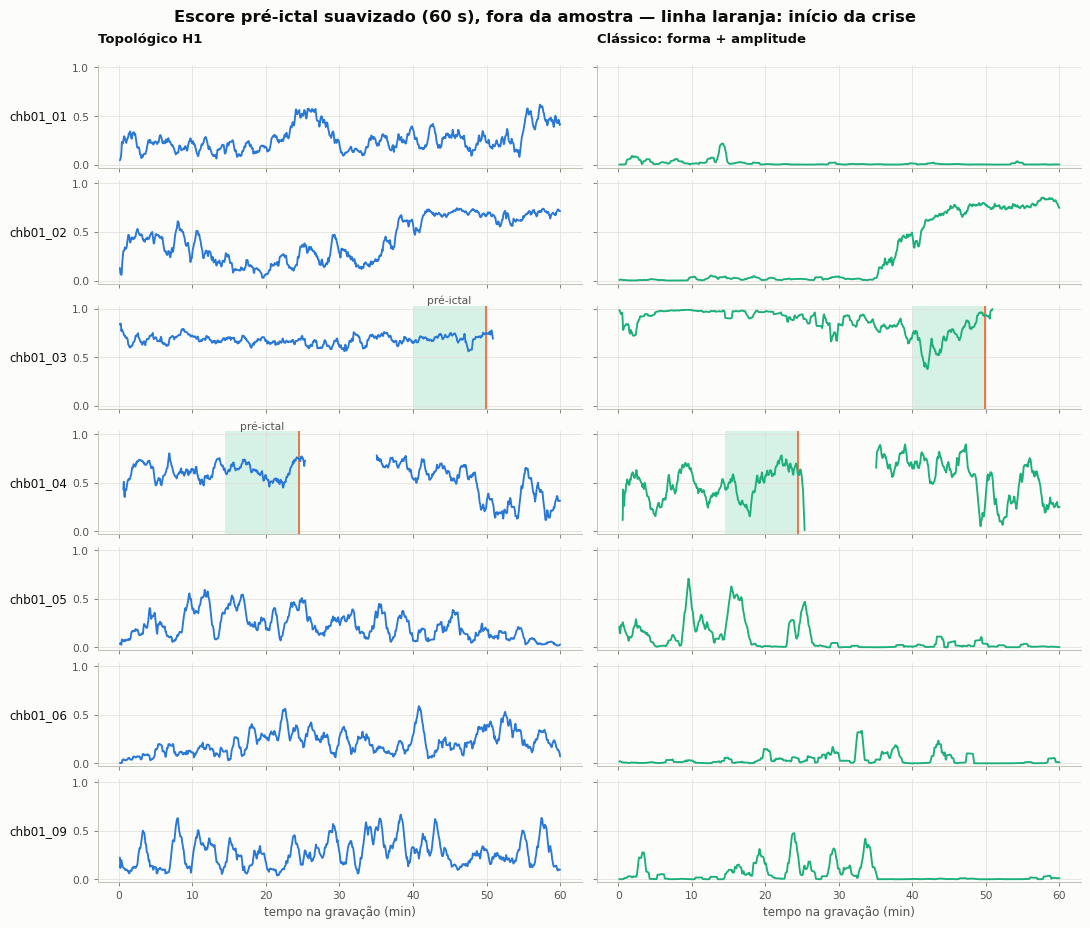

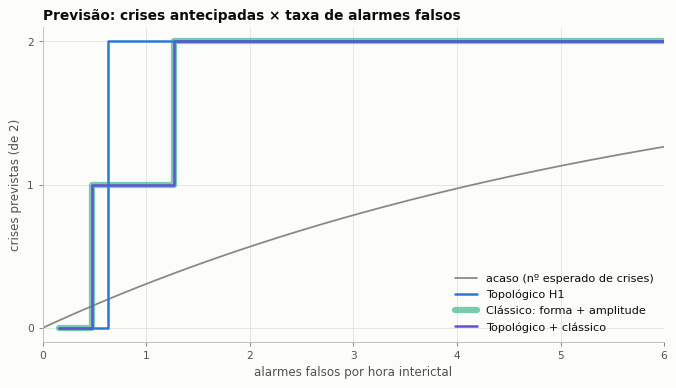

In [43]:
nomes_p = ["Topológico H1", "Clássico: forma + amplitude"]
fig, eixos = plt.subplots(len(gravs), 2, figsize=(12, 1.3 * len(gravs) + 1.1), sharex=True, sharey=True,
                          constrained_layout=True)
for i, g in enumerate(gravs):
    m = (df.gravacao == g.nome).to_numpy()
    t = ((df.t_ini[m] + JANELA_S) / 60).to_numpy()
    for j, nome in enumerate(nomes_p):
        ax = eixos[i, j]
        for ini, fim in g.crises:
            ax.axvspan((ini - SOP) / 60, ini / 60, color="#d6f1e6", lw=0, zorder=0)
            ax.axvline(ini / 60, color=LARANJA, lw=1.4)
            if j == 0:
                ax.text((ini - SOP / 2) / 60, 1.0, "pré-ictal", ha="center", va="bottom",
                        transform=ax.get_xaxis_transform(), fontsize=8.5, color=TINTA_2)
        ax.plot(t, suaves[nome][m], color=CORES_PREV[nome], lw=1.5)
        ax.set_ylim(-0.03, 1.03)
        if j == 0:
            ax.set_ylabel(g.nome, rotation=0, ha="right", va="center", color=TINTA)
        if i == 0:
            ax.set_title(f"{nome}\n", fontsize=10.5)
for ax in eixos[-1]:
    ax.set_xlabel("tempo na gravação (min)")
fig.suptitle("Escore pré-ictal suavizado (60 s), fora da amostra — linha laranja: início da crise")
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 4.2), constrained_layout=True)
fa = np.linspace(0, 6, 200)
ax.plot(fa, n_crises * (1 - np.exp(-fa * SOP / 3600)), color=MUDO, lw=1.4, label="acaso (nº esperado de crises)")
for nome, c in curvas_prev.items():
    c = c.sort_values(["fa_h", "crises_previstas"])
    melhor = c.groupby("fa_h", as_index=False).crises_previstas.max()
    melhor["crises_previstas"] = melhor.crises_previstas.cummax()
    # o clássico e o combinado quase coincidem: o primeiro vai mais grosso, por baixo
    ax.step(np.r_[melhor.fa_h, 6], np.r_[melhor.crises_previstas, melhor.crises_previstas.iloc[-1]],
            where="post", color=CORES_PREV[nome], label=nome,
            lw=5 if nome.startswith("Clássico") else 2, alpha=0.6 if nome.startswith("Clássico") else 1)
ax.set_xlim(0, 6)
ax.set_yticks(range(n_crises + 1))
ax.set_xlabel("alarmes falsos por hora interictal")
ax.set_ylabel(f"crises previstas (de {n_crises})")
ax.set_title("Previsão: crises antecipadas × taxa de alarmes falsos")
ax.legend(loc="lower right")
plt.show()

**O que observar.**

- **Janela a janela, a AUROC pré-ictal × interictal do conjunto topológico é 0,80.** Parece promissor.
- **Dentro de cada gravação com crise, ela cai para 0,56 e 0,58.** O escore não distingue os 10 minutos anteriores à crise do resto da mesma hora. É o efeito de gravação da Seção 5.4 de novo: o classificador aprendeu a reconhecer o estado lento de duas horas, e as janelas pré-ictais estão dentro dele.
- **Na figura dos escores**, a curva azul fica alta durante quase toda a gravação 03 e boa parte da 02 e da 04, não só nas faixas verdes.
- **"Duas crises previstas com 0,63 alarme falso por hora"** é o melhor ponto da curva topológica, e é otimista por dois motivos. O limiar foi escolhido varrendo os próprios dados de teste. E, como o escore fica alto durante todo o estado lento, o alarme dispara a cada 10 minutos ao longo dele (é o período refratário que dita o ritmo); as duas crises estão no mesmo estado e contam, na prática, como um único evento.

Não há evidência, nestes dados, de um sinal pré-ictal em $H_1$.

## 8. Mapper (exploratório)

Até aqui, cada janela foi resumida por 15 números e analisada com estatística convencional. O **Mapper** olha para o conjunto das janelas como uma nuvem de pontos em $\mathbb{R}^{15}$ e desenha um grafo que resume a forma dessa nuvem.

**O algoritmo em quatro passos.**

1. **Lente:** uma função que projeta cada ponto em poucos números (aqui, 1 ou 2).
2. **Cobertura:** o contradomínio da lente é coberto por intervalos (ou retângulos) que se sobrepõem.
3. **Agrupamento:** os pontos que caem em cada intervalo são agrupados no espaço original, com DBSCAN. Cada grupo vira um **nó**.
4. **Nervo:** dois nós são ligados por uma **aresta** quando compartilham pontos, o que só acontece nas sobreposições.

Se as janelas ictais formassem uma região própria no espaço dos descritores, elas apareceriam concentradas em alguns nós, de preferência em um ramo do grafo.

Dois grafos, como no projeto:

- **Mapper A:** lente = as duas primeiras componentes principais dos descritores topológicos; todas as janelas.
- **Mapper B:** lente = tempo relativo ao início da crise, como sugere o enunciado; só janelas a até 30 min de uma crise.

O raio do DBSCAN foi fixado de antemão por uma heurística (quantil 90 % da distância ao 5º vizinho). Nenhum teste estatístico é feito sobre os grafos.

In [44]:
MIN_AMOSTRAS = 5


def eps_heuristico(X, k=MIN_AMOSTRAS, quantil=0.90):
    """eps do DBSCAN = quantil 90 % da distância ao k-ésimo vizinho (fixado a priori)."""
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    return float(np.quantile(d[:, -1], quantil))


def construir_mapper(lente, X, n_cubos, sobreposicao, eps):
    mapper = km.KeplerMapper(verbose=0)
    grafo = mapper.map(lente, X, cover=km.Cover(n_cubes=n_cubos, perc_overlap=sobreposicao),
                       clusterer=DBSCAN(eps=eps, min_samples=MIN_AMOSTRAS))
    return mapper, grafo


def para_networkx(grafo):
    G = nx.Graph()
    for no, membros in grafo["nodes"].items():
        G.add_node(no, membros=np.array(membros))
    for a, vizinhos in grafo["links"].items():
        for b in vizinhos:
            G.add_edge(a, b)
    return G


def tabela_nos(G, df):
    linhas = []
    for no, dados_no in G.nodes(data=True):
        sub = df.iloc[dados_no["membros"]]
        linhas.append({
            "no": no, "n_janelas": len(sub),
            **{f"frac_{c}": float((sub.classe == c).mean())
               for c in ("interictal", "pre-ictal", "ictal", "pos-ictal")},
            "pers_max_media": sub.h1_pers_max.mean(),
            "gravacoes": ",".join(sorted(sub.gravacao.str[-2:].unique())),
        })
    return pd.DataFrame(linhas)


def desenhar_grafo(ax, G, pos, valores, titulo, rotulo_cor, vmin=0, vmax=None):
    tam = np.array([len(G.nodes[n]["membros"]) for n in G])
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=EIXO, width=0.7)
    sc = ax.scatter([pos[n][0] for n in G], [pos[n][1] for n in G], c=valores,
                    s=14 + 5.5 * np.sqrt(tam), cmap=SEQ, vmin=vmin, vmax=vmax,
                    edgecolor=TINTA_2, linewidths=0.4, zorder=3)
    ax.set_title(titulo)
    ax.grid(False)
    cb = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.01)
    cb.set_label(rotulo_cor)
    cb.outline.set_visible(False)

Mapper A: 6291 janelas, DBSCAN eps = 1.41; a lente explica 75 % da variância
  63 nós, 178 arestas, 4 componentes; 5916 janelas em algum nó


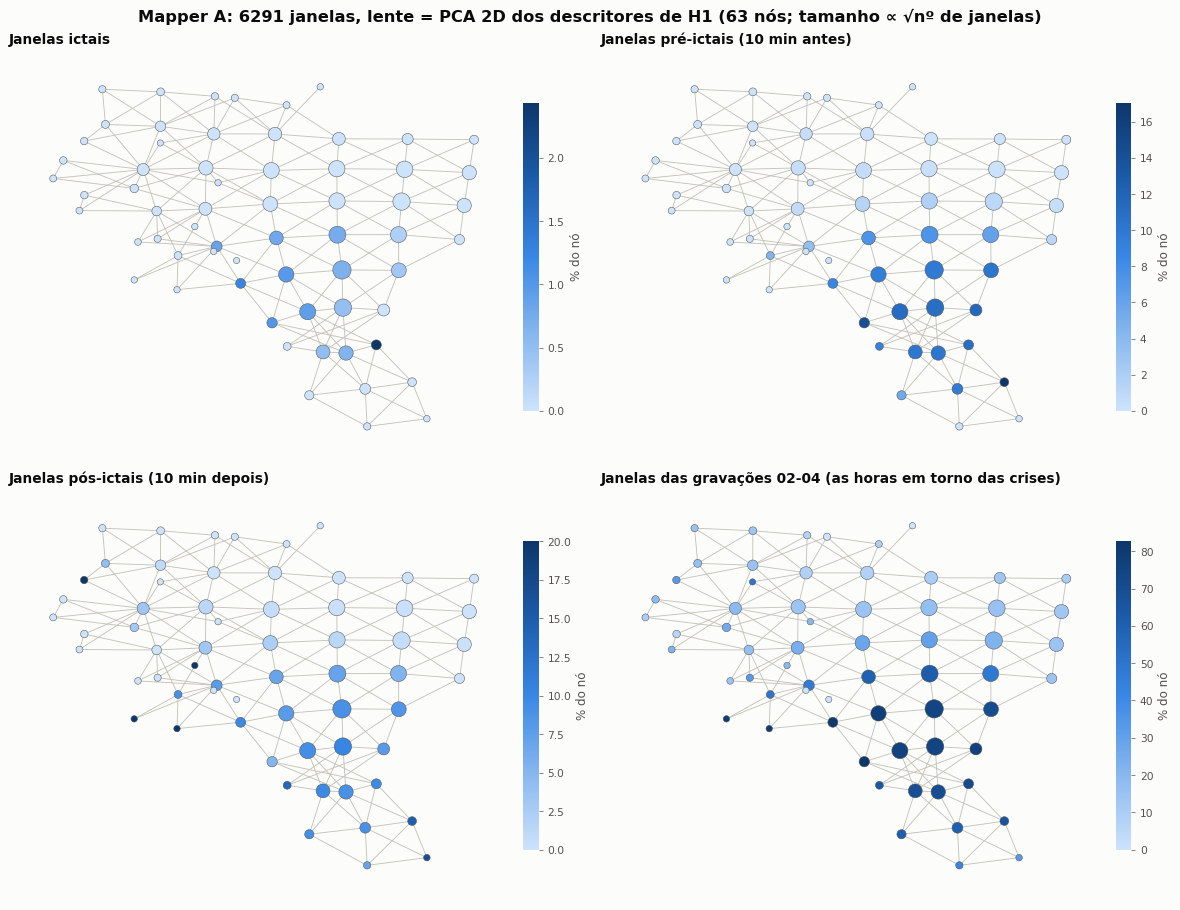

Nós com maior fração de janelas ictais:


,n_janelas,frac_ictal,frac_pre-ictal,frac_pos-ictal,pers_max_media,gravacoes
no,,,,,,
cube78_cluster0,82,0.024,0.110,0.098,0.506,"01,02,03,04,05,06,09"
cube56_cluster0,81,0.012,0.086,0.099,0.522,"01,02,03,04,05,06,09"
cube67_cluster0,98,0.010,0.143,0.051,0.503,"01,02,03,04,05,06,09"
cube55_cluster0,614,0.010,0.094,0.078,0.398,"01,02,03,04,05,06,09"
cube66_cluster0,759,0.009,0.112,0.092,0.404,"01,02,03,04,05,06,09"


In [45]:
dfk = df[df.classe != "transicao"].reset_index(drop=True)
Xk = StandardScaler().fit_transform(dfk[COLUNAS_TOPO].to_numpy(float))       # 15 descritores padronizados
eps_db = eps_heuristico(Xk)

# ---------------------------------------------------------------- Mapper A
pca = PCA(n_components=2, random_state=SEMENTE)
lente = pca.fit_transform(Xk)
mapper_a, grafo_a = construir_mapper(lente, Xk, n_cubos=12, sobreposicao=0.4, eps=eps_db)
G = para_networkx(grafo_a)
cobertas = len(np.unique(np.concatenate(list(grafo_a["nodes"].values()))))
print(f"Mapper A: {len(dfk)} janelas, DBSCAN eps = {eps_db:.2f}; a lente explica "
      f"{100 * pca.explained_variance_ratio_.sum():.0f} % da variância")
print(f"  {G.number_of_nodes()} nós, {G.number_of_edges()} arestas, "
      f"{nx.number_connected_components(G)} componentes; {cobertas} janelas em algum nó")

nos = tabela_nos(G, dfk).set_index("no").loc[list(G)]
pos = nx.kamada_kawai_layout(G)
frac_estado = np.array([dfk.iloc[G.nodes[n]["membros"]].gravacao.isin(
    ["chb01_02", "chb01_03", "chb01_04"]).mean() for n in G])
fig, eixos = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
paineis = [
    (100 * nos.frac_ictal.to_numpy(), "Janelas ictais"),
    (100 * nos["frac_pre-ictal"].to_numpy(), "Janelas pré-ictais (10 min antes)"),
    (100 * nos["frac_pos-ictal"].to_numpy(), "Janelas pós-ictais (10 min depois)"),
    (100 * frac_estado, "Janelas das gravações 02-04 (as horas em torno das crises)"),
]
for ax, (v, titulo) in zip(eixos.ravel(), paineis):
    desenhar_grafo(ax, G, pos, v, titulo, "% do nó")
    ax.set_xticks([])
    ax.set_yticks([])
    for lado in ax.spines.values():
        lado.set_visible(False)
fig.suptitle(f"Mapper A: {len(dfk)} janelas, lente = PCA 2D dos descritores de H1 "
             f"({G.number_of_nodes()} nós; tamanho ∝ √nº de janelas)")
plt.show()
print("Nós com maior fração de janelas ictais:")
display(nos.sort_values("frac_ictal", ascending=False).head(5)[
    ["n_janelas", "frac_ictal", "frac_pre-ictal", "frac_pos-ictal", "pers_max_media", "gravacoes"]].round(3))

**O que observar.** Os quatro painéis mostram o mesmo grafo, colorido de quatro formas (atenção: cada painel tem a sua própria escala de cor).

- **Ictais:** o nó "mais ictal" tem só 2 a 3 % de janelas ictais, misturadas com janelas de todas as sete gravações. Não existe uma região do grafo que seja "da crise".
- **Gravações 02–04:** este é o painel com estrutura. Há uma região do grafo dominada pelas horas em torno das crises. O que organiza a nuvem de descritores é o estado lento da Seção 5.4, e é por isso que as janelas pré-ictais e pós-ictais aparecem um pouco mais concentradas nessa mesma região.

Mapper B: 1415 janelas, 28 nós, 25 arestas, 3 componentes


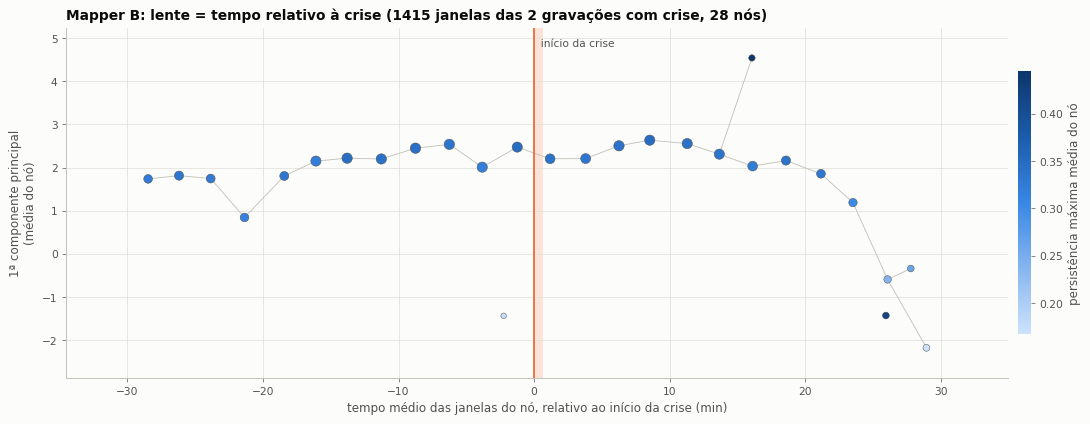

Versões interativas salvas em resultados_colab/ (mapper_A_interativo.html e mapper_B_interativo.html)


In [46]:
# ---------------------------------------------------------------- Mapper B
perto = (dfk.t_rel_crise.abs() <= 1800).to_numpy() & dfk.gravacao.isin(com_crise_nomes).to_numpy()
dfb = dfk[perto].reset_index(drop=True)
pc1 = lente[perto, 0]
mapper_b, grafo_b = construir_mapper(dfb[["t_rel_crise"]].to_numpy(float), Xk[perto], n_cubos=24,
                                     sobreposicao=0.35, eps=eps_db)
Gb = para_networkx(grafo_b)
print(f"Mapper B: {len(dfb)} janelas, {Gb.number_of_nodes()} nós, {Gb.number_of_edges()} arestas, "
      f"{nx.number_connected_components(Gb)} componentes")

# nós posicionados por (tempo médio, 1ª componente principal média): uma ramificação apareceria como
# dois nós na mesma época, em alturas diferentes
pos_b = {n: (dfb.t_rel_crise.to_numpy()[d["membros"]].mean() / 60, pc1[d["membros"]].mean())
         for n, d in Gb.nodes(data=True)}
fig, ax = plt.subplots(figsize=(12, 4.6), constrained_layout=True)
faixa_crise(ax, 0, 40 / 60, None)
ax.axvline(0, color=LARANJA, lw=1.4)
ax.text(0, 0.97, "  início da crise", transform=ax.get_xaxis_transform(), ha="left", va="top",
        fontsize=8.5, color=TINTA_2)
v = np.array([dfb.h1_pers_max.to_numpy()[Gb.nodes[n]["membros"]].mean() for n in Gb])
desenhar_grafo(ax, Gb, pos_b, v, "", "persistência máxima média do nó", vmin=None)
ax.grid(True)
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
ax.set_xlabel("tempo médio das janelas do nó, relativo ao início da crise (min)")
ax.set_ylabel("1ª componente principal\n(média do nó)")
ax.set_title(f"Mapper B: lente = tempo relativo à crise ({len(dfb)} janelas das 2 gravações com crise, "
             f"{Gb.number_of_nodes()} nós)")
plt.show()

# versões interativas (abra os arquivos .html no navegador)
try:
    mapper_a.visualize(
        grafo_a, path_html=str(DIR_SAIDA / "mapper_A_interativo.html"),
        title="Mapper A - janelas de EEG (descritores de H1), lente PCA 2D",
        color_values=np.c_[(dfk.classe == "ictal").to_numpy(float), (dfk.classe == "pre-ictal").to_numpy(float),
                           dfk.h1_pers_max.to_numpy(), dfk.h1_pers_total.to_numpy()],
        color_function_name=["fração ictal", "fração pré-ictal", "persistência máxima", "persistência total"],
        custom_tooltips=(dfk.gravacao + " t=" + dfk.t_ini.astype(int).astype(str) + "s " + dfk.classe).to_numpy())
    mapper_b.visualize(
        grafo_b, path_html=str(DIR_SAIDA / "mapper_B_interativo.html"),
        title="Mapper B - lente: tempo relativo ao início da crise",
        color_values=np.c_[dfb.t_rel_crise.to_numpy() / 60, dfb.h1_pers_max.to_numpy()],
        color_function_name=["tempo relativo à crise (min)", "persistência máxima"],
        custom_tooltips=(dfb.gravacao + " t=" + dfb.t_ini.astype(int).astype(str) + "s " + dfb.classe).to_numpy())
    print(f"Versões interativas salvas em {DIR_SAIDA}/ (mapper_A_interativo.html e mapper_B_interativo.html)")
except Exception as erro:      # o HTML é um extra; uma falha aqui não afeta o restante do notebook
    print("Não foi possível gerar o HTML interativo do Mapper:", repr(erro))

**O que observar.** Com a lente de tempo, o grafo é praticamente um caminho que acompanha o eixo horizontal, com alguns nós pequenos fora dele. Se a crise fosse um regime topológico distinto, esperaríamos uma ramificação ou uma quebra do caminho perto do tempo zero. Não há: os nós que contêm a crise estão ligados aos vizinhos de antes e de depois como quaisquer outros.

As duas versões interativas ficam na pasta `resultados_colab/` (no Colab, use o painel de arquivos à esquerda para baixá-las e abra no navegador).

## 9. Sensibilidade ao canal e a $(d, \tau)$

Uma objeção razoável a tudo o que veio antes: *talvez o problema seja a escolha de FP1-F7, ou de $d=3$ e $\tau=4$. Em outro canal, mais perto do foco da crise, ou com outros parâmetros, a topologia poderia funcionar.*

Esta seção repete a medida central, a AUROC ictal × interictal **das mesmas gravações** (a referência local da Seção 5.4), em:

- uma grade de 20 configurações: $d \in \{2,3,4,5\}$ e $\tau \in \{2,4,7,10,14\}$, no canal FP1-F7;
- os 21 canais bipolares distintos do registro, com $d=3$ e $\tau=4$.

**Cuidado metodológico.** Estas tabelas servem para saber se a conclusão é robusta, e não para escolher o melhor canal ou o melhor parâmetro. Escolher o máximo de 41 tentativas e reportar o desempenho dele seria seleção com os mesmos dados da avaliação. É por isso que a análise principal usa os valores fixados de antemão.

**Custo.** Como a referência são as mesmas gravações, só é preciso processar as janelas ictais e interictais de `chb01_03` e `chb01_04` (cerca de 1 200 por configuração). O motor é sempre o Ripser, como no projeto. Ainda assim esta é a seção mais demorada do notebook.

In [47]:
DIMS_SENS = [2, 3, 4, 5]
ATRASOS_SENS = [2, 4, 7, 10, 14]
DESCR_SENS = ["h1_pers_max", "h1_pers_total", "h1_entropia", "h1_pais2_l1"]
NOMES_SENS = {"h1_pers_max": "persistência máxima", "h1_pers_total": "persistência total",
              "h1_entropia": "entropia", "h1_pais2_l1": "paisagem λ2 (L1)",
              "log_variancia": "log-variância (baseline)"}


def aucs_ictal(dfs, colunas):
    """AUROC ictal x interictal de cada coluna (dfs só tem as gravações com crise)."""
    ict, inter = dfs[dfs.classe == "ictal"], dfs[dfs.classe == "interictal"]
    return {c: auc(ict[c].to_numpy(float), inter[c].to_numpy(float)) for c in colunas}


if RODAR_SENSIBILIDADE:
    comum = dict(so_classes=["ictal", "interictal"], com_bottleneck=False, motor="ripser", verbose=False)
    t0 = time.time()

    # --- (d, tau) no canal do enunciado
    linhas = []
    for d in DIMS_SENS:
        for tau_s in ATRASOS_SENS:
            dfs, _ = extrair(gravs_crise, dim=d, atraso=tau_s, com_baseline=False, **comum)
            linhas.append({"dim": d, "atraso": tau_s, "n_pontos": int(dfs.n_pontos.iloc[0]),
                           **aucs_ictal(dfs, DESCR_SENS)})
    grade_sens = pd.DataFrame(linhas)
    print(f"Grade (d, τ): {len(grade_sens)} configurações em {time.time() - t0:.0f} s")

    # --- canais, com (d, tau) do enunciado
    canais = nomes_canais(gravs[0].caminho)
    for g in gravs_crise:                      # lê todos os canais de uma vez (mais rápido que um por um)
        Xc, _ = carregar_canais(g.caminho, canais)
        for c, xc in zip(canais, Xc):
            _SINAIS[(g.caminho.name, c)] = xc
    linhas = []
    for c in canais:
        dfs, _ = extrair(gravs_crise, canal=c, com_baseline=True, **comum)
        linhas.append({"canal": c, **aucs_ictal(dfs, DESCR_SENS + ["log_variancia"])})
    por_canal = pd.DataFrame(linhas)
    print(f"Canais: {len(canais)} em {time.time() - t0:.0f} s no total")
else:
    print("Sensibilidade desligada (RODAR_SENSIBILIDADE = False).")

Grade (d, τ): 20 configurações em 15 s


Canais: 21 em 34 s no total


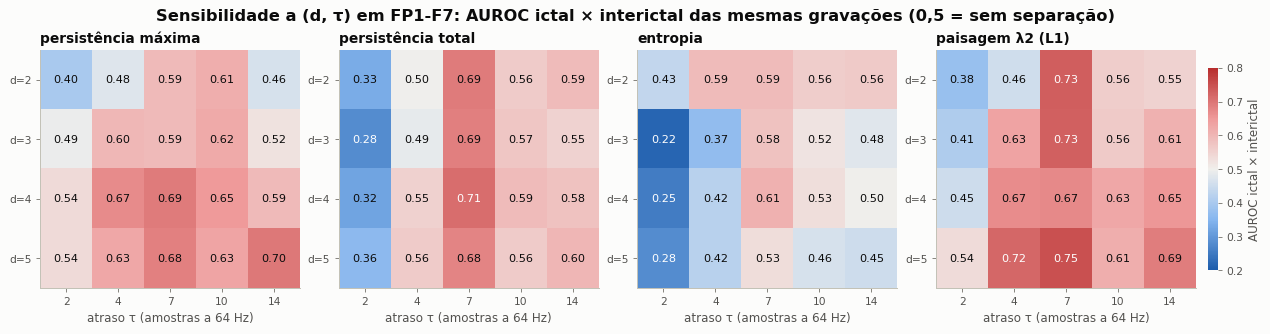

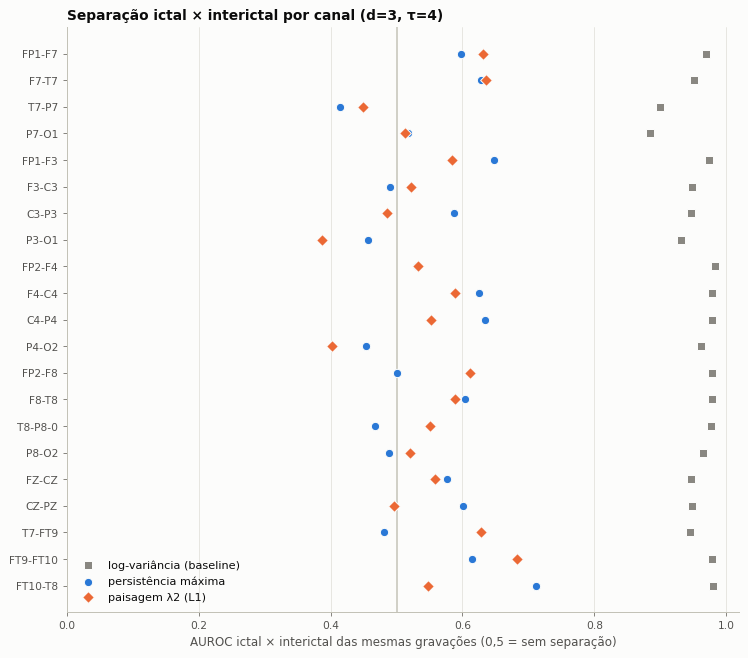

Faixa de AUROC por descritor:
  persistência máxima        grade (d, τ): 0.40 a 0.70   |   canais: 0.41 a 0.71
  persistência total         grade (d, τ): 0.28 a 0.71   |   canais: 0.33 a 0.61
  entropia                   grade (d, τ): 0.22 a 0.61   |   canais: 0.25 a 0.67
  paisagem λ2 (L1)           grade (d, τ): 0.38 a 0.75   |   canais: 0.39 a 0.68
  log-variância (baseline)   canais: 0.89 a 0.98


In [48]:
def mapa_calor(ax, M, titulo, linhas, colunas):
    im = ax.imshow(M, cmap=DIV, vmin=0.2, vmax=0.8, aspect="auto")
    ax.set_xticks(range(len(colunas)), colunas)
    ax.set_yticks(range(len(linhas)), linhas)
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color=TINTA if abs(M[i, j] - 0.5) < 0.2 else "#ffffff")
    ax.set_title(titulo)
    return im


if RODAR_SENSIBILIDADE:
    fig, eixos = plt.subplots(1, 4, figsize=(14, 3.6), constrained_layout=True)
    for ax, c in zip(eixos, DESCR_SENS):
        M = grade_sens.pivot(index="dim", columns="atraso", values=c).to_numpy()
        im = mapa_calor(ax, M, NOMES_SENS[c], [f"d={d}" for d in DIMS_SENS], [str(a) for a in ATRASOS_SENS])
        ax.set_xlabel("atraso τ (amostras a 64 Hz)")
    cb = fig.colorbar(im, ax=eixos, shrink=0.85, pad=0.01)
    cb.set_label("AUROC ictal × interictal")
    cb.outline.set_visible(False)
    fig.suptitle(f"Sensibilidade a (d, τ) em {CANAL}: AUROC ictal × interictal das mesmas gravações "
                 "(0,5 = sem separação)")
    plt.show()

    series = [("log_variancia", MUDO, "s"), ("h1_pers_max", AZUL, "o"), ("h1_pais2_l1", LARANJA, "D")]
    fig, ax = plt.subplots(figsize=(8.2, 7.2), constrained_layout=True)
    yc = np.arange(len(canais))[::-1]
    ax.axvline(0.5, color=EIXO, lw=1.2)
    for c, cor, marc in series:
        ax.scatter(por_canal[c], yc, s=44, color=cor, marker=marc, zorder=3,
                   edgecolor=SUPERFICIE, linewidths=0.8, label=NOMES_SENS[c])
    ax.set_yticks(yc, canais)
    ax.set_xlim(0, 1.02)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("AUROC ictal × interictal das mesmas gravações (0,5 = sem separação)")
    ax.set_title(f"Separação ictal × interictal por canal (d={DIM}, τ={ATRASO})")
    ax.legend(loc="lower left")
    plt.show()

    print("Faixa de AUROC por descritor:")
    for c in DESCR_SENS:
        print(f"  {NOMES_SENS[c]:26s} grade (d, τ): {grade_sens[c].min():.2f} a {grade_sens[c].max():.2f}   |   "
              f"canais: {por_canal[c].min():.2f} a {por_canal[c].max():.2f}")
    print(f"  {NOMES_SENS['log_variancia']:26s} canais: {por_canal.log_variancia.min():.2f} a "
          f"{por_canal.log_variancia.max():.2f}")

**O que observar.**

- **Grade $(d,\tau)$:** a persistência máxima fica entre 0,40 e 0,70 em toda a grade. Nenhuma combinação se aproxima do baseline de amplitude. Os valores sobem um pouco com $d \ge 4$ e $\tau \ge 4$, na direção apontada pela Seção 3, mas continuam modestos.
- **Canais:** em todos os 21 canais a log-variância (quadrados cinza) fica entre 0,89 e 0,98. A persistência máxima (círculos azuis) fica entre 0,41 e 0,71, espalhada em torno de 0,5.

A conclusão não depende da escolha de FP1-F7 nem de $d=3$, $\tau=4$.

## 10. Animações

Duas animações que mostram o algoritmo em execução. Os arquivos GIF ficam em `resultados_colab/`.

**10.1 A filtração de Vietoris–Rips.** É a figura da Seção 1.2 em movimento: os discos crescem em torno dos pontos da nuvem, surgem arestas e triângulos, e o código de barras de $H_1$ é desenhado junto com a curva do número de ciclos vivos em cada escala (a curva de Betti $\beta_1$).

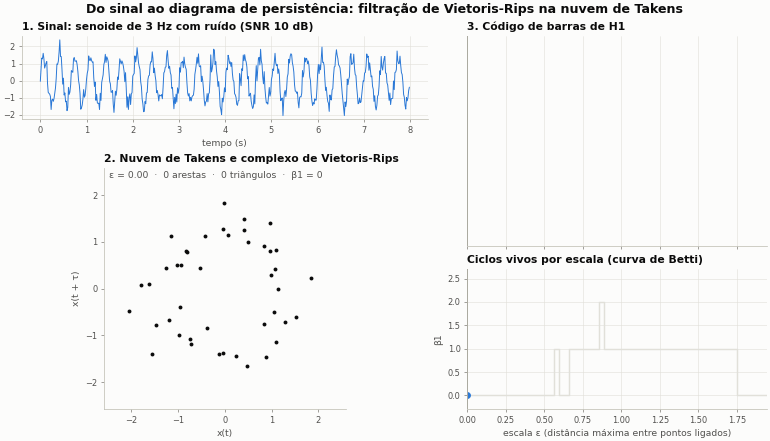

In [49]:
def animar_filtracao(caminho, n_quadros=60, fps=10, dpi=70):
    D = comp["D"]
    grade = np.r_[np.linspace(0, eps_max, n_quadros), np.full(12, eps_max)]       # pausa no fim
    betti = np.array([np.sum((h1_cena[:, 0] <= e) & (h1_cena[:, 1] > e)) for e in grade])

    fig = plt.figure(figsize=(11, 6.3), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 2.9], width_ratios=[1.2, 1])
    ax_s, ax_c = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
    gd = gs[:, 1].subgridspec(2, 1, height_ratios=[1.5, 1])
    ax_b = fig.add_subplot(gd[0])
    ax_n = fig.add_subplot(gd[1], sharex=ax_b)

    ax_s.plot(T, x_cena, color=AZUL, lw=1)
    ax_s.set_title("1. Sinal: senoide de 3 Hz com ruído (SNR 10 dB)")
    ax_s.set_xlabel("tempo (s)")

    lim = np.abs(X_cena).max() + eps_max / 2 * 0.55
    ax_c.set_xlim(-lim, lim)
    ax_c.set_ylim(-lim, lim)
    ax_c.set_aspect("equal")
    ax_c.set_xlabel("x(t)")
    ax_c.set_ylabel("x(t + τ)")
    ax_c.grid(False)
    ax_c.scatter(X_cena[:, 0], X_cena[:, 1], s=16, color=TINTA, zorder=5, linewidths=0)
    ax_c.set_title("2. Nuvem de Takens e complexo de Vietoris-Rips")
    titulo_c = ax_c.text(0.02, 0.985, "", transform=ax_c.transAxes, ha="left", va="top",
                         fontsize=9.5, color=TINTA_2)

    ax_b.set_xlim(0, eps_max)
    ax_b.set_ylim(-1, len(h1_cena))
    ax_b.set_yticks([])
    ax_b.grid(axis="y", visible=False)
    ax_b.set_title("3. Código de barras de H1")
    ax_b.tick_params(labelbottom=False)
    rot_p = ax_b.text(0, 0, "", fontsize=9, color=TINTA_2, va="center")
    ax_n.plot(grade[:n_quadros], betti[:n_quadros], color=GRADE, lw=1.5, drawstyle="steps-post")
    curva, = ax_n.plot([], [], color=AZUL, lw=2, drawstyle="steps-post")
    ponto, = ax_n.plot([], [], "o", color=AZUL, ms=6)
    ax_n.set_ylim(-0.3, betti.max() + 0.7)
    ax_n.set_xlabel("escala ε (distância máxima entre pontos ligados)")
    ax_n.set_ylabel("β1")
    ax_n.set_title("Ciclos vivos por escala (curva de Betti)")
    linha_b = ax_b.axvline(0, color=TINTA_2, lw=1)
    linha_n = ax_n.axvline(0, color=TINTA_2, lw=1)
    fig.suptitle("Do sinal ao diagrama de persistência: filtração de Vietoris-Rips na nuvem de Takens")

    estado = {"art": []}

    def quadro(k):
        e = grade[k]
        for a in estado["art"]:
            a.remove()
        estado["art"] = desenhar_complexo(ax_c, X_cena, comp, e) + [desenhar_barras(ax_b, h1_cena, e, principal)]
        titulo_c.set_text(f"ε = {e:.2f}  ·  {int((comp['val_aresta'] <= e).sum())} arestas  ·  "
                          f"{int((comp['val_tri'] <= e).sum())} triângulos  ·  β1 = {betti[k]}")
        if h1_cena[principal, 0] <= e:
            rot_p.set_position((h1_cena[principal, 0], principal + 0.32))
            rot_p.set_text("ciclo principal: o laço do sinal periódico")
        curva.set_data(grade[: k + 1], betti[: k + 1])
        ponto.set_data([e], [betti[k]])
        linha_b.set_xdata([e, e])
        linha_n.set_xdata([e, e])
        return []

    FuncAnimation(fig, quadro, frames=len(grade), blit=False).save(caminho, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)


if GERAR_ANIMACOES:
    gif_filtracao = DIR_SAIDA / "animacao_filtracao_rips.gif"
    animar_filtracao(gif_filtracao)
    display(Image(filename=str(gif_filtracao)))

**10.2 A janela deslizante no EEG real.** O pipeline inteiro em torno da crise de `chb01_03`: a janela de 8 s percorre o sinal; para cada posição aparecem a nuvem de Takens ($d=3$, projetada nas duas primeiras coordenadas), o diagrama de $H_1$ e a persistência máxima acumulada. A cor da janela indica a classe.

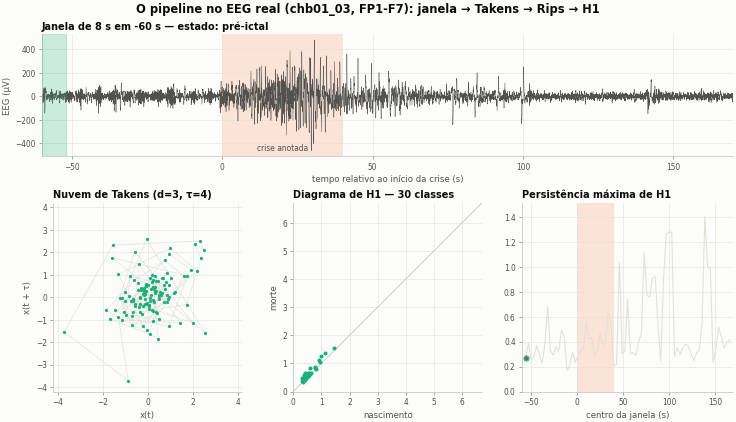

In [50]:
def animar_janela(caminho, antes=60.0, depois=170.0, passo=3, fps=8, dpi=64):
    g = gravs_crise[0]
    ini, fim = g.crises[0]
    m = ((zoom.gravacao == g.nome) & (zoom.t_ini >= ini - antes) & (zoom.t_fim <= ini + depois)).to_numpy()
    idx = np.flatnonzero(m)[::passo]
    x, fs = carregar_canal(g.caminho)
    w = int(JANELA_S * fs)

    t_ini = zoom.t_ini.to_numpy()
    centro = t_ini[idx] + JANELA_S / 2 - ini
    pmax = zoom.h1_pers_max.to_numpy()[idx]
    # limite do diagrama: morte do ciclo mais persistente entre todos os quadros
    lim_d = max(2.5, 1.15 * max(diagramas_zoom[i][np.argmax(persistencias(diagramas_zoom[i])), 1] for i in idx))
    rot_classe = {"interictal": "antes da crise", "pre-ictal": "pré-ictal", "ictal": "ICTAL",
                  "transicao": "transição", "pos-ictal": "pós-ictal"}

    fig = plt.figure(figsize=(11.5, 6.6), constrained_layout=True)
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.55])
    ax_e = fig.add_subplot(gs[0, :])
    ax_c, ax_d, ax_p = (fig.add_subplot(gs[1, j]) for j in range(3))

    i0, i1 = int((ini - antes) * fs), int((ini + depois) * fs)
    ax_e.plot(np.arange(i0, i1) / fs - ini, x[i0:i1], color=TINTA_2, lw=0.5)
    faixa_crise(ax_e, 0, fim - ini)
    ax_e.text((fim - ini) / 2, 0.03, "crise anotada", transform=ax_e.get_xaxis_transform(),
              ha="center", va="bottom", fontsize=8.5, color=TINTA_2)
    ax_e.set_xlim(-antes, depois)
    ax_e.set_ylabel("EEG (µV)")
    ax_e.set_xlabel("tempo relativo ao início da crise (s)")
    titulo_e = ax_e.set_title("")
    yl = ax_e.get_ylim()
    janela = Rectangle((0, yl[0]), JANELA_S, yl[1] - yl[0], facecolor=AZUL, alpha=0.22,
                       edgecolor=AZUL, lw=1.2, zorder=4)
    ax_e.add_patch(janela)

    ax_c.set_xlim(-4.2, 4.2)
    ax_c.set_ylim(-4.2, 4.2)
    ax_c.set_aspect("equal")
    ax_c.set_xlabel("x(t)")
    ax_c.set_ylabel("x(t + τ)")
    ax_c.set_title(f"Nuvem de Takens (d={DIM}, τ={ATRASO})")
    traj, = ax_c.plot([], [], color=GRADE, lw=0.7, zorder=1)
    nuvem = ax_c.scatter([], [], s=13, linewidths=0, zorder=2)

    ax_d.plot([0, lim_d], [0, lim_d], color=EIXO, lw=0.9)
    ax_d.set_xlim(0, lim_d)
    ax_d.set_ylim(0, lim_d)
    ax_d.set_aspect("equal")
    ax_d.set_xlabel("nascimento")
    ax_d.set_ylabel("morte")
    titulo_d = ax_d.set_title("")
    diag = ax_d.scatter([], [], s=20, linewidths=0, zorder=3)

    faixa_crise(ax_p, 0, fim - ini)
    ax_p.plot(centro, pmax, color=GRADE, lw=1.2)
    tr, = ax_p.plot([], [], color=AZUL, lw=1.8)
    pt, = ax_p.plot([], [], "o", color=AZUL, ms=6)
    ax_p.set_xlim(-antes, depois)
    ax_p.set_ylim(0, pmax.max() * 1.08)
    ax_p.set_xlabel("centro da janela (s)")
    ax_p.set_title("Persistência máxima de H1")
    fig.suptitle(f"O pipeline no EEG real ({g.nome}, {CANAL}): janela → Takens → Rips → H1")

    def quadro(k):
        i = idx[k]
        seg = x[int(round(t_ini[i] * fs)): int(round(t_ini[i] * fs)) + w]
        X = imersao_takens(seg, DIM, ATRASO, PASSO_NUVEM)
        classe = zoom.classe.iloc[i]
        cor = COR_CLASSE.get(classe, AZUL)
        janela.set_x(t_ini[i] - ini)
        janela.set_facecolor(cor)
        janela.set_edgecolor(cor)
        titulo_e.set_text(f"Janela de 8 s em {t_ini[i] - ini:+.0f} s — estado: {rot_classe[classe]}")
        traj.set_data(X[:, 0], X[:, 1])
        nuvem.set_offsets(X[:, :2])
        nuvem.set_color(cor)
        diag.set_offsets(diagramas_zoom[i])
        diag.set_color(cor)
        titulo_d.set_text(f"Diagrama de H1 — {len(diagramas_zoom[i])} classes")
        tr.set_data(centro[: k + 1], pmax[: k + 1])
        pt.set_data([centro[k]], [pmax[k]])
        return []

    FuncAnimation(fig, quadro, frames=len(idx), blit=False).save(caminho, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)


if GERAR_ANIMACOES:
    gif_janela = DIR_SAIDA / "animacao_janela_deslizante.gif"
    animar_janela(gif_janela)
    display(Image(filename=str(gif_janela)))

**O que observar.** Quando a janela entra na crise (fica laranja), o EEG muda de cara, mas a nuvem continua sendo um novelo e o diagrama continua com todos os pontos perto da diagonal. A curva de persistência máxima atravessa a faixa da crise sem sair do lugar. É o resultado do projeto em uma imagem.

## 11. Outros pacientes e a definição supervisionada do enunciado

Tudo até aqui usou **7 horas de um paciente, com duas crises**. O enunciado pede duas coisas que isso não permite:

- testar a hipótese "ao longo de diferentes janelas **e pacientes**";
- avaliar um detector com treino e teste **em pacientes diferentes**, que é o que mede generalização para um indivíduo novo.

Esta seção repete o pipeline, sem mudar nenhum parâmetro, no chb01 inteiro e em mais dois pacientes do CHB-MIT, e depois segue a definição supervisionada do enunciado (amostras, rótulos, saída e avaliação).

| Paciente | Gravações usadas | Crises |
|---|---|---|
| chb01 | todas as 42 (as 7 das seções anteriores e mais 35) | 7, todas as do paciente |
| chb02 | 01–19 (a 16 vem em dois arquivos, `16` e `16+`) | 3, todas as do paciente |
| chb03 | 01–08 | 4 das 7 do paciente |

### 11.1 Download e extração

Cada paciente tem o seu arquivo de resumo e a sua **própria linha do tempo**: as crises de um paciente nunca rotulam janelas de outro. Como conferência, as 7 gravações das seções anteriores são extraídas de novo e comparadas com a tabela da Seção 4.

In [51]:
GRAVACOES_MULTI = {
    # chb01: as 42 gravações do resumo (não existem 28, 35, 44 e 45)
    "chb01": [f"chb01_{i:02d}" for i in list(range(1, 28)) + list(range(29, 35)) + list(range(36, 44)) + [46]],
    "chb02": [f"chb02_{i:02d}" for i in range(1, 16)] + ["chb02_16", "chb02_16+", "chb02_17", "chb02_18", "chb02_19"],
    "chb03": [f"chb03_{i:02d}" for i in range(1, 9)],
}
PACIENTES = list(GRAVACOES_MULTI)
COR_PAC = {"chb01": AZUL, "chb02": AGUA, "chb03": VIOLETA}
MARCA_PAC = {"chb01": "o", "chb02": "s", "chb03": "D"}

if RODAR_MULTIPACIENTE:
    novos = ([f"{p}-summary.txt" for p in PACIENTES[1:]]
             + [f"{g}.edf" for p in PACIENTES for g in GRAVACOES_MULTI[p] if g not in GRAVACOES])
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=4) as pool:
        baixados = sum(novo for _, novo in pool.map(baixar, novos))
    print(f"{len(novos)} arquivos novos ({baixados} baixados agora) | {time.time() - t0:.0f} s")

    gravs_multi, partes = {}, []
    for pac in PACIENTES:
        gravs_multi[pac] = listar_gravacoes(nomes=GRAVACOES_MULTI[pac])
        d, _ = extrair(gravs_multi[pac], verbose=False)
        d.insert(0, "paciente", pac)
        partes.append(d)
        print(f"  {pac}: {len(d)} janelas | {time.time() - t0:.0f} s")
    dfx = pd.concat(partes, ignore_index=True)

    # conferência: as 7 gravações das seções anteriores dão os mesmos descritores
    iguais = dfx.merge(df, on=["gravacao", "t_ini"], suffixes=("", "_s4"))
    print(f"Conferência com a Seção 4: {len(iguais)} janelas em comum, maior diferença na persistência máxima = "
          f"{(iguais.h1_pers_max - iguais.h1_pers_max_s4).abs().max():.1e}")

    resumo_pac = (dfx.pivot_table(index="paciente", columns="classe", values="t_ini", aggfunc="size")
                  .fillna(0).astype(int)[["interictal", "pre-ictal", "ictal", "pos-ictal", "transicao"]])
    resumo_pac.insert(0, "crises", [sum(len(g.crises) for g in gravs_multi[p]) for p in resumo_pac.index])
    resumo_pac.insert(0, "horas", (dfx.groupby("paciente").size() * PASSO_S / 3600).round(1))
    resumo_pac.insert(0, "gravações", dfx.groupby("paciente").gravacao.nunique())
    display(resumo_pac)

65 arquivos novos (0 baixados agora) | 0 s


  chb01: 36454 janelas | 67 s


  chb02: 17319 janelas | 100 s


  chb03: 7192 janelas | 113 s
Conferência com a Seção 4: 6293 janelas em comum, maior diferença na persistência máxima = 0.0e+00


classe,gravações,horas,crises,interictal,pre-ictal,ictal,pos-ictal,transicao
paciente,,,,,,,,
chb01,42,40.5,7,34303,987,114,1042,8
chb02,20,19.2,3,16473,447,44,351,4
chb03,8,8.0,4,5989,536,61,600,6


**O que observar.** São 68 horas de EEG, 14 crises e 219 janelas ictais (antes eram 18). A proporção continua minúscula: 0,4 % das janelas. A crise de `chb02_19` dura só 9 s e rende 2 janelas ictais.

### 11.2 A separação ictal × interictal, paciente por paciente

A mesma conta da Seção 5.3, agora dentro de cada paciente e com as duas referências: o interictal de todas as gravações do paciente e o interictal só das gravações que têm crise (a comparação justa da Seção 5.4).

todas as gravações             mesmas gravações            
paciente                              chb01 chb02 chb03            chb01 chb02 chb03
descritor                                                                           
persistência máxima                    0.54  0.53  0.42             0.50  0.62  0.41
persistência total                     0.66  0.65  0.53             0.47  0.63  0.65
entropia de persistência               0.57  0.61  0.59             0.45  0.51  0.68
paisagem λ2 (L1)                       0.68  0.66  0.51             0.50  0.68  0.64
bottleneck d_B                         0.43  0.42  0.47             0.48  0.55  0.40
log-variância (baseline)               0.93  0.93  0.96             0.97  0.90  0.89

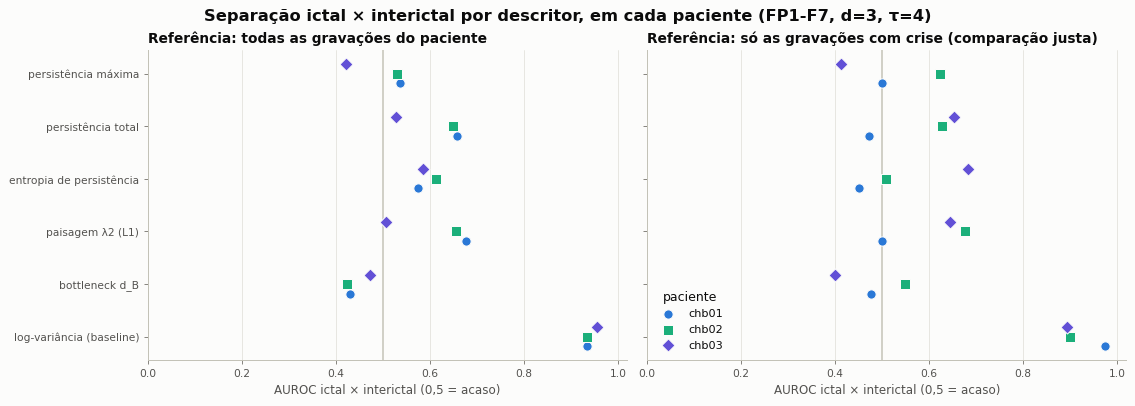

In [52]:
DESCR_MULTI = {
    "h1_pers_max": "persistência máxima",
    "h1_pers_total": "persistência total",
    "h1_entropia": "entropia de persistência",
    "h1_pais2_l1": "paisagem λ2 (L1)",
    "bottleneck": "bottleneck d_B",
    "log_variancia": "log-variância (baseline)",
}


def auroc_por_paciente(dfx):
    linhas = []
    for pac, sub in dfx.groupby("paciente"):
        cl = sub.classe.to_numpy()
        com_crise = sub.gravacao.isin(sub.loc[sub.classe == "ictal", "gravacao"].unique()).to_numpy()
        for c in DESCR_MULTI:
            v = sub[c].to_numpy(float)
            linhas.append({"paciente": pac, "descritor": DESCR_MULTI[c],
                           "todas as gravações": auc(v[cl == "ictal"], v[cl == "interictal"]),
                           "mesmas gravações": auc(v[cl == "ictal"], v[(cl == "interictal") & com_crise])})
    return pd.DataFrame(linhas)


if RODAR_MULTIPACIENTE:
    tab_pac = auroc_por_paciente(dfx)
    nomes_d = list(DESCR_MULTI.values())
    display(tab_pac.pivot(index="descritor", columns="paciente",
                          values=["todas as gravações", "mesmas gravações"]).loc[nomes_d].round(2))

    yy = np.arange(len(nomes_d))[::-1]
    fig, eixos = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True, constrained_layout=True)
    for ax, col, tit in zip(eixos, ["todas as gravações", "mesmas gravações"],
                            ["Referência: todas as gravações do paciente",
                             "Referência: só as gravações com crise (comparação justa)"]):
        ax.axvline(0.5, color=EIXO, lw=1.2)
        for k, pac in enumerate(PACIENTES):
            v = tab_pac[tab_pac.paciente == pac].set_index("descritor")[col].loc[nomes_d]
            ax.scatter(v, yy + (k - 1) * 0.18, s=55, marker=MARCA_PAC[pac], color=COR_PAC[pac],
                       edgecolor=SUPERFICIE, linewidths=0.8, zorder=3, label=pac)
        ax.set_xlim(0, 1.02)
        ax.set_xlabel("AUROC ictal × interictal (0,5 = acaso)")
        ax.set_title(tit)
        ax.grid(axis="y", visible=False)
    eixos[0].set_yticks(yy, nomes_d)
    eixos[1].legend(loc="lower left", title="paciente")
    fig.suptitle(f"Separação ictal × interictal por descritor, em cada paciente ({CANAL}, d={DIM}, τ={ATRASO})")
    plt.show()

**O que observar.** Em cada linha, os três símbolos são os três pacientes. Com a referência justa (painel da direita), os descritores de $H_1$ ficam espalhados em torno de 0,5; a log-variância fica perto de 0,9 nos três. Três detalhes:

- No chb01, com as 7 crises, a persistência máxima cai para 0,50. O 0,60 da Seção 5.3 vinha de 2 crises e não se sustentou.
- No chb03 ela fica **abaixo** de 0,5 (0,41): tende a *cair* durante a crise, o contrário da hipótese.
- A paisagem $\lambda_2$, o descritor topológico mais promissor nas seções anteriores, fica em 0,50 no chb01 inteiro.

### 11.3 As 14 crises, uma a uma

Para comparar crises de pacientes diferentes na mesma escala, a pergunta é: **quão incomum é o trecho da crise** entre trechos interictais de mesma duração do mesmo paciente? É o teste por blocos da Seção 5.5, crise a crise. O resultado é um percentil: 50 é um trecho interictal comum; 100 é mais extremo do que todos.

janelas ictais  persistência máxima  paisagem λ2 (L1)  log-variância (baseline)
paciente crise                                                                                           
chb01    chb01_03@2996s               11                   58                93                        98
         chb01_04@1467s                7                   57                85                        96
         chb01_15@1732s               11                   64                74                        97
         chb01_16@1015s               13                   17                70                       100
         chb01_18@1720s               23                   54                56                       100
         chb01_21@327s                24                   35                65                       100
         chb01_26@1862s               25                   39                90                       100
chb02    chb02_16@130s                21                   27                69                        98
         chb02_16+@2972s              21                   54                90                        97
         chb02_19@3369s                2                   34                45                        95
chb03    chb03_01@362s                13                   34                50                        95
         chb03_02@731s                17                   34                46                        99
         chb03_03@432s                18                   10                40                       100
         chb03_04@2162s               13                   13                59                        96

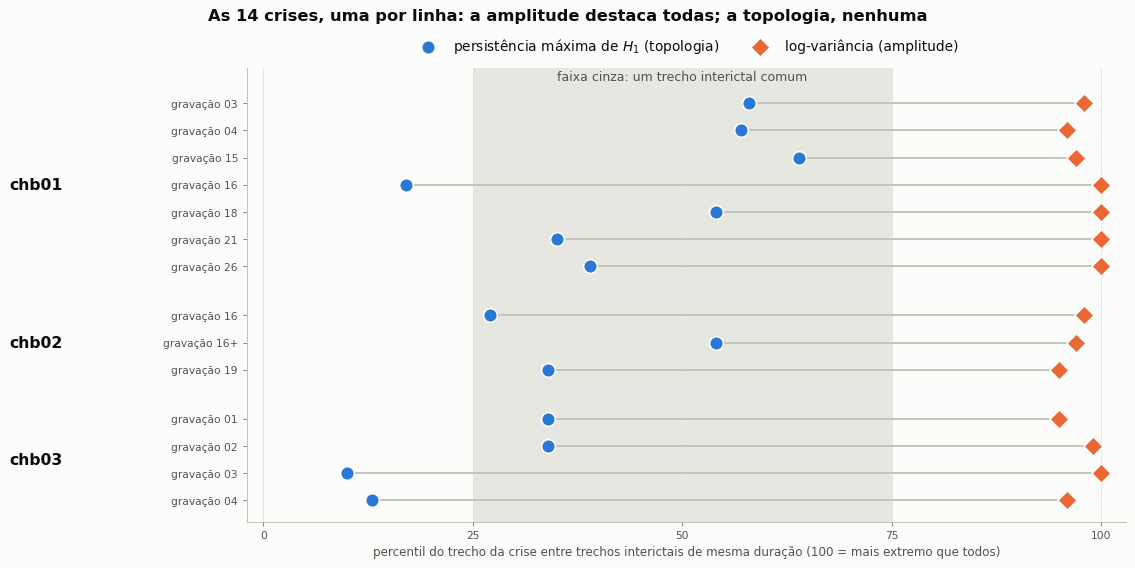

In [53]:
if RODAR_MULTIPACIENTE:
    # teste por blocos, crise a crise: o trecho ictal contra blocos interictais de mesma duração
    linhas = []
    for crise, ict in dfx[dfx.classe == "ictal"].groupby("crise_proxima", sort=False):
        sub = dfx[dfx.paciente == ict.paciente.iloc[0]]
        r_ = {"paciente": ict.paciente.iloc[0], "crise": crise, "janelas ictais": len(ict)}
        for c in ("h1_pers_max", "h1_pais2_l1", "log_variancia"):
            nulo = blocos_interictais(sub, c, len(ict))
            r_[DESCR_MULTI[c]] = round(float(np.mean(nulo <= np.nanmean(ict[c])) * 100))
        linhas.append(r_)
    perc_crises = pd.DataFrame(linhas)
    display(perc_crises.set_index(["paciente", "crise"]))

    # uma linha por crise: bolinha = topologia, losango = amplitude
    n = len(perc_crises)
    y = np.arange(n)[::-1].astype(float)
    for i in range(1, n):
        if perc_crises.paciente[i] != perc_crises.paciente[i - 1]:
            y[i:] -= 0.8                                    # um respiro entre pacientes
    h = perc_crises[DESCR_MULTI["h1_pers_max"]].to_numpy()
    v = perc_crises[DESCR_MULTI["log_variancia"]].to_numpy()
    fig, ax = plt.subplots(figsize=(12.5, 6.2), constrained_layout=True)
    ax.axvspan(25, 75, color=GRADE, alpha=0.75, lw=0, zorder=0)
    for yi, hi, vi in zip(y, h, v):
        ax.plot([hi, vi], [yi, yi], color=EIXO, lw=1.5, zorder=1)
    ax.scatter(h, y, s=120, color=AZUL, zorder=3, edgecolor=SUPERFICIE, linewidths=1.3,
               label="persistência máxima de $H_1$ (topologia)")
    ax.scatter(v, y, s=120, marker="D", color=LARANJA, zorder=3, edgecolor=SUPERFICIE, linewidths=1.3,
               label="log-variância (amplitude)")
    ax.set_yticks(y, ["gravação " + c.split("@")[0].split("_")[1] for c in perc_crises.crise])
    for pac in PACIENTES:
        m = (perc_crises.paciente == pac).to_numpy()
        ax.text(-24, y[m].mean(), pac, ha="right", va="center", fontsize=12.5, fontweight="bold", clip_on=False)
    ax.set_xlim(-2, 103)
    ax.set_ylim(y.min() - 0.8, y.max() + 1.3)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.grid(axis="y", visible=False)
    ax.text(50, y.max() + 1.2, "faixa cinza: um trecho interictal comum", ha="center", va="top", fontsize=10, color=TINTA_2)
    ax.set_xlabel("percentil do trecho da crise entre trechos interictais de mesma duração (100 = mais extremo que todos)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=11)
    fig.suptitle(f"As {n} crises, uma por linha: a amplitude destaca todas; a topologia, nenhuma")
    plt.show()

**O que observar.** Os losangos laranja (amplitude) ficam todos entre 95 e 100. As bolinhas azuis (persistência máxima) ficam entre 10 e 64: dentro ou abaixo da faixa de um trecho interictal comum, **nas 14 crises**.

Na tabela, a paisagem $\lambda_2$ mostra por que um paciente não basta: percentis de 56 a 93 nas crises do chb01 e de 40 a 59 nas do chb03.

### 11.4 O "estado lento" visto em 40 horas

A Seção 5.4 encontrou um estado de cerca de duas horas, com persistência total alta, que continha as duas crises. Com o chb01 inteiro dá para ver o que ele é. A figura mostra a mediana móvel de 5 minutos da persistência total e da log-variância ao longo das 40 horas, com a hora do dia no eixo horizontal.

O estado ocupa 46 % das janelas; 7 das 7 crises caem nele. Se as crises caíssem ao acaso, a chance disso seria 0.5 %.


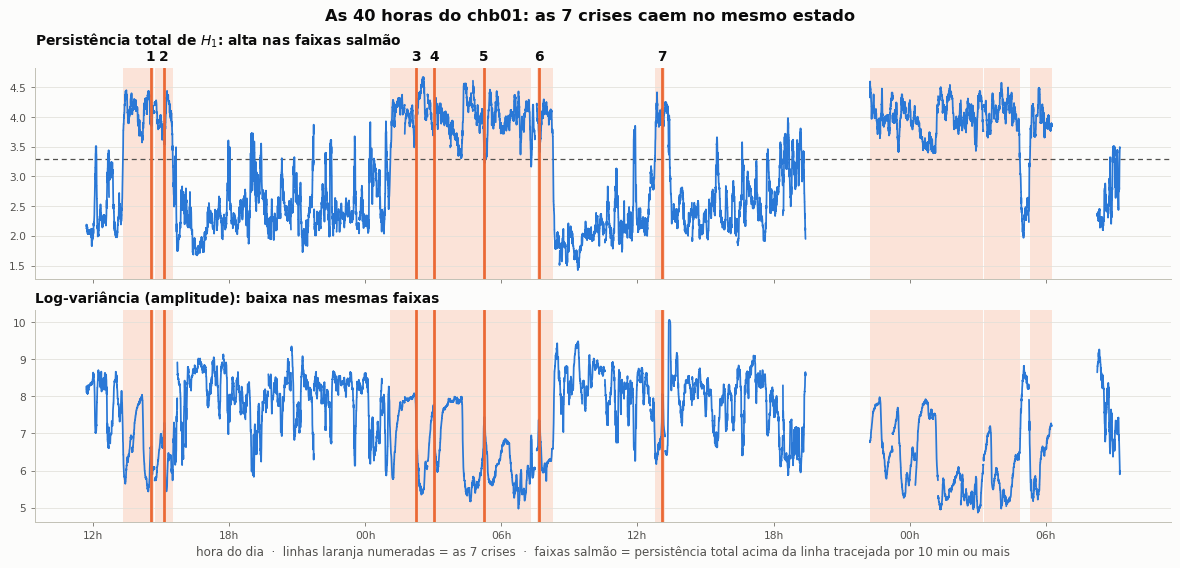

In [54]:
LIMIAR_ESTADO = 3.3        # persistência total (mediana móvel de 5 min) acima disto = "estado lento"

if RODAR_MULTIPACIENTE:
    partes = []
    for g in gravs_multi["chb01"]:
        sub = dfx[dfx.gravacao == g.nome].sort_values("t_ini")
        partes.append(sub.assign(pt5=sub.h1_pers_total.rolling(75, center=True, min_periods=20).median(),
                                 lv5=sub.log_variancia.rolling(75, center=True, min_periods=20).median()))
    d40 = pd.concat(partes)
    d40["estado"] = d40.pt5 > LIMIAR_ESTADO
    crises_40 = [g.inicio_abs + a for g in gravs_multi["chb01"] for a, _ in g.crises]
    frac = float(d40.estado.mean())
    # uma crise está "no estado" se a maior parte dos 5 min em torno dela está acima do limiar
    no_estado = sum(d40[(d40.t_abs + JANELA_S / 2 - c).abs() < 300].estado.mean() > 0.5 for c in crises_40)
    print(f"O estado ocupa {100 * frac:.0f} % das janelas; {no_estado} das {len(crises_40)} crises caem nele. "
          f"Se as crises caíssem ao acaso, a chance disso seria {100 * frac ** no_estado:.1f} %.")

    h0 = 11 + 42 / 60 + 54 / 3600          # a primeira gravação começa às 11:42:54 (chb01-summary.txt)
    fig, eixos = plt.subplots(2, 1, figsize=(13, 6.2), sharex=True, constrained_layout=True)
    for ax, (col, titulo) in zip(eixos, [("pt5", "Persistência total de $H_1$: alta nas faixas salmão"),
                                         ("lv5", "Log-variância (amplitude): baixa nas mesmas faixas")]):
        for g in gravs_multi["chb01"]:
            sub = d40[d40.gravacao == g.nome]
            hrs = (sub.t_abs + JANELA_S / 2).to_numpy() / 3600
            ax.plot(hrs, sub[col], color=AZUL, lw=1.4, zorder=2)
            bordas = np.flatnonzero(np.diff(np.r_[0, sub.estado.to_numpy().astype(int), 0]))
            for a_, b_ in zip(bordas[::2], bordas[1::2]):
                if b_ - a_ >= 150:                              # só desenha trechos de 10 min ou mais
                    ax.axvspan(hrs[a_], hrs[min(b_, len(hrs)) - 1], color=FAIXA_CRISE, lw=0, zorder=0)
        for c in crises_40:
            ax.axvline(c / 3600, color=LARANJA, lw=2.2, zorder=3)
        ax.set_title(titulo, pad=18 if col == "pt5" else 6)
        ax.grid(axis="x", visible=False)
    for k, c in enumerate(crises_40, 1):
        eixos[0].text(c / 3600, 1.02, str(k), transform=eixos[0].get_xaxis_transform(), ha="center", va="bottom",
                      fontsize=11, fontweight="bold")
    eixos[0].axhline(LIMIAR_ESTADO, color=TINTA_2, lw=1, ls=(0, (4, 3)), zorder=1)
    marcas = np.arange(np.ceil(h0 / 6) * 6, h0 + d40.t_abs.max() / 3600, 6)          # de 6 em 6 h de relógio
    eixos[1].set_xticks(marcas - h0, [f"{int(t % 24):02d}h" for t in marcas])
    eixos[1].set_xlabel("hora do dia  ·  linhas laranja numeradas = as 7 crises  ·  faixas salmão = persistência total "
                        "acima da linha tracejada por 10 min ou mais")
    fig.suptitle("As 40 horas do chb01: as 7 crises caem no mesmo estado")
    plt.show()

**O que observar.** As sete linhas laranja caem dentro das faixas salmão. O estado ocupa 46 % do tempo; se as crises caíssem ao acaso, a chance de as sete caírem nele seria de 0,5 %. As faixas longas são as duas noites e as curtas ficam no início da tarde. **Sono é a hipótese mais plausível**, mas não há hipnograma para confirmar.

Isso muda a leitura da Seção 5.4, sem contradizê-la. A persistência total acompanha um estado do cérebro em que as crises *deste paciente* acontecem; ela não marca a crise. Dentro do estado, o trecho da crise não se destaca (AUROC de 0,47 contra o interictal das mesmas gravações, Seção 11.2). E no chb02 há um platô igual, de madrugada, sem nenhuma crise dentro: as três crises dele são de dia.

**Experimente.** Troque `LIMIAR_ESTADO` por 3,0 ou 3,6: a fração do tempo muda, mas as sete crises continuam dentro.

### 11.5 A tarefa supervisionada, como o enunciado define

O enunciado (seção "Definição supervisionada: amostras, rótulos e output") fixa o que é uma amostra, o que é o rótulo e como avaliar. O que foi adotado aqui:

| Item do enunciado | Neste projeto |
|---|---|
| **Unidade amostral**: janela com paciente, arquivo, canal e intervalo absoluto | uma linha de `dfx`: `paciente`, `gravacao`, `canal`, `t_ini`, `t_fim`, `t_abs` |
| **Entrada $X$**: descritores do diagrama de $H_1$ | os 15 de `COLUNAS_TOPO`; baseline sem TDA em `COLUNAS_BASE` |
| **$y=1$**: janela **totalmente contida** na crise anotada | idem (nas seções anteriores a regra era "pelo menos metade") |
| **$y=0$**: interictal **suficientemente afastado** das crises | a pelo menos **1 h** de qualquer crise do paciente |
| Janelas que cruzam o início ou o fim da crise | **sem rótulo**: fora do treino e das métricas por janela, mas recebem escore |
| **Três classes**: horizonte $T_{pre}$ e exclusão $T_{excl}$ | pré-ictal = janela contida em $[t_s - 600\text{ s},\; t_s)$, isto é, $T_{pre}=600$ s e $T_{excl}=0$ |
| **Saída** | escore e classe (crise / não crise) por janela; na extensão, 3 probabilidades e a classe prevista |
| **Treino e avaliação** | deixa-um-paciente-fora, e teste cronológico dentro do paciente |
| **Métricas** | AUROC, AUPRC e prevalência por janela; sensibilidade por crise, atraso de detecção e alarmes falsos por hora |

Essas regras são uma escolha operacional do projeto, fixada antes de olhar os resultados; não são um rótulo clínico.

In [55]:
AFASTAMENTO_S = 3600.0            # interictal "suficientemente afastado": a 1 h ou mais de qualquer crise
T_PRE, T_EXCL = HORIZONTE_PRE_S, 0.0
CLASSES3 = ["interictal", "pre-ictal", "ictal"]


def crises_do_paciente(gravacoes):
    """[(nome, gravação, início, fim)] na linha do tempo do paciente, em ordem cronológica."""
    return sorted(((f"{g.nome}@{int(a)}s", g.nome, g.inicio_abs + a, g.inicio_abs + b)
                   for g in gravacoes for a, b in g.crises), key=lambda c: c[2])


def rotular_supervisionado(dfx, gravs_multi):
    dfx = dfx.sort_values(["paciente", "t_abs"]).reset_index(drop=True)
    a = dfx.t_abs.to_numpy()
    b = a + JANELA_S
    y = np.full(len(dfx), np.nan)
    c3 = np.full(len(dfx), None, dtype=object)
    for pac, gravacoes in gravs_multi.items():
        m = (dfx.paciente == pac).to_numpy()
        dist = np.full(len(dfx), np.inf)                 # distância da janela à crise mais próxima
        dentro = np.zeros(len(dfx), bool)
        pre = np.zeros(len(dfx), bool)
        for _, _, ts, te in crises_do_paciente(gravacoes):
            dist = np.minimum(dist, np.maximum.reduce([ts - b, a - te, np.zeros(len(dfx))]))
            dentro |= (a >= ts) & (b <= te)              # totalmente contida na crise
            pre |= (a >= ts - T_PRE) & (b <= ts - T_EXCL)
        longe = dist >= AFASTAMENTO_S
        y[m & dentro], y[m & longe] = 1, 0
        c3[m & longe] = "interictal"
        c3[m & pre & ~dentro] = "pre-ictal"
        c3[m & dentro] = "ictal"
    dfx["y_det"], dfx["classe3"] = y, c3
    ordem = {g.nome: i for gs in gravs_multi.values() for i, g in enumerate(gs)}
    dfx["ordem_grav"] = dfx.gravacao.map(ordem)          # posição cronológica da gravação no paciente
    return dfx


if RODAR_MULTIPACIENTE:
    dfx = rotular_supervisionado(dfx, gravs_multi)
    display(dfx.groupby("paciente").agg(
        ictal=("y_det", lambda v: int((v == 1).sum())),
        interictal_afastado=("y_det", lambda v: int((v == 0).sum())),
        pre_ictal=("classe3", lambda v: int((v == "pre-ictal").sum())),
        sem_rotulo=("classe3", lambda v: int(v.isna().sum()))))

,ictal,interictal_afastado,pre_ictal,sem_rotulo
paciente,,,,
chb01,100,26221,976,9157
chb02,38,13599,442,3240
chb03,53,3044,531,3564


**O que observar.** A regra estrita reduz as janelas ictais de 219 para 191 (as que cruzam a borda da crise saem). A exigência de 1 h de distância tira muito interictal do chb03, que tem uma crise por hora nas quatro primeiras gravações: sobra o trecho que começa no meio da gravação 05.

### 11.6 Detecção: por paciente e em ordem cronológica

Duas formas de separar treino e teste, as duas com gravações inteiras de cada lado (não há janelas sobrepostas entre as partições):

- **Entre pacientes** (deixa-um-paciente-fora): o modelo nunca viu o paciente em que é testado.
- **Cronológica, no mesmo paciente**: treino nas gravações até a que contém a crise de número $\lfloor n/2 \rfloor$; teste nas gravações posteriores.

O modelo é a regressão logística da Seção 6, com hiperparâmetros fixos. Para as métricas por evento é preciso um limiar, e ele é **fixado no treino**: o valor que deixa passar 1 % (ou 0,1 %) das janelas negativas de treino. Com passo de 4 s, 1 % equivale a cerca de 9 janelas positivas por hora.

- **Sensibilidade por crise**: a crise conta como detectada se alguma janela que a toca passa do limiar.
- **Atraso de detecção**: tempo entre o início anotado e o fim da primeira janela que dispara.
- **Alarmes falsos por hora**: sequências de janelas interictais acima do limiar, por hora de interictal.

In [56]:
FPRS_TREINO = (0.01, 0.001)
CONJUNTOS_SUP = {
    "Topológico H1": COLUNAS_TOPO,
    "Clássico: só forma": COLUNAS_FORMA,
    "Clássico: forma + amplitude": COLUNAS_BASE,
    "Topológico + clássico": COLUNAS_TOPO + COLUNAS_BASE,
}


def particoes(dfx, gravs_multi):
    """(esquema, paciente testado, máscara de treino, máscara de teste)."""
    saida = []
    for pac in gravs_multi:
        teste = (dfx.paciente == pac).to_numpy()
        saida.append(("entre pacientes", pac, ~teste, teste))
    for pac, gravacoes in gravs_multi.items():
        cs = crises_do_paciente(gravacoes)
        ultima = dfx.loc[dfx.gravacao == cs[len(cs) // 2 - 1][1], "ordem_grav"].iloc[0]
        m = (dfx.paciente == pac).to_numpy()
        saida.append(("cronológica", pac, m & (dfx.ordem_grav <= ultima).to_numpy(),
                      m & (dfx.ordem_grav > ultima).to_numpy()))
    return saida


def metricas_por_evento(dfx, teste, s, limiar, crises_pac):
    sub, alarme = dfx[teste], s[teste] >= limiar
    neg = (sub.y_det == 0).to_numpy()
    horas = neg.sum() * PASSO_S / 3600
    falsos = sum(sequencias(alarme[m] & neg[m])
                 for m in [(sub.gravacao == g).to_numpy() for g in sub.gravacao.unique()])
    a = sub.t_abs.to_numpy()
    b = a + JANELA_S
    atrasos = []                                          # um por crise do teste; NaN = não detectada
    for _, grav, ts, te in crises_pac:
        if grav in set(sub.gravacao):
            hit = np.flatnonzero((a < te) & (b > ts) & alarme)
            atrasos.append(float(b[hit[0]] - ts) if len(hit) else np.nan)
    det = int(np.isfinite(atrasos).sum())
    return {"detalhe": tuple(bool(np.isfinite(a_)) for a_ in atrasos),      # crise a crise, em ordem cronológica
            "crises detectadas": f"{det}/{len(atrasos)}",
            "atraso mediano (s)": float(np.nanmedian(atrasos)) if det else np.nan,
            "alarmes falsos/h": falsos / horas}


def avaliar_deteccao(dfx, gravs_multi):
    y = dfx.y_det.to_numpy()
    rot = np.isfinite(y)
    linhas = []
    for esquema, pac, treino, teste in particoes(dfx, gravs_multi):
        tr, te = treino & rot, teste & rot
        n1, n0 = int((y[tr] == 1).sum()), int((y[tr] == 0).sum())
        if n1 == 0 or n0 == 0:
            # sem as duas classes no treino não há modelo; fica registrado em vez de contornado
            print(f"  {esquema}, {pac}: não avaliável (treino com {n1} janelas ictais e {n0} interictais afastadas)")
            continue
        for nome_c, cols in CONJUNTOS_SUP.items():
            X = dfx[cols].to_numpy(float)
            m = clone(modelos()["Regressão logística"]).fit(X[tr], y[tr])
            s = np.full(len(dfx), np.nan)
            s[teste] = m.predict_proba(X[teste])[:, 1]
            neg_treino = m.predict_proba(X[tr & (y == 0)])[:, 1]
            base = {"esquema": esquema, "paciente testado": pac, "descritores": nome_c,
                    "ictais no teste": int(y[te].sum()), "prevalência": y[te].mean(),
                    "AUROC": roc_auc_score(y[te], s[te]), "AUPRC": average_precision_score(y[te], s[te])}
            for fpr in FPRS_TREINO:
                limiar = float(np.quantile(neg_treino, 1 - fpr))
                linhas.append({**base, "FP no treino": f"{100 * fpr:g} %",
                               **metricas_por_evento(dfx, teste, s, limiar, crises_do_paciente(gravs_multi[pac]))})
    return pd.DataFrame(linhas)


if RODAR_MULTIPACIENTE:
    tab_sup = avaliar_deteccao(dfx, gravs_multi)
    display(tab_sup.drop(columns="detalhe").set_index(["esquema", "paciente testado", "descritores", "FP no treino"]).round(3))

  cronológica, chb03: não avaliável (treino com 26 janelas ictais e 0 interictais afastadas)


ictais no teste  prevalência  AUROC  AUPRC crises detectadas  atraso mediano (s)  alarmes falsos/h
esquema         paciente testado descritores                 FP no treino                                                                                                    
entre pacientes chb01            Topológico H1               1 %                       100        0.004  0.744  0.011               2/7                47.5             5.560
                                                             0.1 %                     100        0.004  0.744  0.011               1/7                86.0             0.755
                                 Clássico: só forma          1 %                       100        0.004  0.861  0.015               1/7                17.0             4.256
                                                             0.1 %                     100        0.004  0.861  0.015               0/7                 NaN             0.309
                                 Clássico: forma + amplitude 1 %                       100        0.004  0.990  0.638               6/7                 8.5            21.487
                                                             0.1 %                     100        0.004  0.990  0.638               6/7                22.5             0.927
                                 Topológico + clássico       1 %                       100        0.004  0.998  0.814               7/7                 6.0            32.402
                                                             0.1 %                     100        0.004  0.998  0.814               7/7                12.0             1.888
                chb02            Topológico H1               1 %                        38        0.003  0.605  0.004               1/3                72.0            11.780
                                                             0.1 %                      38        0.003  0.605  0.004               0/3                 NaN             0.662
                                 Clássico: só forma          1 %                        38        0.003  0.850  0.011               2/3                23.0            20.649
                                                             0.1 %                      38        0.003  0.850  0.011               0/3                 NaN             2.713
                                 Clássico: forma + amplitude 1 %                        38        0.003  0.989  0.182               3/3                14.0             6.089
                                                             0.1 %                      38        0.003  0.989  0.182               2/3                33.0             1.257
                                 Topológico + clássico       1 %                        38        0.003  0.995  0.387               3/3                14.0             6.750
                                                             0.1 %                      38        0.003  0.995  0.387               3/3                16.0             1.324
                chb03            Topológico H1               1 %                        53        0.017  0.534  0.018               0/4                 NaN            13.601
                                                             0.1 %                      53        0.017  0.534  0.018               0/4                 NaN             2.365
                                 Clássico: só forma          1 %                        53        0.017  0.673  0.037               1/4                 9.0             5.913
                                                             0.1 %                      53        0.017  0.673  0.037               0/4                 NaN             0.887
                                 Clássico: forma + amplitude 1 %                        53        0.017  0.998  0.970               4/4                 8.5             0.000
                                                             0.1 %       

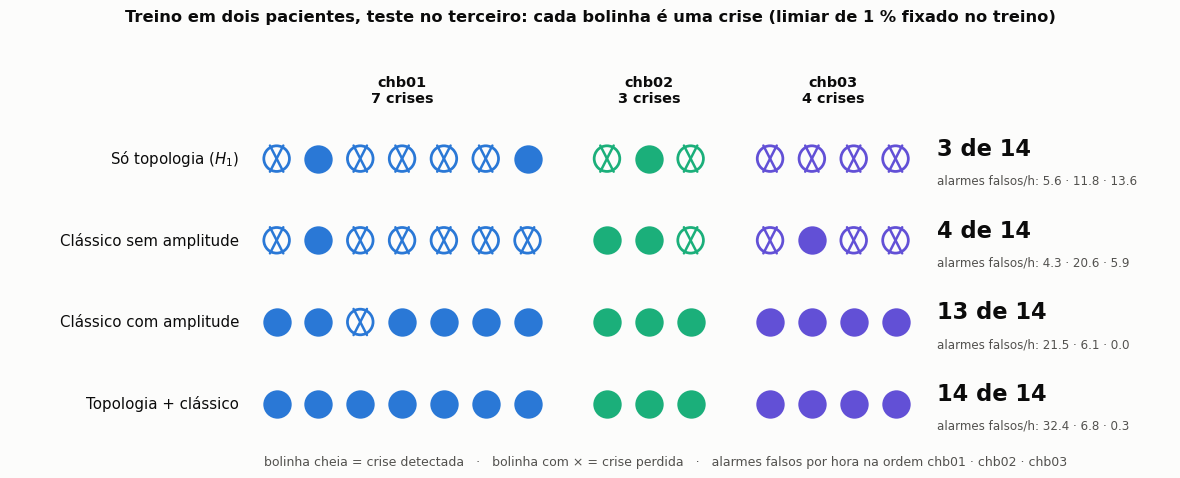

In [57]:
if RODAR_MULTIPACIENTE:
    # uma bolinha por crise, no teste entre pacientes com limiar de 1 %
    ponto = tab_sup[(tab_sup.esquema == "entre pacientes") & (tab_sup["FP no treino"] == "1 %")]
    rotulos = {"Topológico H1": "Só topologia ($H_1$)", "Clássico: só forma": "Clássico sem amplitude",
               "Clássico: forma + amplitude": "Clássico com amplitude", "Topológico + clássico": "Topologia + clássico"}
    x, pac_x, pos = [], [], 0.0
    for p in PACIENTES:
        n_p = sum(len(g.crises) for g in gravs_multi[p])
        x += [pos + k for k in range(n_p)]
        pac_x += [p] * n_p
        pos += n_p + 0.9
    x = np.array(x)

    fig, ax = plt.subplots(figsize=(13, 5.2), constrained_layout=True)
    for j, (chave, rot) in enumerate(rotulos.items()):
        yj = len(rotulos) - 1 - j
        sub = ponto[ponto.descritores == chave].set_index("paciente testado")
        ok = np.concatenate([sub.loc[p, "detalhe"] for p in PACIENTES]).astype(bool)
        for xi, p, d in zip(x, pac_x, ok):
            ax.scatter(xi, yj, s=420, facecolor=COR_PAC[p] if d else "none", edgecolor=COR_PAC[p], linewidths=2.2, zorder=3)
            if not d:                                           # crise perdida: bolinha vazia com um xis
                ax.plot([xi - 0.16, xi + 0.16], [yj - 0.16, yj + 0.16], color=COR_PAC[p], lw=2, zorder=4)
                ax.plot([xi - 0.16, xi + 0.16], [yj + 0.16, yj - 0.16], color=COR_PAC[p], lw=2, zorder=4)
        ax.text(x.max() + 1.0, yj + 0.12, f"{ok.sum()} de {len(ok)}", ha="left", va="center", fontsize=18, fontweight="bold")
        ax.text(x.max() + 1.0, yj - 0.27, "alarmes falsos/h: " + " · ".join(
            f"{sub.loc[p, 'alarmes falsos/h']:.1f}" for p in PACIENTES), ha="left", va="center", fontsize=9.5, color=TINTA_2)
        ax.text(x.min() - 0.9, yj, rot, ha="right", va="center", fontsize=12)
    for p in PACIENTES:
        m = np.array([q == p for q in pac_x])
        ax.text(x[m].mean(), len(rotulos) - 0.35, f"{p}\n{m.sum()} crises", ha="center", va="bottom", fontsize=11.5,
                fontweight="bold")
    ax.set_xlim(x.min() - 6.4, x.max() + 6.6)
    ax.set_ylim(-0.75, len(rotulos) + 0.55)
    ax.axis("off")
    ax.text(x.min() - 0.3, -0.72, "bolinha cheia = crise detectada   ·   bolinha com × = crise perdida   ·   "
            "alarmes falsos por hora na ordem chb01 · chb02 · chb03", fontsize=10, color=TINTA_2, va="center")
    fig.suptitle("Treino em dois pacientes, teste no terceiro: cada bolinha é uma crise (limiar de 1 % fixado no treino)")
    plt.show()

**O que observar.**

- **Só com a topologia**, 3 das 14 crises são detectadas no ponto de 1 % e 1 no de 0,1 %.
- **O clássico com amplitude** detecta 13 das 14 no ponto de 1 % e 12 no de 0,1 %, com atraso mediano de 9 e de 21 s.
- **A AUROC por janela engana.** O clássico completo tem AUROC de 0,99 no chb01 e, mesmo assim, dispara mais de 20 alarmes falsos por hora no ponto de 1 %: o limiar foi calibrado nos outros dois pacientes, e a amplitude do EEG muda de pessoa para pessoa. Por isso o enunciado pede métricas por evento.
- **Somando a topologia ao clássico**, as 14 crises são detectadas nos dois pontos de operação, e a AUPRC sobe nos três pacientes. Em troca, os alarmes falsos do chb01 sobem. Esse ganho merece um controle, que vem a seguir.
- **No teste cronológico do chb01** (treino nas 3 primeiras crises, teste nas 4 seguintes), a topologia detecta 2 das 4 e o clássico detecta as 4.
- **O teste cronológico do chb03 não pôde ser feito** com a regra de 1 h: as duas gravações de treino têm crise e nenhuma janela delas fica a 1 h de uma crise. Está registrado como limitação, e não contornado afrouxando a regra depois de ver os dados.

**O ganho de somar a topologia é real?** Juntar 15 colunas a um modelo pode melhorar o resultado só por acaso. O controle abaixo refaz o teste entre pacientes com os descritores de $H_1$ **embaralhados** dentro de cada paciente: as colunas continuam lá, com a mesma distribuição, mas sem relação com a janela. Se o ganho viesse só do número de colunas, a versão embaralhada ganharia o mesmo.

In [58]:
def controle_embaralhado(dfx, n_rep=10):
    """AUPRC entre pacientes: baseline, baseline + topologia e baseline + topologia embaralhada."""
    y = dfx.y_det.to_numpy()
    rot = np.isfinite(y)
    XB, XT = dfx[COLUNAS_BASE].to_numpy(float), dfx[COLUNAS_TOPO].to_numpy(float)

    def auprc(X):
        saida = {}
        for pac in PACIENTES:
            teste = (dfx.paciente == pac).to_numpy()
            m = clone(modelos()["Regressão logística"]).fit(X[~teste & rot], y[~teste & rot])
            saida[pac] = average_precision_score(y[teste & rot], m.predict_proba(X[teste & rot])[:, 1])
        return saida

    base, com_topo = auprc(XB), auprc(np.c_[XB, XT])
    rng = np.random.default_rng(SEMENTE)
    reps = []
    for _ in range(n_rep):
        XS = XT.copy()
        for pac in PACIENTES:                                # permuta as linhas dentro do paciente
            idx = np.flatnonzero((dfx.paciente == pac).to_numpy())
            XS[idx] = XT[rng.permutation(idx)]
        reps.append(auprc(np.c_[XB, XS]))
    reps = pd.DataFrame(reps)
    return pd.DataFrame({"clássico": base, "clássico + topologia": com_topo,
                         f"clássico + topologia embaralhada (média de {n_rep})": reps.mean(),
                         f"clássico + topologia embaralhada (máximo de {n_rep})": reps.max()}).T


if RODAR_MULTIPACIENTE:
    display(controle_embaralhado(dfx).round(3))

,chb01,chb02,chb03
clássico,0.638,0.182,0.970
clássico + topologia,0.814,0.387,0.990
clássico + topologia embaralhada (média de 10),0.536,0.185,0.966
clássico + topologia embaralhada (máximo de 10),0.595,0.203,0.971


**O que observar.** Com a topologia verdadeira, a AUPRC sobe nos três pacientes (de 0,64 para 0,81 no chb01, de 0,18 para 0,39 no chb02, de 0,97 para 0,99 no chb03). Com a topologia embaralhada, não sobe: nem a melhor das repetições chega perto do ganho real. O ganho não é efeito de ter mais colunas.

A conclusão fica com duas partes. **Sozinha, a topologia não serve de detector** (3 de 14 crises). **Somada ao baseline, ela não é redundante**: traz alguma informação que os descritores clássicos não têm. Com 14 crises, isso é um indício a conferir com mais pacientes, não um resultado fechado.

### 11.7 Extensão: três classes

A mesma validação entre pacientes, agora com saída de três probabilidades (interictal, pré-ictal, ictal) e a classe prevista. Detectar uma crise em curso não é o mesmo que antecipá-la: a pergunta desta tabela é se a classe pré-ictal tem algum sinal que se transfira de um paciente para outro.

In [59]:
def avaliar_tres_classes(dfx, colunas):
    c3 = dfx.classe3.to_numpy()
    rot = pd.notna(c3)
    X = dfx[colunas].to_numpy(float)
    proba = np.full((len(dfx), 3), np.nan)
    for pac in PACIENTES:                                   # deixa-um-paciente-fora
        teste = (dfx.paciente == pac).to_numpy()
        m = make_pipeline(StandardScaler(),
                          LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000)).fit(X[~teste & rot], c3[~teste & rot])
        proba[teste] = m.predict_proba(X[teste])[:, [list(m.classes_).index(c) for c in CLASSES3]]
    prevista = np.array(CLASSES3, dtype=object)[np.argmax(proba, axis=1)]
    return rot, c3, proba, prevista


if RODAR_MULTIPACIENTE:
    linhas, matrizes = [], {}
    for nome_c in ("Topológico H1", "Clássico: forma + amplitude", "Topológico + clássico"):
        rot, c3, proba, prevista = avaliar_tres_classes(dfx, CONJUNTOS_SUP[nome_c])
        for pac in PACIENTES:
            m = rot & (dfx.paciente == pac).to_numpy()
            linhas.append({"descritores": nome_c, "paciente testado": pac,
                           "acurácia balanceada": balanced_accuracy_score(c3[m], prevista[m]),
                           **{f"AUROC {ROTULO_CLASSE[c]} × resto": roc_auc_score(c3[m] == c, proba[m, j])
                              for j, c in enumerate(CLASSES3)}})
        matrizes[nome_c] = pd.DataFrame(confusion_matrix(c3[rot].astype(str), prevista[rot].astype(str), labels=CLASSES3),
                                        index=[f"verdade: {ROTULO_CLASSE[c]}" for c in CLASSES3],
                                        columns=[f"previsto: {ROTULO_CLASSE[c]}" for c in CLASSES3])
    display(pd.DataFrame(linhas).set_index(["descritores", "paciente testado"]).round(2))
    print("Matriz de confusão do modelo topológico (os três pacientes somados):")
    display(matrizes["Topológico H1"])
    print("Matriz de confusão do modelo clássico com amplitude:")
    display(matrizes["Clássico: forma + amplitude"])

acurácia balanceada  AUROC interictal × resto  AUROC pré-ictal × resto  AUROC ictal × resto
descritores                 paciente testado                                                                                             
Topológico H1               chb01                            0.31                      0.33                     0.27                 0.76
                            chb02                            0.34                      0.39                     0.46                 0.60
                            chb03                            0.29                      0.31                     0.44                 0.56
Clássico: forma + amplitude chb01                            0.57                      0.46                     0.34                 0.99
                            chb02                            0.53                      0.51                     0.32                 0.99
                            chb03                            0.61                      0.50                     0.39                 0.99
Topológico + clássico       chb01                            0.56                      0.47                     0.32                 1.00
                            chb02                            0.53                      0.47                     0.32                 0.99
                            chb03                            0.62                      0.48                     0.41                 1.00

Matriz de confusão do modelo topológico (os três pacientes somados):


,previsto: interictal,previsto: pré-ictal,previsto: ictal
verdade: interictal,10614,18122,14128
verdade: pré-ictal,876,304,769
verdade: ictal,38,50,103


Matriz de confusão do modelo clássico com amplitude:


,previsto: interictal,previsto: pré-ictal,previsto: ictal
verdade: interictal,18464,22997,1403
verdade: pré-ictal,1090,632,227
verdade: ictal,2,15,174


**O que observar.** A acurácia balanceada do acaso com três classes é 0,33, e o modelo topológico fica entre 0,29 e 0,34. O clássico chega a 0,53 a 0,61 porque acerta a classe ictal (AUROC de 0,99), não porque reconheça o pré-ictal.

Na coluna **pré-ictal × resto**, todos os valores ficam *abaixo* de 0,5 (de 0,27 a 0,46). Isso não é um sinal invertido aproveitável: o que o modelo aprende como "pré-ictal" em dois pacientes aponta na direção oposta no terceiro. Os 10 minutos antes de uma crise diferem do interictal afastado por razões que mudam de paciente para paciente, como o estado da Seção 11.4. **Não há evidência de antecipação** nestes dados, nem com topologia nem com o baseline.

## 12. Conclusões e limitações

### O que encontramos

1. **O método funciona onde deveria.** Em sinais sintéticos, periodicidade vira um ciclo persistente em $H_1$, e o ciclo some de forma gradual quando o ruído chega ao nível do sinal (Seção 1.4).
2. **No EEG real, $H_1$ quase não reage à crise.** A persistência máxima separa janelas ictais de interictais com AUROC de 0,60, e o trecho ictal é tão "extremo" quanto um trecho interictal qualquer (Seções 5.3 e 5.5).
3. **O que parecia sinal era efeito de gravação.** Persistência total, entropia e paisagens acompanham um estado lento de cerca de duas horas que contém as duas crises. Com a referência local, a separação desaparece (Seção 5.4).
4. **Um baseline simples ganha com folga.** Descritores clássicos de amplitude e forma detectam as duas crises com 0,15 alarme falso por hora; os topológicos precisam de cerca de 17 (Seção 6).
5. **A conclusão é robusta** ao canal, a $(d,\tau)$, ao modelo e ao tipo de análise (Seções 6 a 9).
6. **E se repete em outros pacientes.** Em três pacientes e 14 crises, a persistência máxima fica entre os percentis 10 e 64 do interictal em todas as crises, e a log-variância entre 95 e 100. Treinando em dois pacientes e testando no terceiro, o modelo topológico detecta 3 das 14 crises; o clássico detecta 13 (Seção 11).
7. **O "estado lento" é um estado do cérebro, não a crise.** Nas 40 horas do chb01 ele ocupa 46 % do tempo, aparece à noite e no início da tarde, e contém as 7 crises do paciente. No chb02 há um estado igual sem nenhuma crise (Seção 11.4).
8. **Sozinha, a topologia não detecta; somada ao baseline, acrescenta um pouco.** Com os descritores de $H_1$ juntos aos clássicos, as 14 crises são detectadas e a AUPRC sobe nos três pacientes; com os descritores embaralhados, não (Seção 11.6).

### Por que $H_1$ não funcionou aqui?

- **Ruído.** O ritmo ictal divide a janela com atividade de fundo de potência comparável. Nesse regime a nuvem fica grossa e o buraco do laço não aparece (Seções 1.4 e 5.2).
- **Pontos atípicos.** Sem remoção de artefatos, transientes de grande amplitude criam ciclos espúrios, e a persistência máxima do Rips responde a eles (Seção 5.7).
- **A amplitude foi descartada.** A padronização de cada janela joga fora justamente a característica mais informativa desta crise (Seção 2.3).

### Limitações

- **Três pacientes, 14 crises.** Ainda é pouco: o CHB-MIT tem 24 casos. O resultado negativo vale para estes dados, não para "TDA em EEG" em geral. Do chb03 entraram 4 das 7 crises.
- **Um limiar calibrado em outros pacientes não se transfere bem.** Mesmo o baseline, com AUROC de 0,99, dispara dezenas de alarmes falsos por hora em um paciente novo (Seção 11.6).
- **O teste cronológico do chb03 não foi possível** com interictal a 1 h das crises (Seção 11.6).
- **Sem hipnograma**, não dá para afirmar que o estado lento é sono.
- **Janelas correlacionadas.** Vizinhas se sobrepõem em 50 %; por isso os resultados são dados como AUROC e percentis de blocos, e não como valores-p de testes que supõem independência.
- **"Interictal" frouxo nas Seções 2 a 10.** Ali, tudo o que está fora das faixas pré e pós-ictais conta como interictal. A Seção 11.5 usa a versão estrita (1 h de distância), como o enunciado recomenda.
- **Um canal por vez.** A Seção 9 cobre os outros canais só de forma univariada.
- **Nuvens de 126 pontos.** Ciclos mais finos que essa amostragem não são resolvidos.
- **Sem rejeição de artefatos.**

### Próximos passos naturais

- Remover artefatos antes da imersão, ou usar uma filtração robusta a pontos atípicos (por exemplo, distância à medida) no lugar do Rips puro.
- Estender a análise aos 24 casos do CHB-MIT e a vários canais ao mesmo tempo.
- Calibrar o limiar de alarme por paciente (por exemplo, normalizando os descritores pelo interictal de cada um).
- Sempre reportar a referência local (mesma gravação) ao lado da global.

### Referências

- Shoeb, A. H. (2009). *Application of Machine Learning to Epileptic Seizure Onset Detection and Treatment*. Tese de doutorado, MIT. (Banco CHB-MIT.)
- Goldberger, A. L. et al. (2000). PhysioBank, PhysioToolkit, and PhysioNet. *Circulation*, 101(23), e215–e220.
- Takens, F. (1981). Detecting strange attractors in turbulence. *Lecture Notes in Mathematics*, 898, 366–381.
- Fraser, A. M.; Swinney, H. L. (1986). Independent coordinates for strange attractors from mutual information. *Physical Review A*, 33(2), 1134–1140.
- Kennel, M. B.; Brown, R.; Abarbanel, H. D. I. (1992). Determining embedding dimension for phase-space reconstruction using a geometrical construction. *Physical Review A*, 45(6), 3403–3411.
- Bubenik, P. (2015). Statistical topological data analysis using persistence landscapes. *Journal of Machine Learning Research*, 16, 77–102.
- Singh, G.; Mémoli, F.; Carlsson, G. (2007). Topological methods for the analysis of high dimensional data sets and 3D object recognition. *Eurographics Symposium on Point-Based Graphics*.